In [3]:

print("Welcome to the SmogWatch Project!")
print("My goal is to analyze air pollution in Pakistan.")
print("Cities: Lahore, Karachi, and Islamabad")


Welcome to the SmogWatch Project!
My goal is to analyze air pollution in Pakistan.
Cities: Lahore, Karachi, and Islamabad


In [4]:

!pip -q install pandas numpy matplotlib seaborn plotly requests


In [5]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import requests

print("All libraries imported successfully!")


All libraries imported successfully!


In [6]:

%pip install -q -U kaggle


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.2/126.2 kB 5.3 MB/s eta 0:00:00


In [7]:

import os
from getpass import getpass

os.environ["KAGGLE_API_TOKEN"] = getpass(
    "KGAT_386ffaa1c72f02dc623a1dfce9ce2214: "
)

print("Kaggle token configured for this session.")


KGAT_386ffaa1c72f02dc623a1dfce9ce2214: ··········
Kaggle token configured for this session.


In [8]:

import os
from getpass import getpass

os.environ["KAGGLE_API_TOKEN"] = getpass(
    ": "
)

print("Kaggle credentials configured.")


: ··········
Kaggle credentials configured.


In [9]:
!kaggle datasets list -s "Pakistan air quality"

ref                                                               title                                                   size  lastUpdated                 downloadCount  voteCount  usabilityRating  
----------------------------------------------------------------  ------------------------------------------------  ----------  --------------------------  -------------  ---------  ---------------  
alitaqishah/pakistan-air-quality-index-10-cities-20152025         Pakistan Air Quality Index: 10 Cities, 2015–2025       24306  2026-04-21 14:46:16.887000            391         53                1  
ahsanneural/pakistan-air-quality-and-weather-10-cities            Pakistan Air Quality & Weather (10 Cities)            688869  2026-08-13 07:37:20.853000            548         34        0.8235294  
diraf0/islamabad-pakistan-air-quality-data                        Islamabad, Pakistan Air Quality Data                   46611  2023-07-22 11:39:58.670000            927         11                1  


In [10]:


from pathlib import Path

# Create a folder for the original data
data_folder = Path("/content/SmogWatch/data/raw")
data_folder.mkdir(parents=True, exist_ok=True)

# Download and extract the Kaggle dataset
!kaggle datasets download -d ahsanneural/pakistan-air-quality-and-weather-10-cities -p /content/SmogWatch/data/raw --unzip

print("Dataset download completed!")


Dataset URL: https://www.kaggle.com/datasets/ahsanneural/pakistan-air-quality-and-weather-10-cities
License(s): CC0-1.0
100% 673k/673k [00:00<00:00, 1.47MB/s]

Dataset download completed!


In [11]:

from pathlib import Path

data_folder = Path("/content/SmogWatch/data/raw")

for file in data_folder.rglob("*"):
    if file.is_file():
        print(file.name, "-", round(file.stat().st_size / 1024, 2), "KB")


pakistan_air_quality_final_clean_v2.csv - 3690.79 KB
DATA_QUALITY_REPORT.md - 4.83 KB


In [12]:

import pandas as pd
from pathlib import Path

data_folder = Path("/content/SmogWatch/data/raw")

csv_files = list(data_folder.rglob("*.csv"))

print("CSV files found:", len(csv_files))

for file in csv_files:
    print("\nFile:", file.name)

    df = pd.read_csv(file, nrows=5)

    print("Columns:", df.columns.tolist())
    display(df.head())


CSV files found: 1

File: pakistan_air_quality_final_clean_v2.csv
Columns: ['timestamp', 'city', 'latitude', 'longitude', 'pm10', 'pm2_5', 'carbon_monoxide', 'nitrogen_dioxide', 'sulphur_dioxide', 'ozone', 'dust', 'temperature', 'humidity', 'precipitation', 'wind_speed', 'wind_direction', 'pressure', 'date', 'hour', 'day_of_week', 'month', 'month_name', 'year', 'is_weekend', 'season', 'aqi_category']


,timestamp,city,latitude,longitude,pm10,pm2_5,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone,...,pressure,date,hour,day_of_week,month,month_name,year,is_weekend,season,aqi_category
0,2025-11-06 00:00:00,Faisalabad,31.4504,73.135,23.7,22.6,598.0,15.9,5.0,58.0,...,1013.3,2025-11-06,0,Thursday,11,November,2025,0,Autumn,Moderate
1,2025-11-06 01:00:00,Faisalabad,31.4504,73.135,25.4,24.2,790.0,21.7,5.6,51.0,...,1013.2,2025-11-06,1,Thursday,11,November,2025,0,Autumn,Moderate
2,2025-11-06 02:00:00,Faisalabad,31.4504,73.135,32.2,30.7,1048.0,29.4,6.5,42.0,...,1013.0,2025-11-06,2,Thursday,11,November,2025,0,Autumn,Moderate
3,2025-11-06 03:00:00,Faisalabad,31.4504,73.135,36.2,34.8,1176.0,33.2,7.2,42.0,...,1012.7,2025-11-06,3,Thursday,11,November,2025,0,Autumn,Moderate
4,2025-11-06 04:00:00,Faisalabad,31.4504,73.135,34.7,33.3,1053.0,29.3,7.6,58.0,...,1012.5,2025-11-06,4,Thursday,11,November,2025,0,Autumn,Moderate


In [13]:

import pandas as pd
from pathlib import Path

# Find the downloaded CSV
data_folder = Path("/content/SmogWatch/data/raw")
file_path = data_folder / "pakistan_air_quality_final_clean_v2.csv"

# Load the full dataset
df = pd.read_csv(file_path)

# Convert timestamp into a proper datetime format
df["timestamp"] = pd.to_datetime(
    df["timestamp"], errors="coerce"
)

print("DATASET OVERVIEW")
print("-" * 40)

print("Total rows:", len(df))
print("Total columns:", len(df.columns))
print("Cities:", sorted(df["city"].dropna().unique()))
print("Number of cities:", df["city"].nunique())

print("\nDATE COVERAGE")
print("First date:", df["timestamp"].min())
print("Last date:", df["timestamp"].max())

print("\nMISSING VALUES")
print(df.isnull().sum())

print("\nDUPLICATE ROWS")
print(df.duplicated().sum())

print("\nDATA TYPES")
print(df.dtypes)


DATASET OVERVIEW
----------------------------------------
Total rows: 21840
Total columns: 26
Cities: ['Faisalabad', 'Islamabad', 'Karachi', 'Lahore', 'Multan', 'Peshawar', 'Quetta', 'Rahim Yar Khan', 'Rawalpindi', 'Sialkot']
Number of cities: 10

DATE COVERAGE
First date: 2025-11-06 00:00:00
Last date: 2026-02-04 23:00:00

MISSING VALUES
timestamp           0
city                0
latitude            0
longitude           0
pm10                0
pm2_5               0
carbon_monoxide     0
nitrogen_dioxide    0
sulphur_dioxide     0
ozone               0
dust                0
temperature         0
humidity            0
precipitation       0
wind_speed          0
wind_direction      0
pressure            0
date                0
hour                0
day_of_week         0
month               0
month_name          0
year                0
is_weekend          0
season              0
aqi_category        0
dtype: int64

DUPLICATE ROWS
0

DATA TYPES
timestamp           datetime64[ns]
city     

In [14]:

# Check for impossible or suspicious values

print("PM2.5 negative values:", (df["pm2_5"] < 0).sum())
print("PM10 negative values:", (df["pm10"] < 0).sum())

print(
    "Humidity outside 0-100%:",
    ((df["humidity"] < 0) | (df["humidity"] > 100)).sum()
)

print(
    "Wind speed negative values:",
    (df["wind_speed"] < 0).sum()
)

print("\nPollution statistics:")
display(df[["pm2_5", "pm10"]].describe())

print("\nRecords per city:")
display(df["city"].value_counts())


PM2.5 negative values: 0
PM10 negative values: 0
Humidity outside 0-100%: 0
Wind speed negative values: 0

Pollution statistics:


,pm2_5,pm10
count,21840.000000,21840.000000
mean,82.968141,88.416575
std,65.742106,66.010440
min,0.500000,0.500000
25%,34.700000,40.500000
50%,62.400000,68.500000
75%,112.500000,117.800000
max,486.200000,488.000000



Records per city:


,count
city,
Faisalabad,2184
Islamabad,2184
Karachi,2184
Lahore,2184
Multan,2184
Peshawar,2184
Quetta,2184
Rahim Yar Khan,2184
Rawalpindi,2184


In [15]:

# Step 12: Check date and hourly coverage

print("Records per city and date range:\n")

coverage = df.groupby("city").agg(
    first_timestamp=("timestamp", "min"),
    last_timestamp=("timestamp", "max"),
    total_records=("timestamp", "count"),
    unique_timestamps=("timestamp", "nunique")
)

display(coverage)

# Check for repeated city/timestamp combinations
duplicate_hours = df.duplicated(
    subset=["city", "timestamp"]
).sum()

print("Duplicate city-hour records:", duplicate_hours)

# Check missing hourly observations
expected_hours = (
    df.groupby("city")["timestamp"]
    .agg(["min", "max"])
)

expected_hours["expected_records"] = (
    (expected_hours["max"] - expected_hours["min"])
    / pd.Timedelta(hours=1)
    + 1
).astype(int)

actual_hours = df.groupby("city").size()

expected_hours["actual_records"] = actual_hours
expected_hours["missing_hours"] = (
    expected_hours["expected_records"]
    - expected_hours["actual_records"]
)

print("\nHourly coverage check:")
display(expected_hours)


Records per city and date range:



,first_timestamp,last_timestamp,total_records,unique_timestamps
city,,,,
Faisalabad,2025-11-06,2026-02-04 23:00:00,2184,2184
Islamabad,2025-11-06,2026-02-04 23:00:00,2184,2184
Karachi,2025-11-06,2026-02-04 23:00:00,2184,2184
Lahore,2025-11-06,2026-02-04 23:00:00,2184,2184
Multan,2025-11-06,2026-02-04 23:00:00,2184,2184
Peshawar,2025-11-06,2026-02-04 23:00:00,2184,2184
Quetta,2025-11-06,2026-02-04 23:00:00,2184,2184
Rahim Yar Khan,2025-11-06,2026-02-04 23:00:00,2184,2184
Rawalpindi,2025-11-06,2026-02-04 23:00:00,2184,2184


Duplicate city-hour records: 0

Hourly coverage check:


,min,max,expected_records,actual_records,missing_hours
city,,,,,
Faisalabad,2025-11-06,2026-02-04 23:00:00,2184,2184,0
Islamabad,2025-11-06,2026-02-04 23:00:00,2184,2184,0
Karachi,2025-11-06,2026-02-04 23:00:00,2184,2184,0
Lahore,2025-11-06,2026-02-04 23:00:00,2184,2184,0
Multan,2025-11-06,2026-02-04 23:00:00,2184,2184,0
Peshawar,2025-11-06,2026-02-04 23:00:00,2184,2184,0
Quetta,2025-11-06,2026-02-04 23:00:00,2184,2184,0
Rahim Yar Khan,2025-11-06,2026-02-04 23:00:00,2184,2184,0
Rawalpindi,2025-11-06,2026-02-04 23:00:00,2184,2184,0


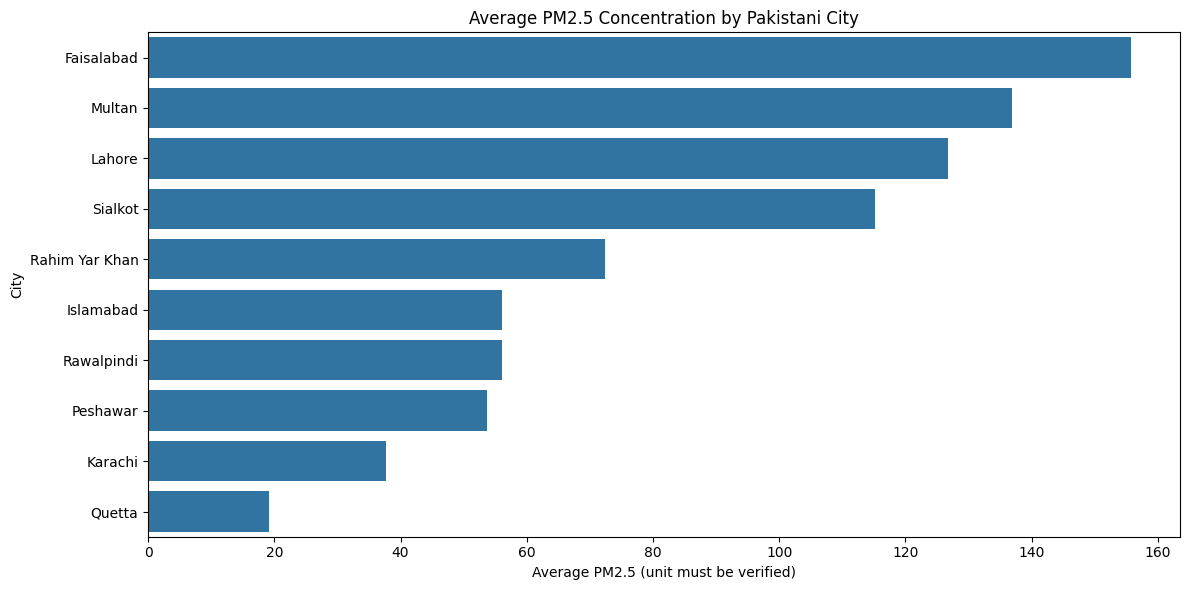

In [16]:

import matplotlib.pyplot as plt
import seaborn as sns

# Calculate average PM2.5 for each city
city_pm25 = (
    df.groupby("city")["pm2_5"]
    .mean()
    .sort_values(ascending=False)
)

# Draw the chart
plt.figure(figsize=(12, 6))

sns.barplot(
    x=city_pm25.values,
    y=city_pm25.index
)

plt.title("Average PM2.5 Concentration by Pakistani City")
plt.xlabel("Average PM2.5 (unit must be verified)")
plt.ylabel("City")
plt.tight_layout()
plt.show()


In [17]:

print("Average PM2.5 by city:")
display(city_pm25.round(2).to_frame(name="Average PM2.5"))


Average PM2.5 by city:


,Average PM2.5
city,
Faisalabad,155.74
Multan,136.83
Lahore,126.76
Sialkot,115.19
Rahim Yar Khan,72.36
Islamabad,56.13
Rawalpindi,56.13
Peshawar,53.73
Karachi,37.71


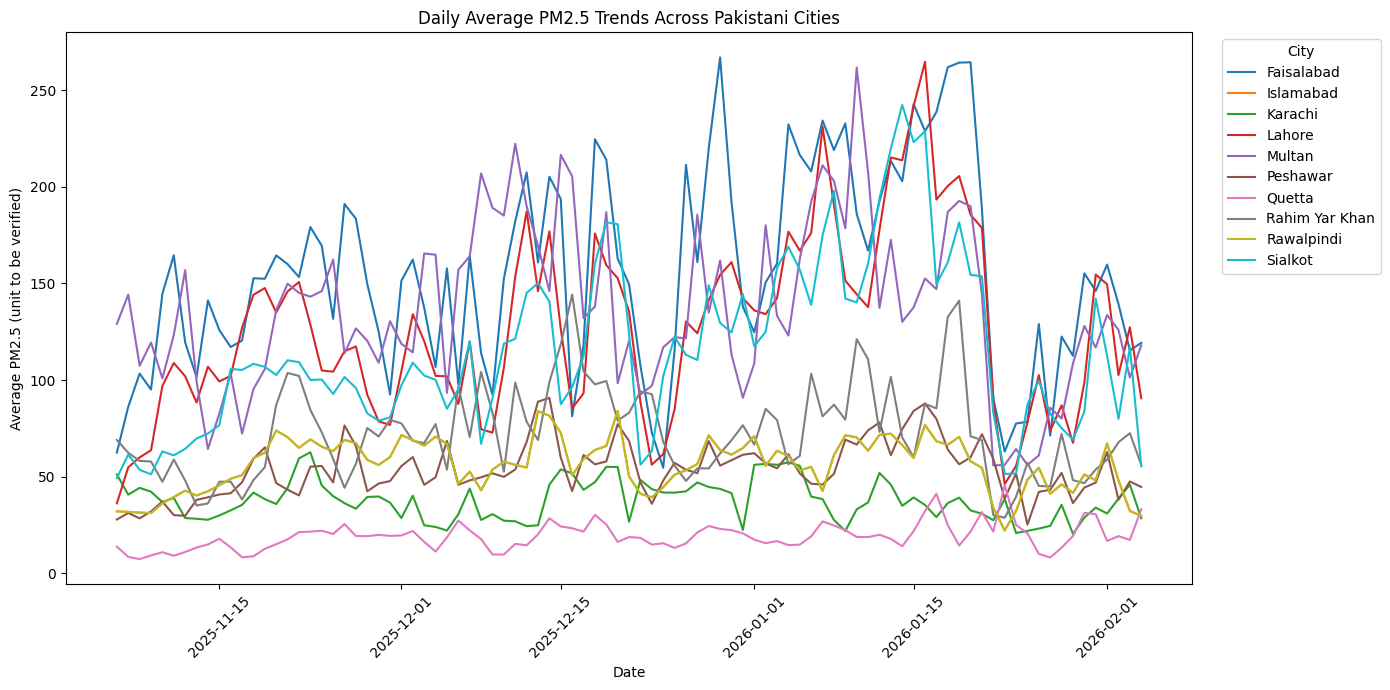

In [18]:

# Convert timestamp to date
df["date"] = pd.to_datetime(df["timestamp"]).dt.date

# Calculate daily average PM2.5 for each city
daily_pm25 = (
    df.groupby(["date", "city"], as_index=False)["pm2_5"]
    .mean()
)

# Draw the time-series chart
plt.figure(figsize=(14, 7))

sns.lineplot(
    data=daily_pm25,
    x="date",
    y="pm2_5",
    hue="city"
)

plt.title("Daily Average PM2.5 Trends Across Pakistani Cities")
plt.xlabel("Date")
plt.ylabel("Average PM2.5 (unit to be verified)")
plt.xticks(rotation=45)
plt.legend(title="City", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


city,Faisalabad,Islamabad,Karachi,Lahore,Multan,Peshawar,Quetta,Rahim Yar Khan,Rawalpindi,Sialkot
month_period,,,,,,,,,,
2025-11,135.46,52.50,39.55,103.49,119.47,44.54,15.17,61.77,52.50,84.14
2025-12,154.07,60.22,37.75,121.32,149.06,57.62,19.35,80.54,60.22,116.12
2026-01,176.64,56.49,36.41,152.16,140.82,57.96,21.72,73.84,56.49,142.41
2026-02,133.39,44.28,35.94,117.51,119.71,48.21,21.55,63.78,44.28,91.19


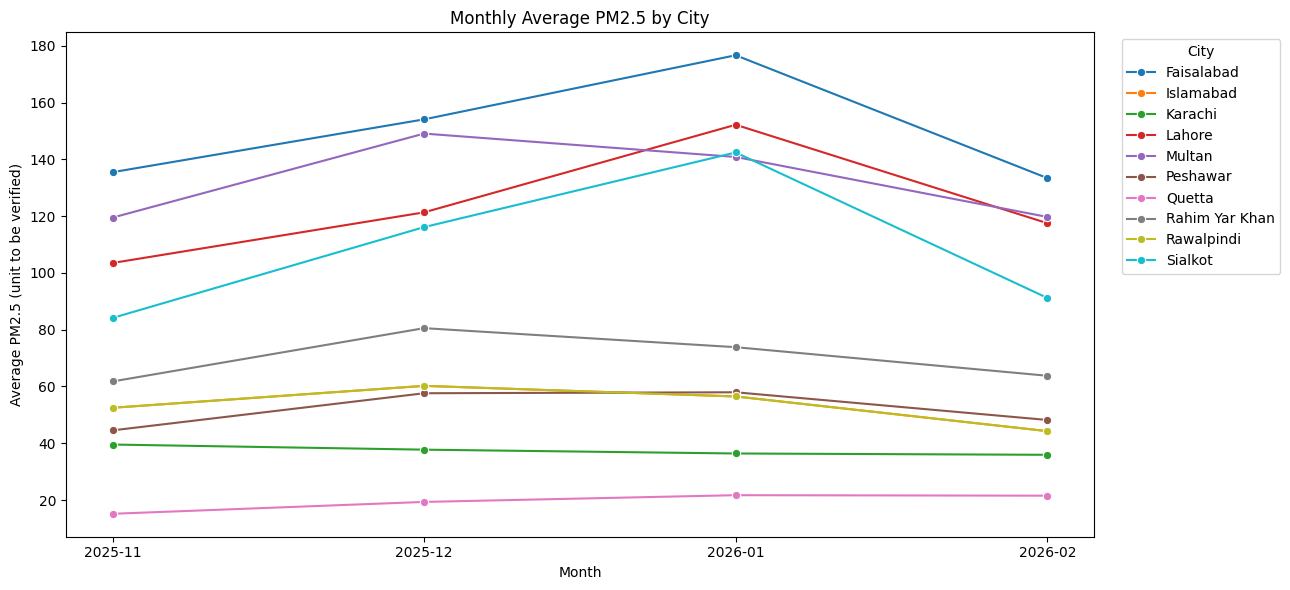

In [19]:

# Create year-month labels
df["month_period"] = pd.to_datetime(df["timestamp"]).dt.to_period("M").astype(str)

# Calculate monthly average PM2.5 by city
monthly_pm25 = (
    df.groupby(["month_period", "city"], as_index=False)["pm2_5"]
    .mean()
)

# Display the results
display(
    monthly_pm25.pivot(
        index="month_period",
        columns="city",
        values="pm2_5"
    ).round(2)
)

# Plot the monthly averages
plt.figure(figsize=(13, 6))

sns.lineplot(
    data=monthly_pm25,
    x="month_period",
    y="pm2_5",
    hue="city",
    marker="o"
)

plt.title("Monthly Average PM2.5 by City")
plt.xlabel("Month")
plt.ylabel("Average PM2.5 (unit to be verified)")
plt.legend(title="City", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


In [20]:

!kaggle datasets list -s "daily PM2.5 Pakistan cities"


ref                                                          title                                                size  lastUpdated                 downloadCount  voteCount  usabilityRating  
-----------------------------------------------------------  ---------------------------------------------  ----------  --------------------------  -------------  ---------  ---------------  
muzammalhussain11/pakistan-six-cities-daily-pm2-5-2025-2026  Pakistan Six Cities Daily PM2.5 2025-2026          326375  2026-10-18 23:54:22.467000             10          8                1  
ailyazainab/daily-pm2-5-air-quality-15-pakistani-cities      Daily PM2.5 Air Quality — 15 Pakistani Cities      206057  2026-07-26 14:13:19.447000             14          2        0.7058824  
muhammadbilal77511/pakistan-sulfur-dioxide-2018-2021         Pakistan Sulfur dioxide 2018-2021              2593642006  2026-02-21 05:49:40.113000             32         25        0.7647059  


In [21]:

from pathlib import Path

candidate_folder = Path("/content/SmogWatch/data/candidate_15_cities")
candidate_folder.mkdir(parents=True, exist_ok=True)

!kaggle datasets download -d ailyazainab/daily-pm2-5-air-quality-15-pakistani-cities -p /content/SmogWatch/data/candidate_15_cities --unzip

# List the downloaded files
for file in candidate_folder.rglob("*"):
    if file.is_file():
        print(file.name, "-", round(file.stat().st_size / 1024, 2), "KB")


Dataset URL: https://www.kaggle.com/datasets/ailyazainab/daily-pm2-5-air-quality-15-pakistani-cities
License(s): CC0-1.0
100% 201k/201k [00:00<00:00, 730kB/s]

pakistan_pm25_15cities_2019_2026.csv - 1027.54 KB


In [22]:

import pandas as pd
from pathlib import Path

candidate_folder = Path("/content/SmogWatch/data/candidate_15_cities")
csv_path = candidate_folder / "pakistan_pm25_15cities_2019_2026.csv"

# Load the candidate dataset
df_candidate = pd.read_csv(csv_path)

# Inspect the data
print("Dataset shape:", df_candidate.shape)

print("\nColumn names:")
print(df_candidate.columns.tolist())

print("\nFirst five rows:")
display(df_candidate.head())

print("\nData types:")
print(df_candidate.dtypes)


Dataset shape: (40620, 3)

Column names:
['city', 'date', 'pm25']

First five rows:


,city,date,pm25
0,Bahawalpur,2019-01-01,193.56
1,Bahawalpur,2019-01-02,139.33
2,Bahawalpur,2019-01-03,158.89
3,Bahawalpur,2019-01-04,133.37
4,Bahawalpur,2019-01-05,124.76



Data types:
city     object
date     object
pm25    float64
dtype: object


In [23]:

# Convert date from text into a proper date format
df_candidate["date"] = pd.to_datetime(
    df_candidate["date"],
    errors="coerce"
)

# Check the dataset's date coverage
print("Earliest date:", df_candidate["date"].min())
print("Latest date:", df_candidate["date"].max())

# Check how many cities are included
print("\nNumber of cities:", df_candidate["city"].nunique())
print("City names:")
print(sorted(df_candidate["city"].dropna().unique()))

# Check missing values
print("\nMissing values:")
display(df_candidate.isna().sum().to_frame("Missing values"))

# Check duplicate city-date records
duplicates = df_candidate.duplicated(
    subset=["city", "date"]
).sum()

print("\nDuplicate city-date records:", duplicates)

# Check PM2.5 values
print("\nPM2.5 summary:")
display(df_candidate["pm25"].describe().to_frame())


Earliest date: 2019-01-01 00:00:00
Latest date: 2026-05-31 00:00:00

Number of cities: 15
City names:
['Bahawalpur', 'Faisalabad', 'Gujranwala', 'Hyderabad', 'Islamabad', 'Karachi', 'Lahore', 'Larkana', 'Multan', 'Peshawar', 'Quetta', 'Rawalpindi', 'Sargodha', 'Sialkot', 'Sukkur']

Missing values:


,Missing values
city,0
date,0
pm25,15



Duplicate city-date records: 0

PM2.5 summary:


,pm25
count,40605.000000
mean,50.984018
std,34.163531
min,0.110000
25%,28.070000
50%,42.250000
75%,62.910000
max,299.460000


In [24]:

# Check the daily coverage of each city
city_coverage = df_candidate.groupby("city").agg(
    first_date=("date", "min"),
    last_date=("date", "max"),
    total_records=("date", "count"),
    unique_dates=("date", "nunique")
)

city_coverage["expected_daily_records"] = (
    (city_coverage["last_date"] - city_coverage["first_date"]).dt.days + 1
)

city_coverage["missing_dates_estimate"] = (
    city_coverage["expected_daily_records"]
    - city_coverage["unique_dates"]
)

display(city_coverage)


,first_date,last_date,total_records,unique_dates,expected_daily_records,missing_dates_estimate
city,,,,,,
Bahawalpur,2019-01-01,2026-05-31,2708,2708,2708,0
Faisalabad,2019-01-01,2026-05-31,2708,2708,2708,0
Gujranwala,2019-01-01,2026-05-31,2708,2708,2708,0
Hyderabad,2019-01-01,2026-05-31,2708,2708,2708,0
Islamabad,2019-01-01,2026-05-31,2708,2708,2708,0
Karachi,2019-01-01,2026-05-31,2708,2708,2708,0
Lahore,2019-01-01,2026-05-31,2708,2708,2708,0
Larkana,2019-01-01,2026-05-31,2708,2708,2708,0
Multan,2019-01-01,2026-05-31,2708,2708,2708,0


In [25]:

# Create a working copy of the dataset
df_clean = df_candidate.copy()

# Check missing PM2.5 values before cleaning
missing_before = df_clean["pm25"].isna().sum()
print("Missing PM2.5 values before cleaning:", missing_before)

# Remove rows where PM2.5 is missing
df_clean = df_clean.dropna(subset=["pm25"]).copy()

# Check the cleaned dataset
print("Rows after cleaning:", len(df_clean))
print("Missing PM2.5 values after cleaning:", df_clean["pm25"].isna().sum())
print("Duplicate city-date records:",
      df_clean.duplicated(["city", "date"]).sum())

# Display the first five cleaned records
display(df_clean.head())


Missing PM2.5 values before cleaning: 15
Rows after cleaning: 40605
Missing PM2.5 values after cleaning: 0
Duplicate city-date records: 0


,city,date,pm25
0,Bahawalpur,2019-01-01,193.56
1,Bahawalpur,2019-01-02,139.33
2,Bahawalpur,2019-01-03,158.89
3,Bahawalpur,2019-01-04,133.37
4,Bahawalpur,2019-01-05,124.76


In [26]:

# 1. Check the basic statistics
print("PM2.5 summary statistics:")
display(df_clean["pm25"].describe())

# 2. Check for negative values
negative_values = (df_clean["pm25"] < 0).sum()
print("Negative PM2.5 values:", negative_values)

# 3. Check unusually high values above 250
high_values = (df_clean["pm25"] > 250).sum()
print("Values above 250:", high_values)

# 4. Display the 10 highest PM2.5 records
print("10 highest PM2.5 records:")
display(
    df_clean.nlargest(10, "pm25")[["city", "date", "pm25"]]
)


PM2.5 summary statistics:


,pm25
count,40605.000000
mean,50.984018
std,34.163531
min,0.110000
25%,28.070000
50%,42.250000
75%,62.910000
max,299.460000


Negative PM2.5 values: 0
Values above 250: 30
10 highest PM2.5 records:


,city,date,pm25
6161,Gujranwala,2021-01-15,299.46
16971,Lahore,2020-12-24,294.61
16970,Lahore,2020-12-23,291.19
17025,Lahore,2021-02-16,289.33
16993,Lahore,2021-01-15,287.19
16994,Lahore,2021-01-16,281.59
16978,Lahore,2020-12-31,279.91
16972,Lahore,2020-12-25,276.59
17026,Lahore,2021-02-17,273.45
16588,Lahore,2019-12-07,273.02


In [27]:

# Show all records with PM2.5 values above 250
high_pm25 = df_clean[df_clean["pm25"] > 250].copy()

print("Number of records above 250:", len(high_pm25))

# Show the records for inspection
display(
    high_pm25.sort_values("pm25", ascending=False)
)


Number of records above 250: 30


,city,date,pm25
6161,Gujranwala,2021-01-15,299.46
16971,Lahore,2020-12-24,294.61
16970,Lahore,2020-12-23,291.19
17025,Lahore,2021-02-16,289.33
16993,Lahore,2021-01-15,287.19
16994,Lahore,2021-01-16,281.59
16978,Lahore,2020-12-31,279.91
16972,Lahore,2020-12-25,276.59
17026,Lahore,2021-02-17,273.45
16588,Lahore,2019-12-07,273.02


In [28]:

# Check the downloaded dataset's columns and data types
print("Dataset columns:")
print(df_candidate.columns.tolist())

print("\nDataset information:")
df_candidate.info()

# Check the original dataset file location
from pathlib import Path

csv_path = Path(
    "/content/SmogWatch/data/candidate_15_cities/"
    "pakistan_pm25_15cities_2019_2026.csv"
)

print("\nFile exists:", csv_path.exists())
print("File size (MB):", round(csv_path.stat().st_size / (1024 * 1024), 2)
      if csv_path.exists() else "File not found")


Dataset columns:
['city', 'date', 'pm25']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40620 entries, 0 to 40619
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   city    40620 non-null  object        
 1   date    40620 non-null  datetime64[ns]
 2   pm25    40605 non-null  float64       
dtypes: datetime64[ns](1), float64(1), object(1)
memory usage: 952.2+ KB

File exists: True
File size (MB): 1.0


In [29]:

# Step 33: Check the amount of data available each year

df_clean["year"] = df_clean["date"].dt.year

yearly_summary = df_clean.groupby("year").agg(
    total_records=("pm25", "count"),
    average_pm25=("pm25", "mean"),
    minimum_pm25=("pm25", "min"),
    maximum_pm25=("pm25", "max")
).round(2)

display(yearly_summary)



,total_records,average_pm25,minimum_pm25,maximum_pm25
year,,,,
2019,5475,72.15,8.98,273.02
2020,5490,45.97,2.70,294.61
2021,5475,54.62,4.32,299.46
2022,5475,45.43,3.03,195.84
2023,5460,42.72,4.26,216.52
2024,5490,44.74,0.11,254.31
2025,5475,50.74,6.75,264.47
2026,2265,52.25,5.92,256.55


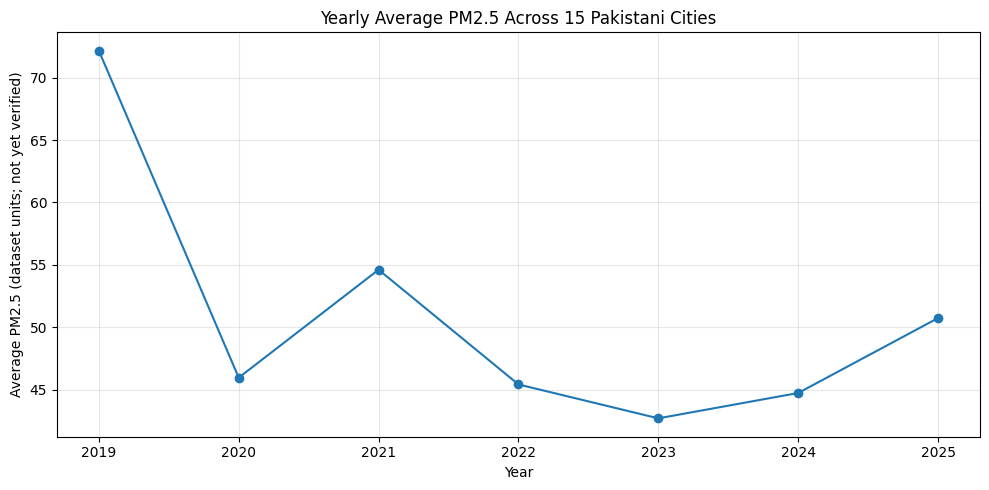

In [30]:

import matplotlib.pyplot as plt

# Calculate yearly average, using complete years only
yearly_avg = (
    df_clean[df_clean["year"].between(2019, 2025)]
    .groupby("year")["pm25"]
    .mean()
)

# Create the chart
plt.figure(figsize=(10, 5))
plt.plot(
    yearly_avg.index,
    yearly_avg.values,
    marker="o"
)

plt.title("Yearly Average PM2.5 Across 15 Pakistani Cities")
plt.xlabel("Year")
plt.ylabel("Average PM2.5 (dataset units; not yet verified)")
plt.xticks(yearly_avg.index)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


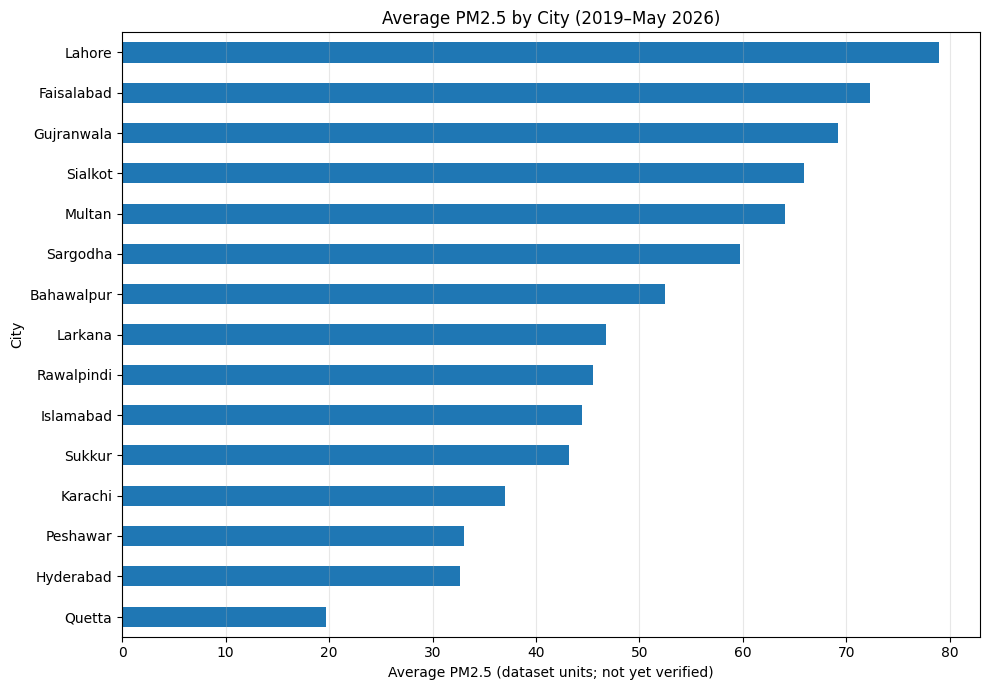

In [31]:

import matplotlib.pyplot as plt

# Calculate average PM2.5 for each city
city_avg = (
    df_clean.groupby("city")["pm25"]
    .mean()
    .sort_values(ascending=True)
)

# Create a horizontal bar chart
plt.figure(figsize=(10, 7))
city_avg.plot(kind="barh")

plt.title("Average PM2.5 by City (2019–May 2026)")
plt.xlabel("Average PM2.5 (dataset units; not yet verified)")
plt.ylabel("City")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


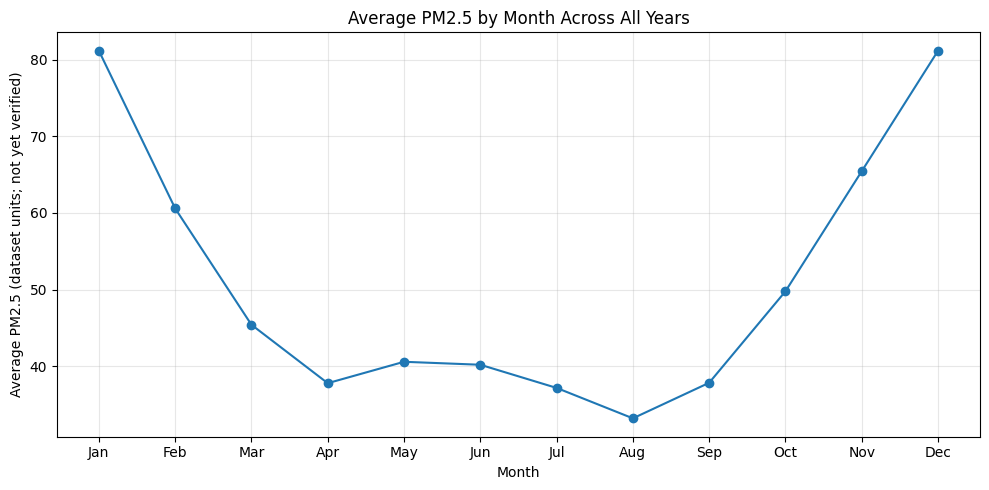

In [32]:

import matplotlib.pyplot as plt

# Extract month number and month name
df_clean["month"] = df_clean["date"].dt.month
df_clean["month_name"] = df_clean["date"].dt.strftime("%B")

# Calculate average PM2.5 for each month across all years
monthly_avg = (
    df_clean.groupby("month")["pm25"]
    .mean()
)

# Create the chart
plt.figure(figsize=(10, 5))
plt.plot(
    monthly_avg.index,
    monthly_avg.values,
    marker="o"
)

plt.title("Average PM2.5 by Month Across All Years")
plt.xlabel("Month")
plt.ylabel("Average PM2.5 (dataset units; not yet verified)")
plt.xticks(
    range(1, 13),
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


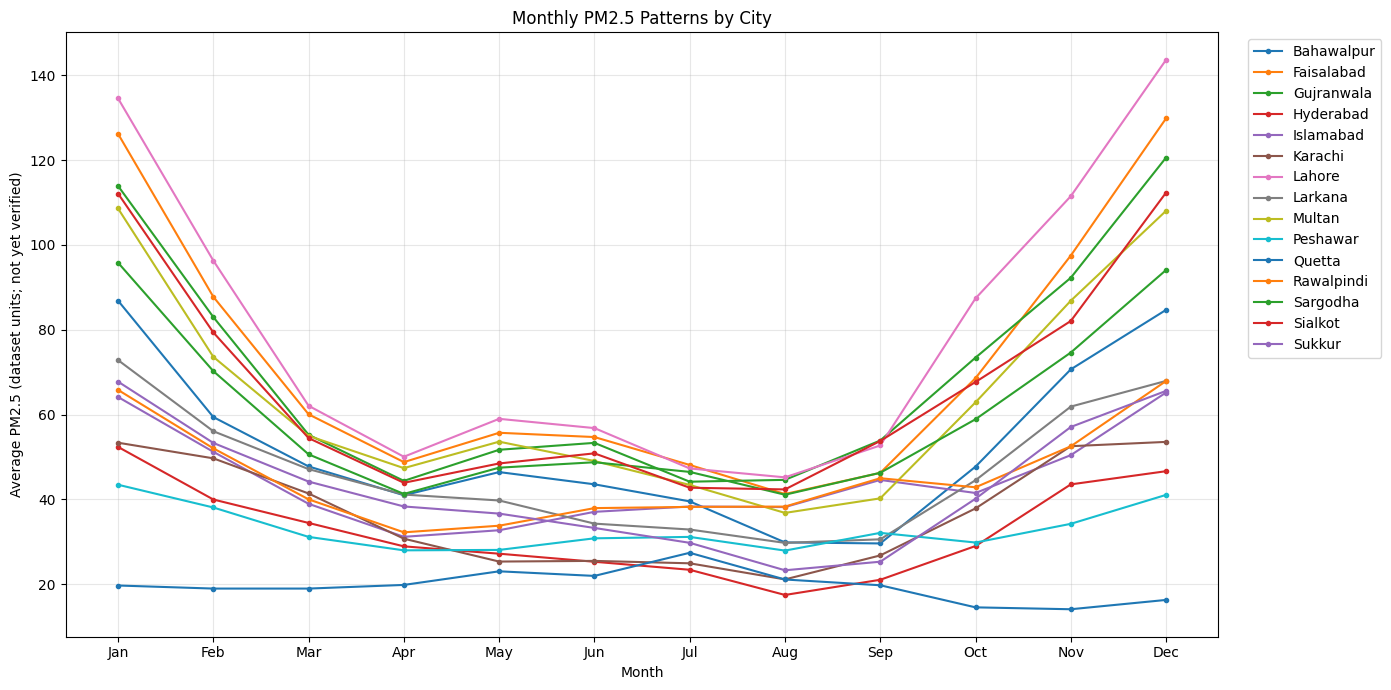

In [33]:

import matplotlib.pyplot as plt

# Calculate average PM2.5 for each city and month
city_monthly = df_clean.pivot_table(
    index="month",
    columns="city",
    values="pm25",
    aggfunc="mean"
)

# Plot monthly patterns for all cities
plt.figure(figsize=(14, 7))

for city in city_monthly.columns:
    plt.plot(
        city_monthly.index,
        city_monthly[city],
        marker="o",
        markersize=3,
        label=city
    )

plt.title("Monthly PM2.5 Patterns by City")
plt.xlabel("Month")
plt.ylabel("Average PM2.5 (dataset units; not yet verified)")
plt.xticks(
    range(1, 13),
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


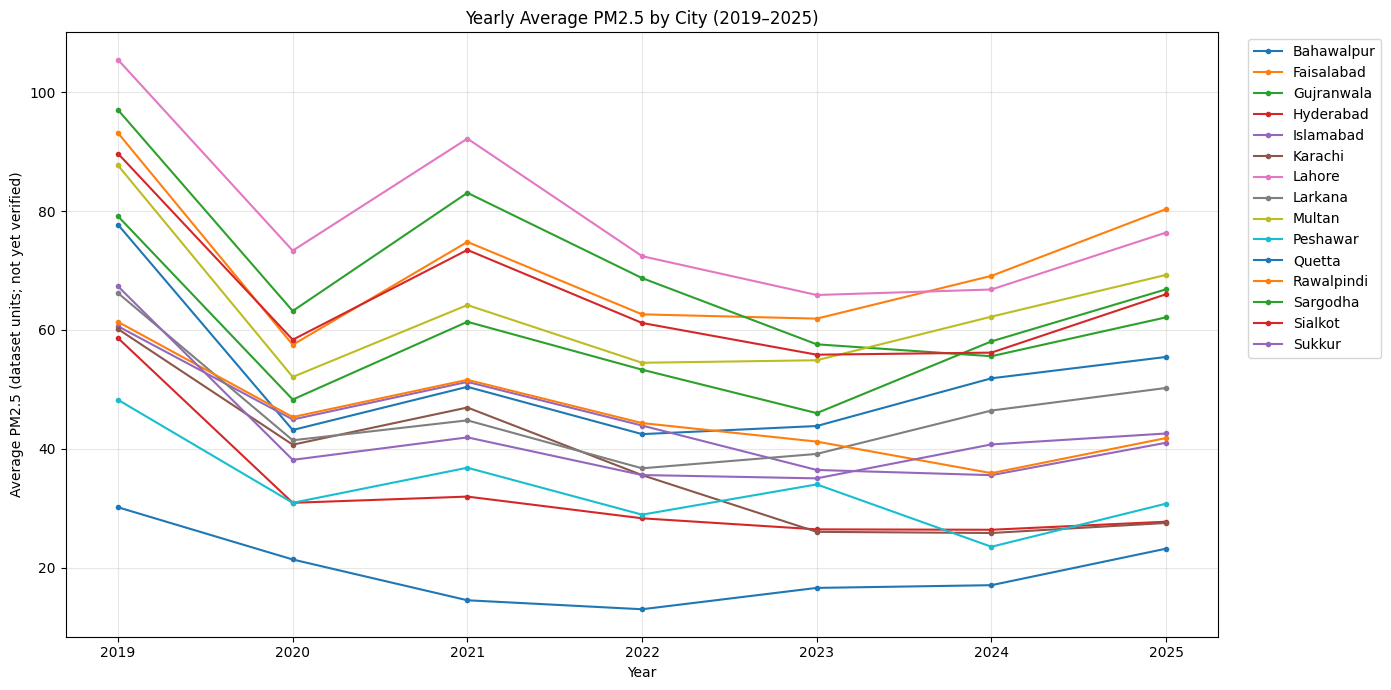

In [34]:

import matplotlib.pyplot as plt

# Keep complete years from 2019 to 2025
df_complete_years = df_clean[
    df_clean["date"].dt.year.between(2019, 2025)
].copy()

# Calculate yearly average PM2.5 for each city
city_yearly = df_complete_years.pivot_table(
    index="year",
    columns="city",
    values="pm25",
    aggfunc="mean"
)

# Draw one line for each city
plt.figure(figsize=(14, 7))

for city in city_yearly.columns:
    plt.plot(
        city_yearly.index,
        city_yearly[city],
        marker="o",
        markersize=3,
        label=city
    )

plt.title("Yearly Average PM2.5 by City (2019–2025)")
plt.xlabel("Year")
plt.ylabel("Average PM2.5 (dataset units; not yet verified)")
plt.xticks(range(2019, 2026))
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


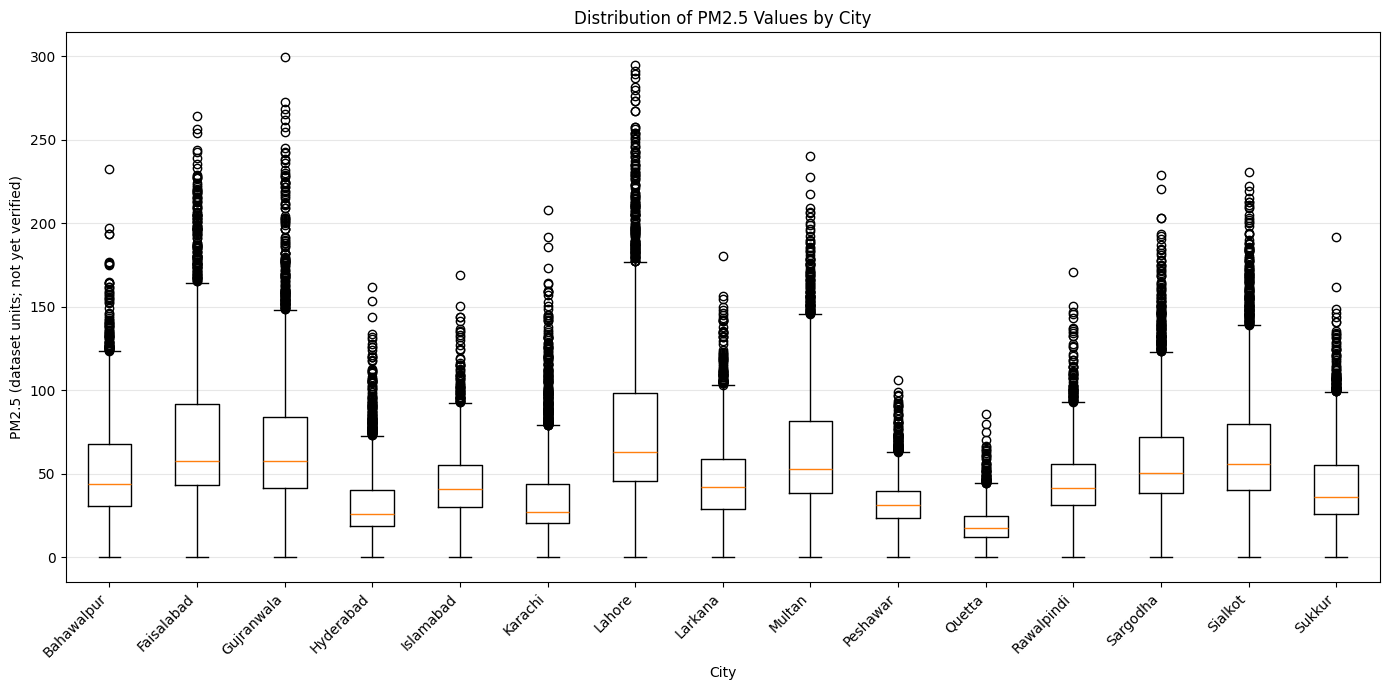

In [35]:

import matplotlib.pyplot as plt

# Arrange PM2.5 values by city
cities = sorted(df_clean["city"].unique())

plot_data = [
    df_clean.loc[df_clean["city"] == city, "pm25"].values
    for city in cities
]

# Create the box plot
plt.figure(figsize=(14, 7))
plt.boxplot(
    plot_data,
    tick_labels=cities,
    showfliers=True
)

plt.title("Distribution of PM2.5 Values by City")
plt.xlabel("City")
plt.ylabel("PM2.5 (dataset units; not yet verified)")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


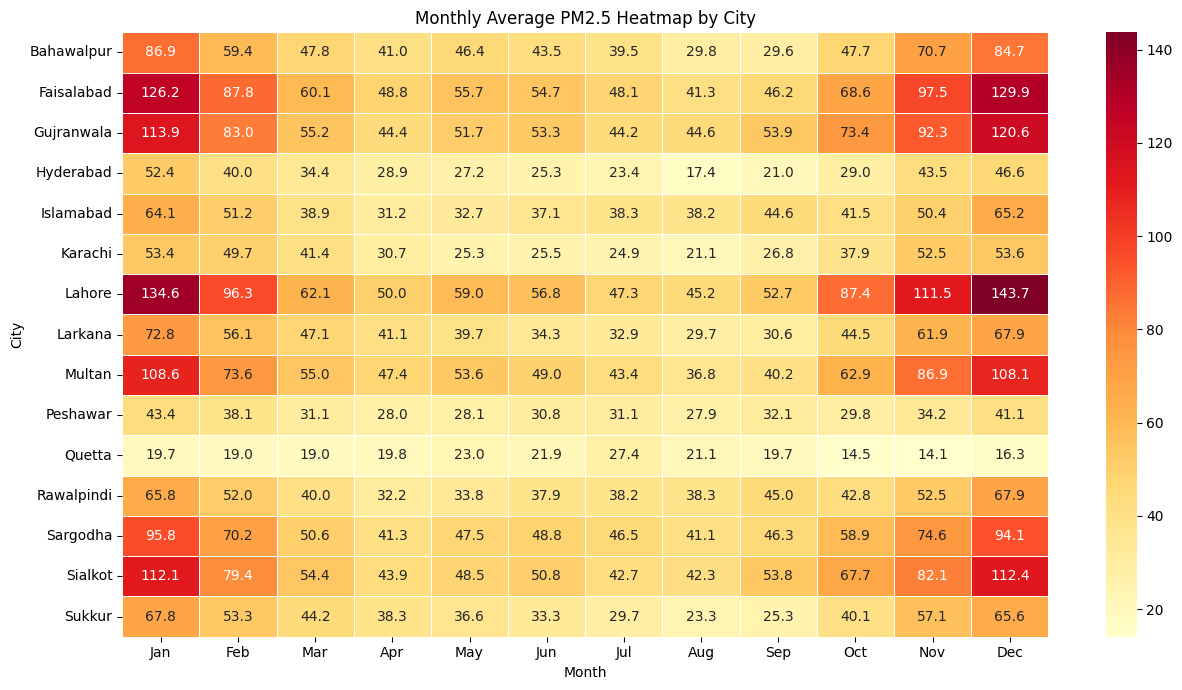

In [36]:

import matplotlib.pyplot as plt
import seaborn as sns

# Calculate average PM2.5 for each city and month
heatmap_data = df_clean.pivot_table(
    index="city",
    columns="month",
    values="pm25",
    aggfunc="mean"
)

# Create the heatmap
plt.figure(figsize=(13, 7))

sns.heatmap(
    heatmap_data,
    cmap="YlOrRd",
    annot=True,
    fmt=".1f",
    linewidths=0.5
)

plt.title("Monthly Average PM2.5 Heatmap by City")
plt.xlabel("Month")
plt.ylabel("City")
plt.xticks(
    ticks=[i + 0.5 for i in range(12)],
    labels=["Jan", "Feb", "Mar", "Apr", "May", "Jun",
            "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
)
plt.tight_layout()
plt.show()


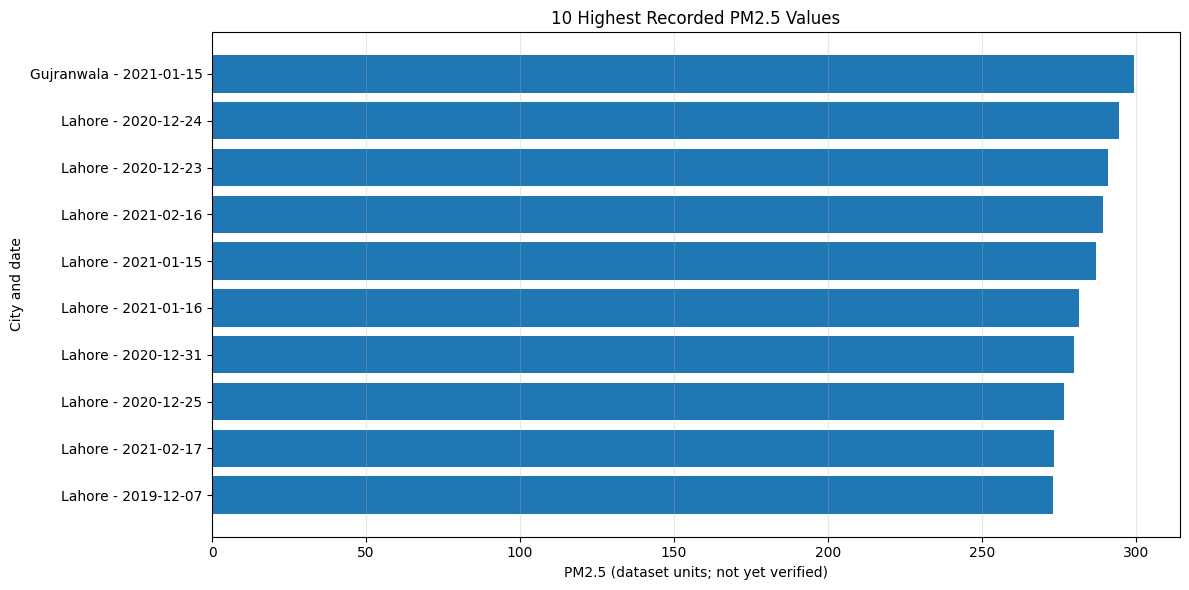

In [37]:

import matplotlib.pyplot as plt

# Get the 10 highest individual PM2.5 records
top_days = df_clean.nlargest(10, "pm25").copy()

# Create labels combining city and date
top_days["label"] = (
    top_days["city"] + " - "
    + top_days["date"].dt.strftime("%Y-%m-%d")
)

# Reverse order so the largest value appears at the top
top_days = top_days.sort_values("pm25", ascending=True)

# Plot the results
plt.figure(figsize=(12, 6))
plt.barh(top_days["label"], top_days["pm25"])

plt.title("10 Highest Recorded PM2.5 Values")
plt.xlabel("PM2.5 (dataset units; not yet verified)")
plt.ylabel("City and date")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


SMOGWATCH DATA SUMMARY
Rows: 40605
Cities: 15
Date range: 2019-01-01 to 2026-05-31
Missing PM2.5: 0
Duplicate city-date records: 0

Note: Source and PM2.5 units still need verification.


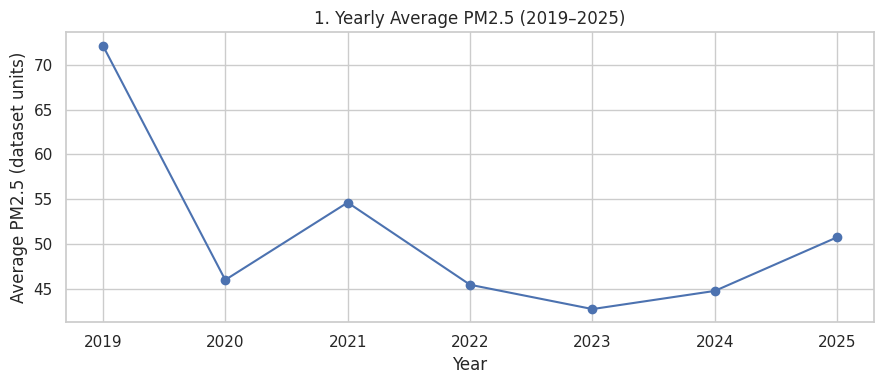

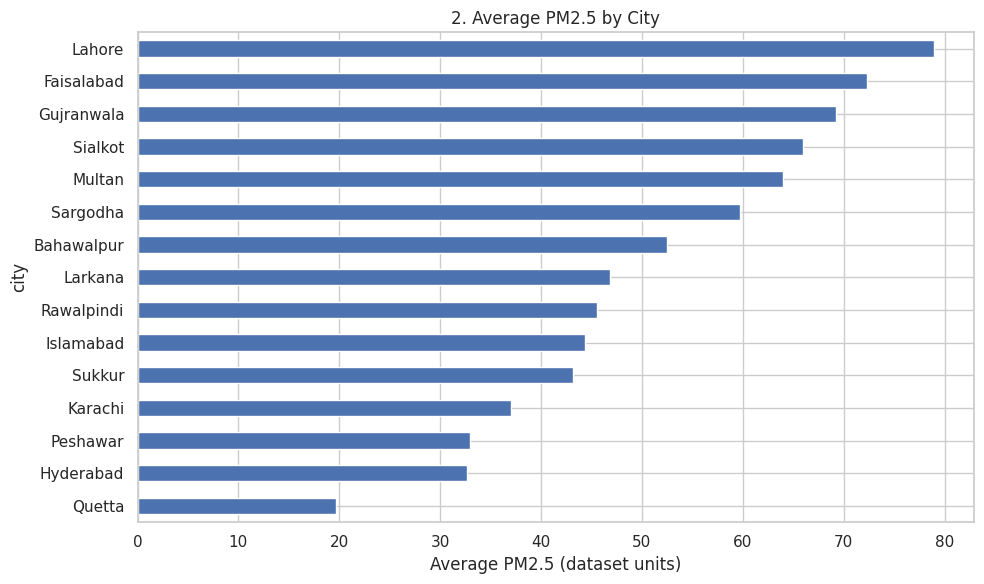

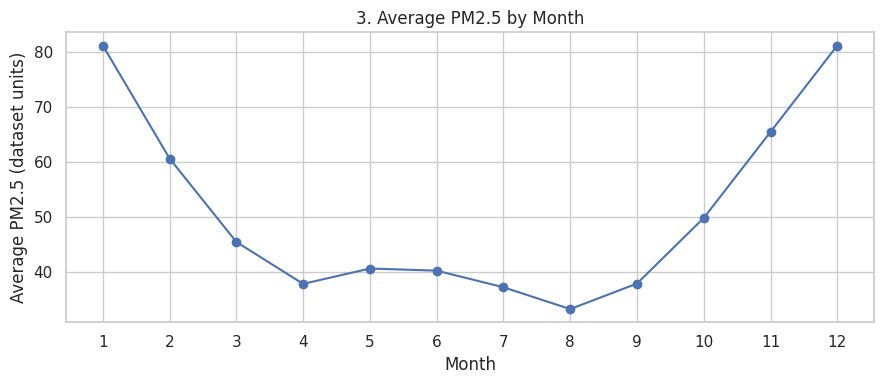

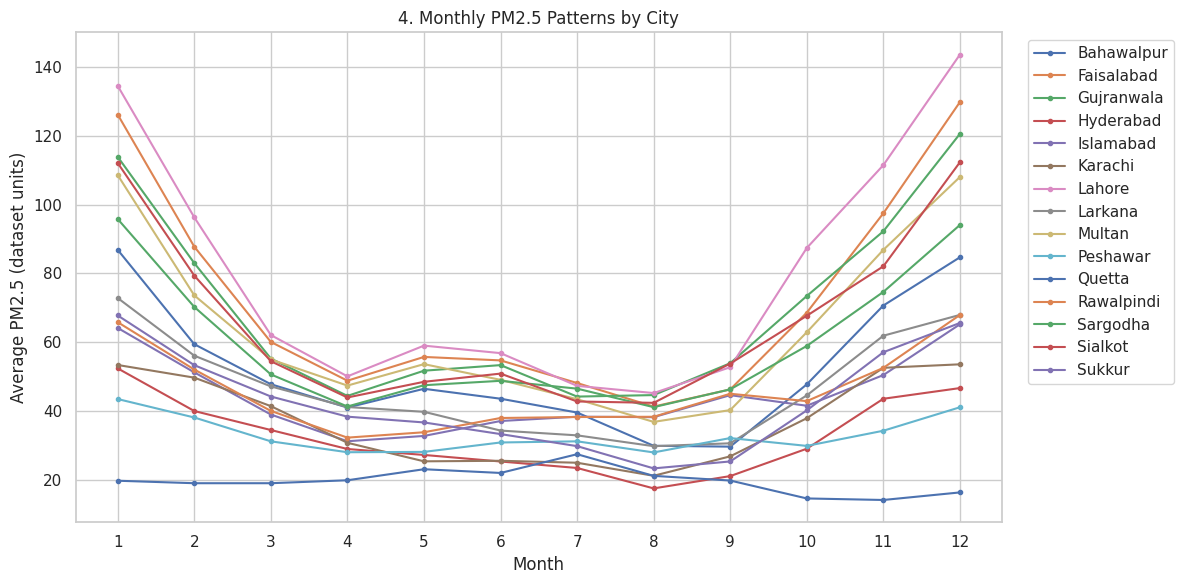

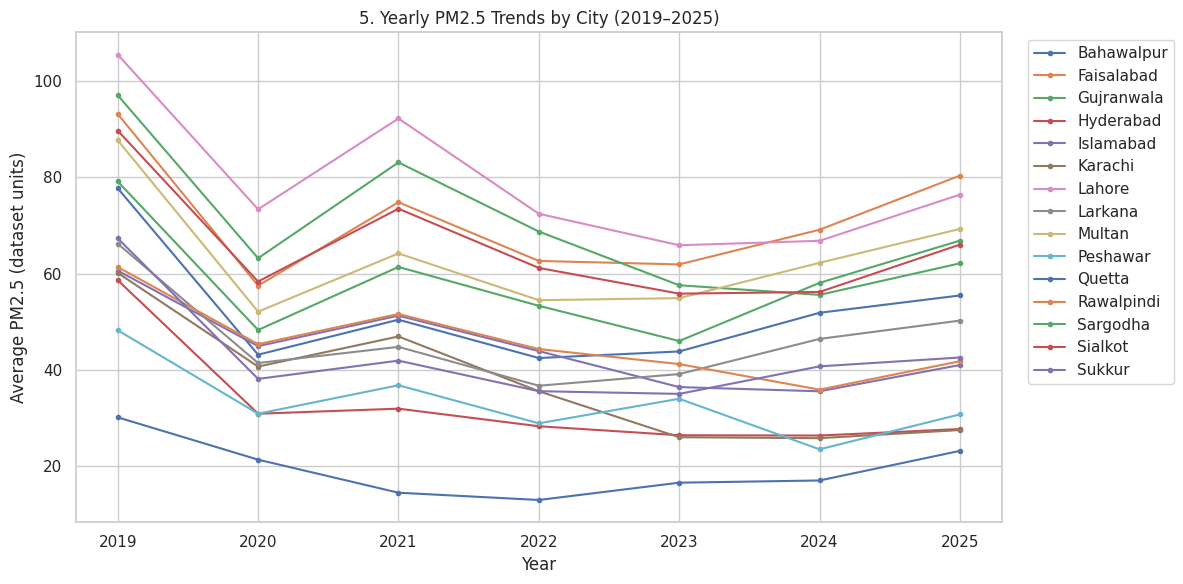

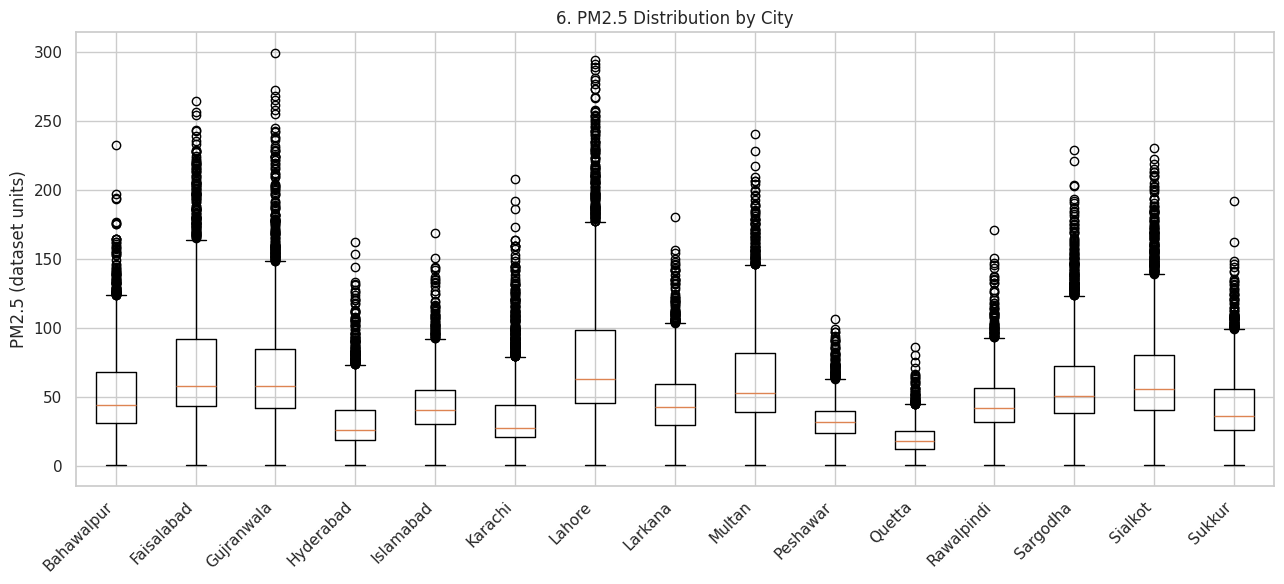

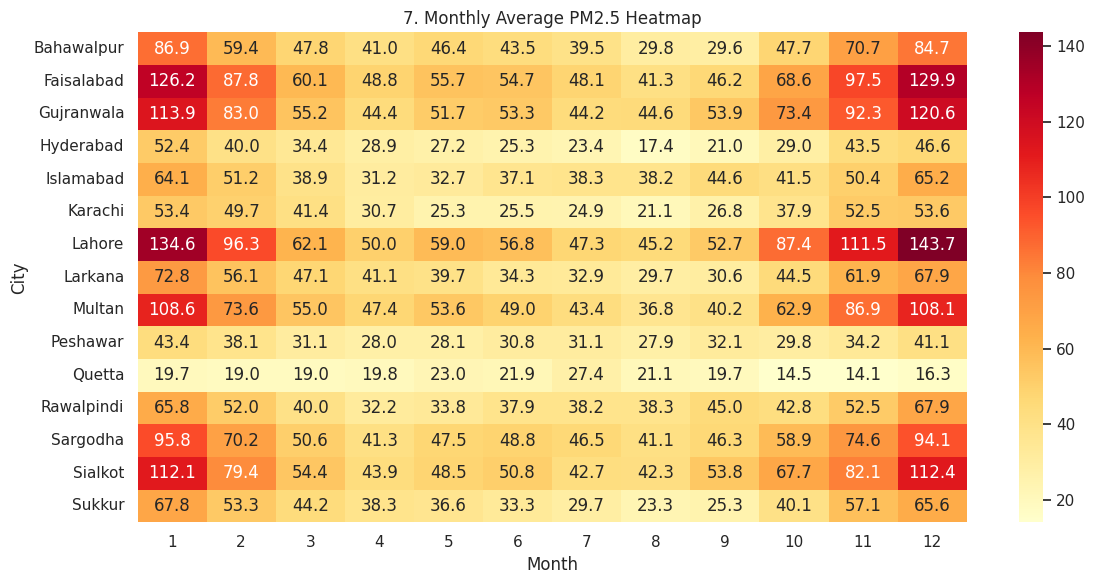

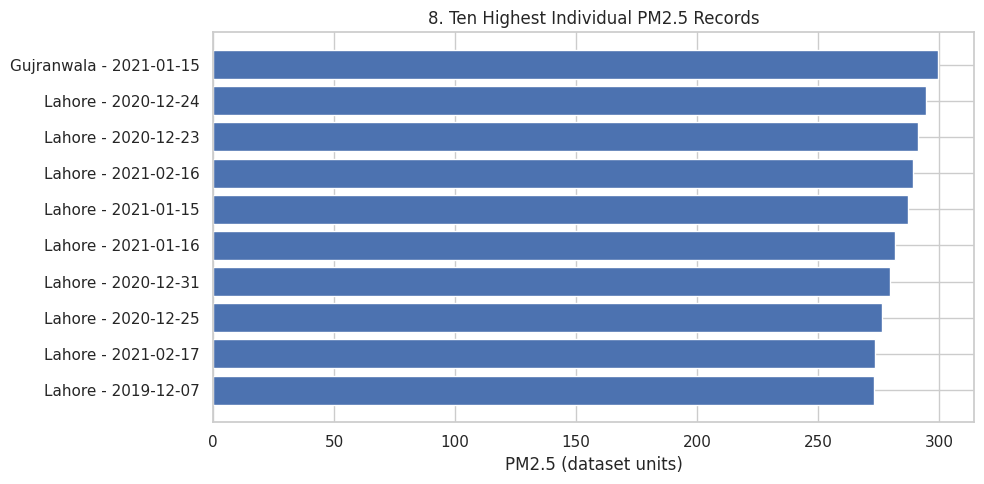

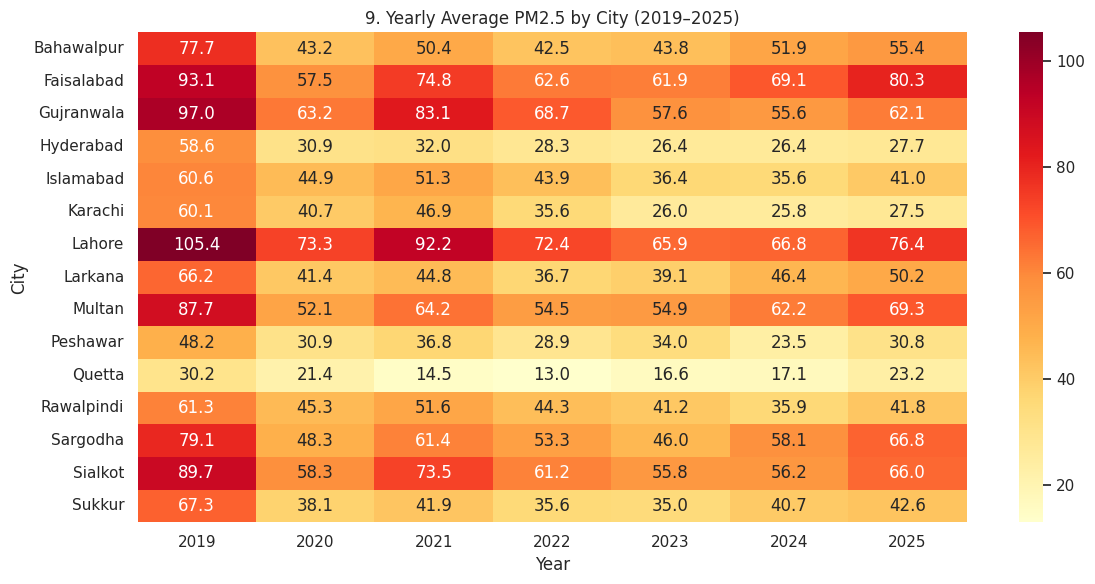

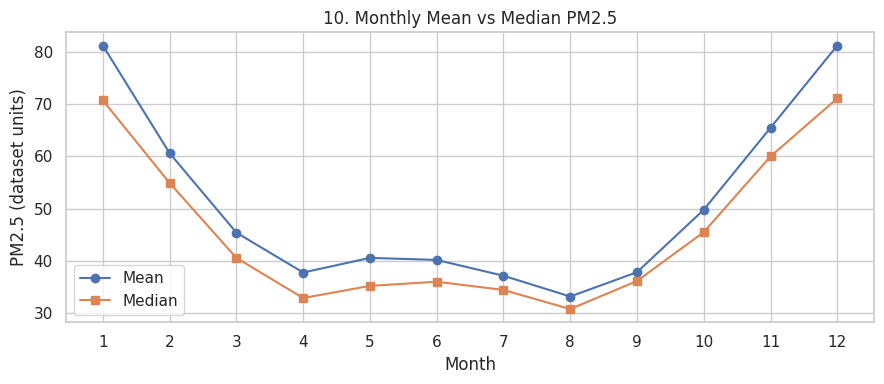


YEARLY SUMMARY


,count,mean,median,min,max
year,,,,,
2019,5475,72.15,65.84,8.98,273.02
2020,5490,45.97,38.64,2.70,294.61
2021,5475,54.62,46.41,4.32,299.46
2022,5475,45.43,40.61,3.03,195.84
2023,5460,42.72,37.97,4.26,216.52
2024,5490,44.74,35.11,0.11,254.31
2025,5475,50.74,42.09,6.75,264.47



CITY SUMMARY


,count,mean,median,min,max
city,,,,,
Lahore,2707,78.96,63.08,0.18,294.61
Faisalabad,2707,72.27,57.46,0.18,264.47
Gujranwala,2707,69.22,57.75,0.18,299.46
Sialkot,2707,65.94,55.91,0.15,230.52
Multan,2707,64.02,52.67,0.15,240.60
Sargodha,2707,59.72,50.75,0.17,228.73
Bahawalpur,2707,52.49,43.78,0.15,232.41
Larkana,2707,46.81,42.31,0.14,180.75
Rawalpindi,2707,45.49,41.57,0.12,171.14



MONTHLY SUMMARY


,mean,median,min,max
month,,,,
1,81.17,70.68,4.55,299.46
2,60.60,54.91,0.11,289.33
3,45.42,40.58,4.32,150.84
4,37.80,32.92,4.71,132.46
5,40.59,35.24,5.36,159.18
6,40.20,36.03,5.23,197.25
7,37.18,34.47,3.35,232.41
8,33.21,30.81,3.03,96.01
9,37.85,36.16,6.29,150.60



Analysis complete: 10 charts created.
Next: verify source/units, create an interactive Plotly chart,
analyze weather if suitable data is available, and write the report.


In [38]:

# ============================================================
# SMOGWATCH: COMBINED EXPLORATORY ANALYSIS AND CHARTS
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Prepare the data
df = df_clean.copy()
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["month_name"] = df["date"].dt.strftime("%b")

df = df.dropna(subset=["city", "date", "pm25"])

sns.set_theme(style="whitegrid")

print("SMOGWATCH DATA SUMMARY")
print("=" * 45)
print("Rows:", len(df))
print("Cities:", df["city"].nunique())
print("Date range:", df["date"].min().date(), "to",
      df["date"].max().date())
print("Missing PM2.5:", df["pm25"].isna().sum())
print("Duplicate city-date records:",
      df.duplicated(["city", "date"]).sum())
print("\nNote: Source and PM2.5 units still need verification.")

# 2. Yearly averages (2019-2025: complete years)
complete = df[df["year"].between(2019, 2025)]
yearly_avg = complete.groupby("year")["pm25"].mean()

plt.figure(figsize=(9, 4))
yearly_avg.plot(marker="o")
plt.title("1. Yearly Average PM2.5 (2019–2025)")
plt.xlabel("Year")
plt.ylabel("Average PM2.5 (dataset units)")
plt.tight_layout()
plt.show()

# 3. Average by city
city_avg = df.groupby("city")["pm25"].mean().sort_values()

plt.figure(figsize=(10, 6))
city_avg.plot(kind="barh")
plt.title("2. Average PM2.5 by City")
plt.xlabel("Average PM2.5 (dataset units)")
plt.tight_layout()
plt.show()

# 4. Average by calendar month
monthly_avg = df.groupby("month")["pm25"].mean()

plt.figure(figsize=(9, 4))
monthly_avg.plot(marker="o")
plt.title("3. Average PM2.5 by Month")
plt.xlabel("Month")
plt.ylabel("Average PM2.5 (dataset units)")
plt.xticks(range(1, 13))
plt.tight_layout()
plt.show()

# 5. Monthly trends for all cities
city_monthly = df.pivot_table(
    index="month", columns="city", values="pm25", aggfunc="mean"
)

plt.figure(figsize=(12, 6))
for city in city_monthly.columns:
    plt.plot(city_monthly.index, city_monthly[city],
             marker=".", label=city)
plt.title("4. Monthly PM2.5 Patterns by City")
plt.xlabel("Month")
plt.ylabel("Average PM2.5 (dataset units)")
plt.xticks(range(1, 13))
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# 6. Yearly trends by city
city_yearly = complete.pivot_table(
    index="year", columns="city", values="pm25", aggfunc="mean"
)

plt.figure(figsize=(12, 6))
for city in city_yearly.columns:
    plt.plot(city_yearly.index, city_yearly[city],
             marker=".", label=city)
plt.title("5. Yearly PM2.5 Trends by City (2019–2025)")
plt.xlabel("Year")
plt.ylabel("Average PM2.5 (dataset units)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# 7. Box plot by city
cities = sorted(df["city"].unique())
box_data = [df.loc[df["city"] == c, "pm25"].values for c in cities]

plt.figure(figsize=(13, 6))
plt.boxplot(box_data, tick_labels=cities, showfliers=True)
plt.title("6. PM2.5 Distribution by City")
plt.ylabel("PM2.5 (dataset units)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# 8. Heatmap by city and month
heatmap_data = df.pivot_table(
    index="city", columns="month", values="pm25", aggfunc="mean"
)

plt.figure(figsize=(12, 6))
sns.heatmap(heatmap_data, cmap="YlOrRd", annot=True, fmt=".1f")
plt.title("7. Monthly Average PM2.5 Heatmap")
plt.xlabel("Month")
plt.ylabel("City")
plt.tight_layout()
plt.show()

# 9. Ten highest individual records
top10 = df.nlargest(10, "pm25").copy()
top10["label"] = (
    top10["city"] + " - " + top10["date"].dt.strftime("%Y-%m-%d")
)
top10 = top10.sort_values("pm25")

plt.figure(figsize=(10, 5))
plt.barh(top10["label"], top10["pm25"])
plt.title("8. Ten Highest Individual PM2.5 Records")
plt.xlabel("PM2.5 (dataset units)")
plt.tight_layout()
plt.show()

# 10. Yearly average city comparison
year_city = complete.pivot_table(
    index="city", columns="year", values="pm25", aggfunc="mean"
)

plt.figure(figsize=(12, 6))
sns.heatmap(year_city, cmap="YlOrRd", annot=True, fmt=".1f")
plt.title("9. Yearly Average PM2.5 by City (2019–2025)")
plt.xlabel("Year")
plt.ylabel("City")
plt.tight_layout()
plt.show()

# 11. Monthly variability across the dataset
monthly_stats = df.groupby("month")["pm25"].agg(
    ["mean", "median", "min", "max"]
)

plt.figure(figsize=(9, 4))
plt.plot(monthly_stats.index, monthly_stats["mean"],
         marker="o", label="Mean")
plt.plot(monthly_stats.index, monthly_stats["median"],
         marker="s", label="Median")
plt.title("10. Monthly Mean vs Median PM2.5")
plt.xlabel("Month")
plt.ylabel("PM2.5 (dataset units)")
plt.xticks(range(1, 13))
plt.legend()
plt.tight_layout()
plt.show()

# 12. Print useful summary tables
print("\nYEARLY SUMMARY")
display(complete.groupby("year")["pm25"].agg(
    ["count", "mean", "median", "min", "max"]
).round(2))

print("\nCITY SUMMARY")
display(df.groupby("city")["pm25"].agg(
    ["count", "mean", "median", "min", "max"]
).sort_values("mean", ascending=False).round(2))

print("\nMONTHLY SUMMARY")
display(monthly_stats.round(2))

print("\nAnalysis complete: 10 charts created.")
print("Next: verify source/units, create an interactive Plotly chart,")
print("analyze weather if suitable data is available, and write the report.")


In [39]:

!pip -q install plotly

import plotly.express as px

# Calculate average PM2.5 for each city
city_avg_plotly = (
    df.groupby("city", as_index=False)["pm25"]
    .mean()
    .sort_values("pm25", ascending=False)
)

# Create an interactive chart
fig = px.bar(
    city_avg_plotly,
    x="city",
    y="pm25",
    title="Interactive Comparison of Average PM2.5 by City",
    labels={
        "city": "City",
        "pm25": "Average PM2.5 (dataset units; not verified)"
    },
    hover_data={"pm25": ":.2f"},
    color="pm25",
    color_continuous_scale="YlOrRd"
)

fig.update_layout(
    xaxis_tickangle=-45,
    template="plotly_white"
)

fig.show()


In [40]:

# ============================================================
# SMOGWATCH: REMAINING ANALYSIS IN ONE CELL
# Requires the existing df_clean DataFrame
# ============================================================

!pip -q install plotly

import os
import pandas as pd
import numpy as np
import plotly.express as px
from IPython.display import display, Markdown

# 1. Check that the cleaned dataset exists
if "df_clean" not in globals():
    raise ValueError(
        "df_clean was not found. Run your previous data-cleaning cells first."
    )

df = df_clean.copy()
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["pm25"] = pd.to_numeric(df["pm25"], errors="coerce")
df = df.dropna(subset=["city", "date", "pm25"]).copy()
df = df[df["pm25"] >= 0].copy()

df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["month_name"] = df["date"].dt.strftime("%b")

# Create output folders
PROJECT_DIR = "/content/SmogWatch"
OUTPUT_DIR = os.path.join(PROJECT_DIR, "outputs")
DATA_DIR = os.path.join(PROJECT_DIR, "data", "processed")

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(DATA_DIR, exist_ok=True)

print("SMOGWATCH PROJECT CHECK")
print("=" * 50)
print(f"Rows: {len(df):,}")
print(f"Cities: {df['city'].nunique()}")
print(f"First date: {df['date'].min().date()}")
print(f"Last date: {df['date'].max().date()}")
print(f"Missing PM2.5 values: {df['pm25'].isna().sum()}")
print(f"Duplicate city-date rows: {df.duplicated(['city','date']).sum()}")
print("Dataset source: NOT YET VERIFIED")
print("PM2.5 units: NOT YET VERIFIED")
print("Weather variables: NOT PRESENT in this dataset")

# 2. Save cleaned dataset
df.to_csv(
    os.path.join(DATA_DIR, "smogwatch_pm25_cleaned.csv"),
    index=False
)

# 3. Create summary tables
city_summary = (
    df.groupby("city")["pm25"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
    .sort_values("mean", ascending=False)
)
city_summary.to_csv(os.path.join(OUTPUT_DIR, "city_summary.csv"))

monthly_summary = (
    df.groupby("month")["pm25"]
    .agg(["mean", "median", "count"])
    .round(2)
)
monthly_summary.to_csv(os.path.join(OUTPUT_DIR, "monthly_summary.csv"))

yearly_summary = (
    df.groupby("year")["pm25"]
    .agg(["mean", "median", "count"])
    .round(2)
)
yearly_summary.to_csv(os.path.join(OUTPUT_DIR, "yearly_summary.csv"))

print("\nCITY SUMMARY")
display(city_summary)

print("\nMONTHLY SUMMARY")
display(monthly_summary)

print("\nYEARLY SUMMARY")
display(yearly_summary)

# 4. Interactive Plotly city comparison
fig = px.bar(
    city_summary.reset_index(),
    x="city",
    y="mean",
    color="mean",
    title="SmogWatch: Average PM2.5 by Pakistani City",
    labels={
        "city": "City",
        "mean": "Average PM2.5 (unit unverified)"
    },
    hover_data={"mean": ":.2f"},
    color_continuous_scale="YlOrRd"
)
fig.update_layout(
    xaxis_tickangle=-45,
    template="plotly_white"
)
fig.show()

# 5. Generate data-based findings
top_city = city_summary.index[0]
top_city_mean = city_summary.iloc[0]["mean"]
bottom_city = city_summary.index[-1]
bottom_city_mean = city_summary.iloc[-1]["mean"]

monthly_means = df.groupby("month")["pm25"].mean()
highest_month = int(monthly_means.idxmax())
lowest_month = int(monthly_means.idxmin())

# Compare only complete calendar years
first_date = df["date"].min()
last_date = df["date"].max()
complete_years = []

for year in sorted(df["year"].unique()):
    year_data = df[df["year"] == year]
    if (
        year_data["date"].min().date() == pd.Timestamp(year, 1, 1).date()
        and year_data["date"].max().date() == pd.Timestamp(year, 12, 31).date()
    ):
        complete_years.append(year)

findings = [
    f"The highest city average in this dataset is {top_city} "
    f"({top_city_mean:.2f} dataset units).",
    f"The lowest city average in this dataset is {bottom_city} "
    f"({bottom_city_mean:.2f} dataset units).",
    f"Month {highest_month} has the highest average across the available records "
    f"({monthly_means.max():.2f} dataset units).",
    f"Month {lowest_month} has the lowest average across the available records "
    f"({monthly_means.min():.2f} dataset units)."
]

if len(complete_years) >= 2:
    first_year = complete_years[0]
    last_year = complete_years[-1]
    first_mean = df.loc[df["year"] == first_year, "pm25"].mean()
    last_mean = df.loc[df["year"] == last_year, "pm25"].mean()
    pct_change = ((last_mean - first_mean) / first_mean * 100) if first_mean else np.nan
    findings.append(
        f"From {first_year} to {last_year}, the dataset average changed "
        f"from {first_mean:.2f} to {last_mean:.2f} dataset units "
        f"({pct_change:.1f}% change). This is a descriptive comparison, "
        "not proof of a cause."
    )
else:
    findings.append(
        "There are not enough complete calendar years to calculate a fair "
        "year-to-year comparison."
    )

recommendations = [
    "Verify the original dataset publisher, measurement method, and PM2.5 units.",
    "Check unusual high values against the original source before deciding whether to remove them.",
    "Investigate seasonal patterns and prioritize further monitoring in cities with higher recorded averages.",
    "Add matched weather data before analyzing relationships between PM2.5, temperature, wind, and rainfall.",
    "Use WHO comparisons only after verifying the units and matching the correct averaging period."
]

print("\nFIVE DATA-BASED FINDINGS")
for i, finding in enumerate(findings, 1):
    print(f"{i}. {finding}")

print("\nRECOMMENDATIONS")
for i, recommendation in enumerate(recommendations, 1):
    print(f"{i}. {recommendation}")

# 6. Save findings and recommendations
with open(os.path.join(OUTPUT_DIR, "findings_and_recommendations.txt"),
          "w", encoding="utf-8") as f:
    f.write("SMOGWATCH FINDINGS\n\n")
    for i, item in enumerate(findings, 1):
        f.write(f"{i}. {item}\n")
    f.write("\nRECOMMENDATIONS\n\n")
    for i, item in enumerate(recommendations, 1):
        f.write(f"{i}. {item}\n")

# 7. Create a preliminary report
report = f"""# SmogWatch: PM2.5 Analysis in Pakistani Cities

## Project overview
This project explores daily PM2.5 values across {df['city'].nunique()} Pakistani
cities from {df['date'].min().date()} to {df['date'].max().date()}.

## Data quality
- Records analyzed: {len(df):,}
- Cities: {df['city'].nunique()}
- Missing PM2.5 values after cleaning: {df['pm25'].isna().sum()}
- Duplicate city-date rows: {df.duplicated(['city','date']).sum()}
- Dataset source: **Not yet verified**
- PM2.5 units: **Not yet verified**
- Weather variables: **Not included in this dataset**

## Findings
""" + "\n".join(
    f"{i}. {item}" for i, item in enumerate(findings, 1)
) + """

## Recommendations
""" + "\n".join(
    f"{i}. {item}" for i, item in enumerate(recommendations, 1)
) + """

## Limitations
These findings describe the dataset and do not establish causes.
The dataset source and units must be verified before official health-guideline
comparisons. Weather relationships cannot be tested using this dataset alone.
Incomplete calendar years must not be compared directly with full years.
"""

with open(os.path.join(OUTPUT_DIR, "preliminary_report.md"),
          "w", encoding="utf-8") as f:
    f.write(report)

display(Markdown("## Preliminary report preview\n" + report))

print("\nSAVED FILES")
for filename in sorted(os.listdir(OUTPUT_DIR)):
    print("-", filename)

print("\nCELL COMPLETE")
print("Next: verify the dataset source/units, add weather data,")
print("review the report, and publish the project to GitHub.")


SMOGWATCH PROJECT CHECK
Rows: 40,605
Cities: 15
First date: 2019-01-01
Last date: 2026-05-31
Missing PM2.5 values: 0
Duplicate city-date rows: 0
Dataset source: NOT YET VERIFIED
PM2.5 units: NOT YET VERIFIED
Weather variables: NOT PRESENT in this dataset

CITY SUMMARY


,count,mean,median,min,max
city,,,,,
Lahore,2707,78.96,63.08,0.18,294.61
Faisalabad,2707,72.27,57.46,0.18,264.47
Gujranwala,2707,69.22,57.75,0.18,299.46
Sialkot,2707,65.94,55.91,0.15,230.52
Multan,2707,64.02,52.67,0.15,240.60
Sargodha,2707,59.72,50.75,0.17,228.73
Bahawalpur,2707,52.49,43.78,0.15,232.41
Larkana,2707,46.81,42.31,0.14,180.75
Rawalpindi,2707,45.49,41.57,0.12,171.14



MONTHLY SUMMARY


,mean,median,count
month,,,
1,81.17,70.68,3720
2,60.60,54.91,3390
3,45.42,40.58,3720
4,37.80,32.92,3600
5,40.59,35.24,3705
6,40.20,36.03,3150
7,37.18,34.47,3255
8,33.21,30.81,3255
9,37.85,36.16,3150



YEARLY SUMMARY


,mean,median,count
year,,,
2019,72.15,65.84,5475
2020,45.97,38.64,5490
2021,54.62,46.41,5475
2022,45.43,40.61,5475
2023,42.72,37.97,5460
2024,44.74,35.11,5490
2025,50.74,42.09,5475
2026,52.25,40.58,2265



FIVE DATA-BASED FINDINGS
1. The highest city average in this dataset is Lahore (78.96 dataset units).
2. The lowest city average in this dataset is Quetta (19.66 dataset units).
3. Month 1 has the highest average across the available records (81.17 dataset units).
4. Month 8 has the lowest average across the available records (33.21 dataset units).
5. From 2019 to 2025, the dataset average changed from 72.15 to 50.74 dataset units (-29.7% change). This is a descriptive comparison, not proof of a cause.

RECOMMENDATIONS
1. Verify the original dataset publisher, measurement method, and PM2.5 units.
2. Check unusual high values against the original source before deciding whether to remove them.
3. Investigate seasonal patterns and prioritize further monitoring in cities with higher recorded averages.
4. Add matched weather data before analyzing relationships between PM2.5, temperature, wind, and rainfall.
5. Use WHO comparisons only after verifying the units and matching the correct aver

## Preliminary report preview
# SmogWatch: PM2.5 Analysis in Pakistani Cities

## Project overview
This project explores daily PM2.5 values across 15 Pakistani
cities from 2019-01-01 to 2026-05-31.

## Data quality
- Records analyzed: 40,605
- Cities: 15
- Missing PM2.5 values after cleaning: 0
- Duplicate city-date rows: 0
- Dataset source: **Not yet verified**
- PM2.5 units: **Not yet verified**
- Weather variables: **Not included in this dataset**

## Findings
1. The highest city average in this dataset is Lahore (78.96 dataset units).
2. The lowest city average in this dataset is Quetta (19.66 dataset units).
3. Month 1 has the highest average across the available records (81.17 dataset units).
4. Month 8 has the lowest average across the available records (33.21 dataset units).
5. From 2019 to 2025, the dataset average changed from 72.15 to 50.74 dataset units (-29.7% change). This is a descriptive comparison, not proof of a cause.

## Recommendations
1. Verify the original dataset publisher, measurement method, and PM2.5 units.
2. Check unusual high values against the original source before deciding whether to remove them.
3. Investigate seasonal patterns and prioritize further monitoring in cities with higher recorded averages.
4. Add matched weather data before analyzing relationships between PM2.5, temperature, wind, and rainfall.
5. Use WHO comparisons only after verifying the units and matching the correct averaging period.

## Limitations
These findings describe the dataset and do not establish causes.
The dataset source and units must be verified before official health-guideline
comparisons. Weather relationships cannot be tested using this dataset alone.
Incomplete calendar years must not be compared directly with full years.



SAVED FILES
- city_summary.csv
- findings_and_recommendations.txt
- monthly_summary.csv
- preliminary_report.md
- yearly_summary.csv

CELL COMPLETE
Next: verify the dataset source/units, add weather data,
review the report, and publish the project to GitHub.


In [41]:

import pandas as pd
import os

file_path = "/content/SmogWatch/data/candidate_15_cities/pakistan_pm25_15cities_2019_2026.csv"

if os.path.exists(file_path):
    data_check = pd.read_csv(file_path)

    print("DATASET FILE CHECK")
    print("-" * 40)
    print("Shape:", data_check.shape)
    print("\nColumn names:")
    print(data_check.columns.tolist())

    print("\nFirst five rows:")
    display(data_check.head())

    print("\nData types:")
    print(data_check.dtypes)

    print("\nPM2.5 statistical summary:")
    if "pm25" in data_check.columns:
        display(data_check["pm25"].describe())
else:
    print("File not found. Please check the file path.")


DATASET FILE CHECK
----------------------------------------
Shape: (40620, 3)

Column names:
['city', 'date', 'pm25']

First five rows:


,city,date,pm25
0,Bahawalpur,2019-01-01,193.56
1,Bahawalpur,2019-01-02,139.33
2,Bahawalpur,2019-01-03,158.89
3,Bahawalpur,2019-01-04,133.37
4,Bahawalpur,2019-01-05,124.76



Data types:
city     object
date     object
pm25    float64
dtype: object

PM2.5 statistical summary:


,pm25
count,40605.000000
mean,50.984018
std,34.163531
min,0.110000
25%,28.070000
50%,42.250000
75%,62.910000
max,299.460000


PM2.5 DATA
Rows: 40605
Cities: 15
Date range: 2019-01-01 to 2026-05-31
Weather downloaded: Bahawalpur (2708 days)
Weather downloaded: Faisalabad (2708 days)
Weather downloaded: Gujranwala (2708 days)
Weather downloaded: Hyderabad (2708 days)
Weather downloaded: Islamabad (2708 days)
Weather downloaded: Karachi (2708 days)
Weather downloaded: Lahore (2708 days)
Weather downloaded: Larkana (2708 days)
Weather downloaded: Multan (2708 days)
Weather downloaded: Peshawar (2708 days)
Weather downloaded: Quetta (2708 days)
Weather download failed for Rawalpindi: 429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=33.5651&longitude=73.0169&start_date=2019-01-01&end_date=2026-05-31&daily=temperature_2m_mean&daily=wind_speed_10m_mean&daily=precipitation_sum&timezone=Asia%2FKarachi
Weather download failed for Sargodha: 429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=32.0836&longitude=72.6711&start_

,count,mean,median,minimum,maximum
city,,,,,
Lahore,2707,78.96,63.08,0.18,294.61
Faisalabad,2707,72.27,57.46,0.18,264.47
Gujranwala,2707,69.22,57.75,0.18,299.46
Sialkot,2707,65.94,55.91,0.15,230.52
Multan,2707,64.02,52.67,0.15,240.60
Sargodha,2707,59.72,50.75,0.17,228.73
Bahawalpur,2707,52.49,43.78,0.15,232.41
Larkana,2707,46.81,42.31,0.14,180.75
Rawalpindi,2707,45.49,41.57,0.12,171.14



AVERAGE PM2.5 BY MONTH


,mean,median,count
month,,,
1,81.17,70.68,3720
2,60.60,54.91,3390
3,45.42,40.58,3720
4,37.80,32.92,3600
5,40.59,35.24,3705
6,40.20,36.03,3150
7,37.18,34.47,3255
8,33.21,30.81,3255
9,37.85,36.16,3150



AVERAGE PM2.5 BY YEAR


,mean,median,count
year,,,
2019,72.15,65.84,5475
2020,45.97,38.64,5490
2021,54.62,46.41,5475
2022,45.43,40.61,5475
2023,42.72,37.97,5460
2024,44.74,35.11,5490
2025,50.74,42.09,5475
2026,52.25,40.58,2265


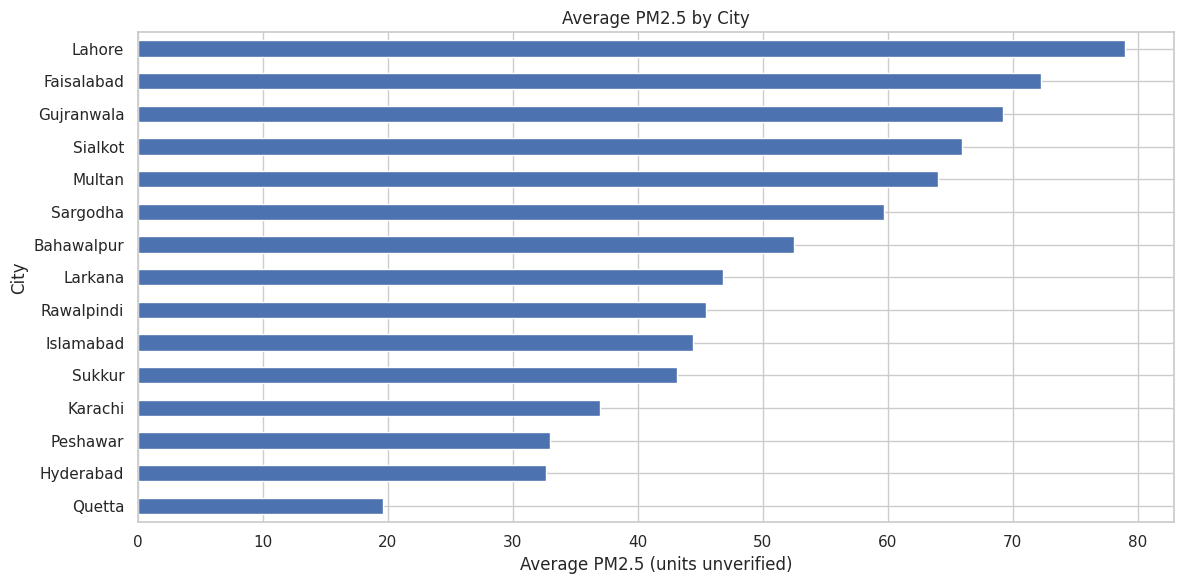

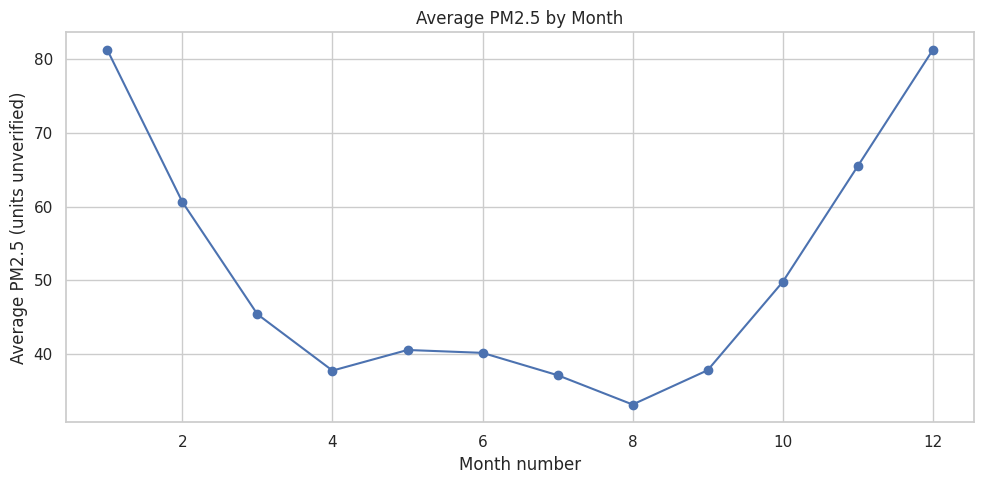

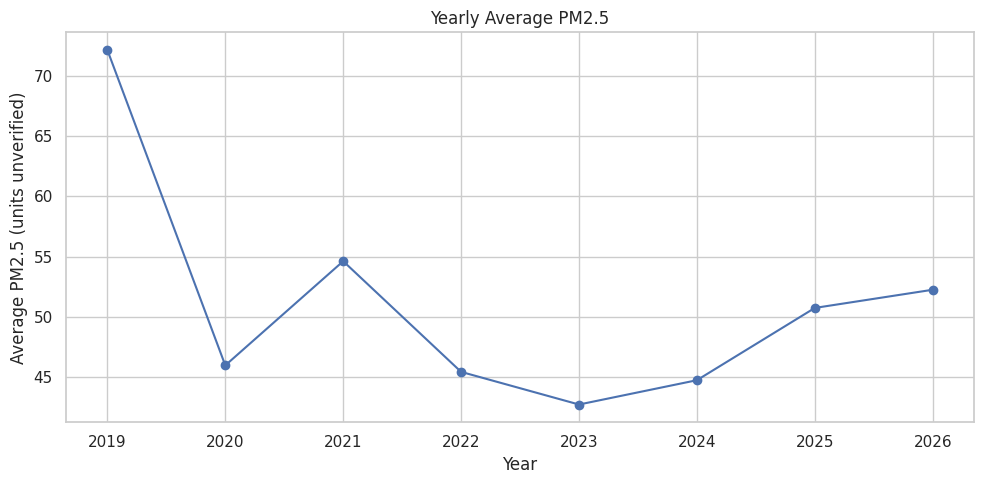

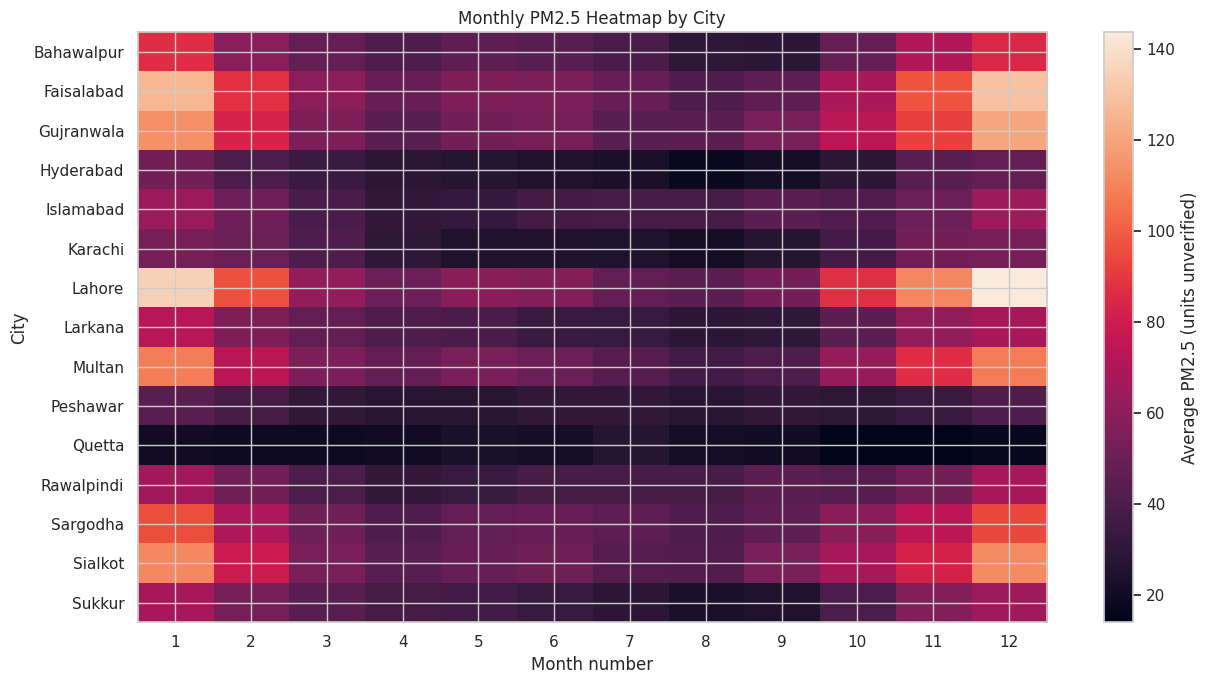

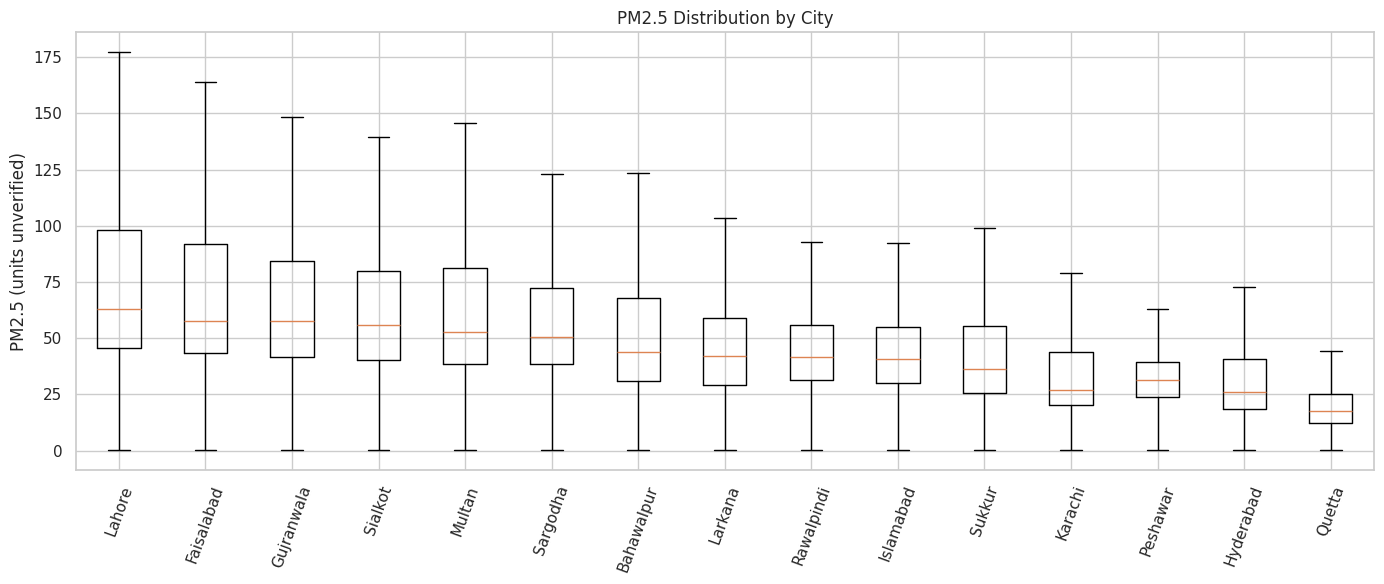

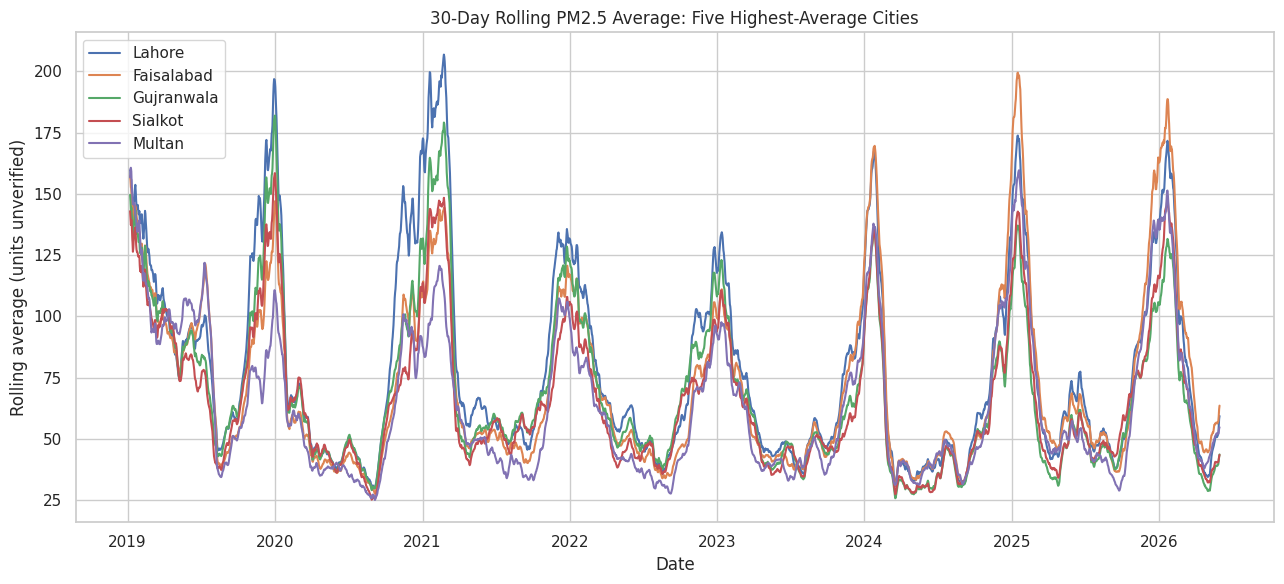

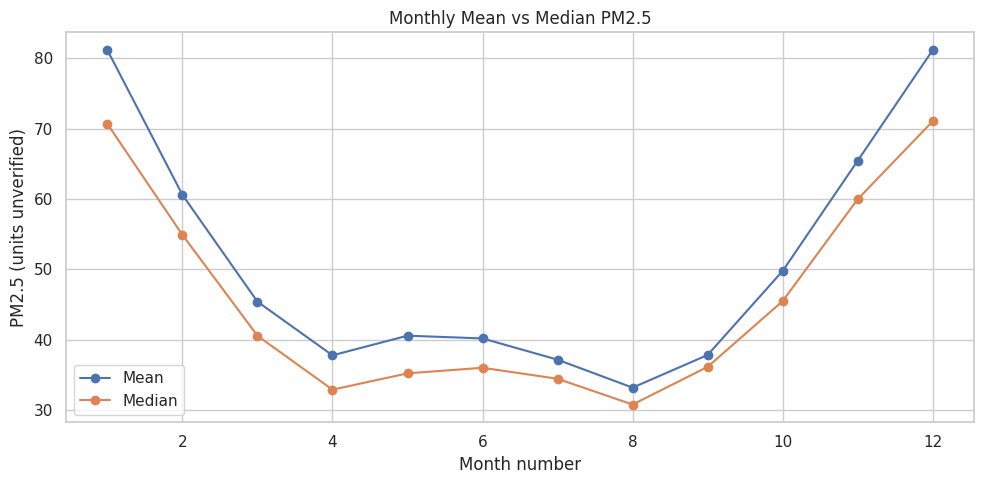

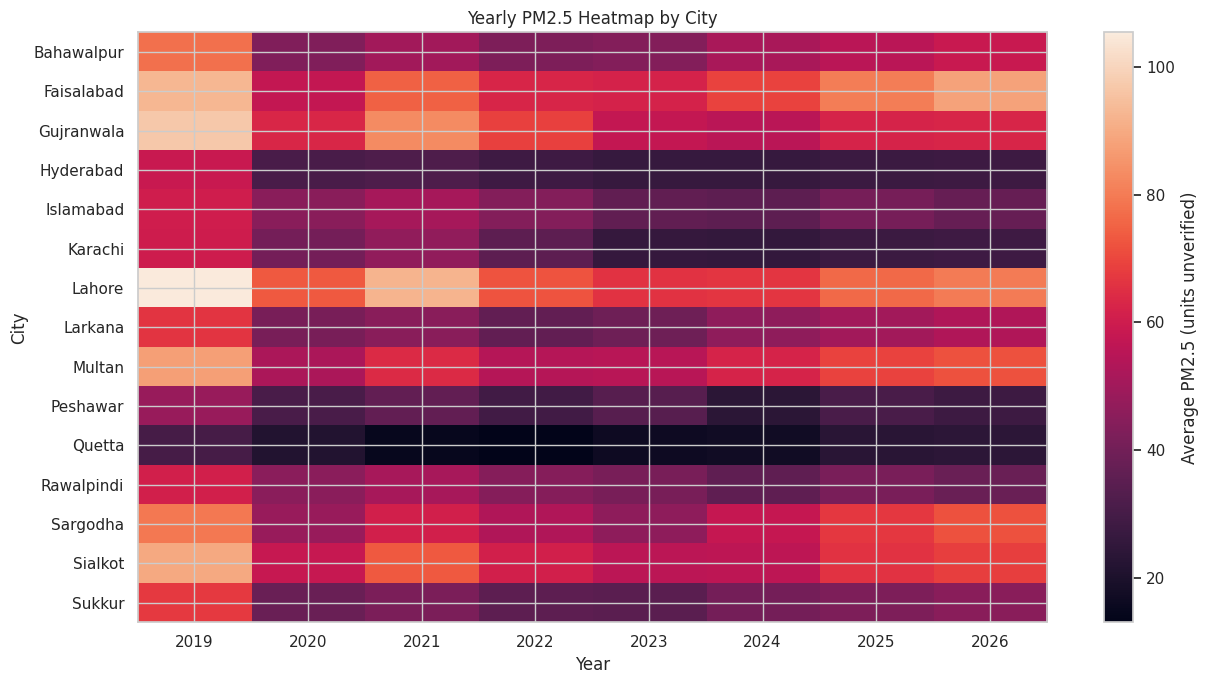

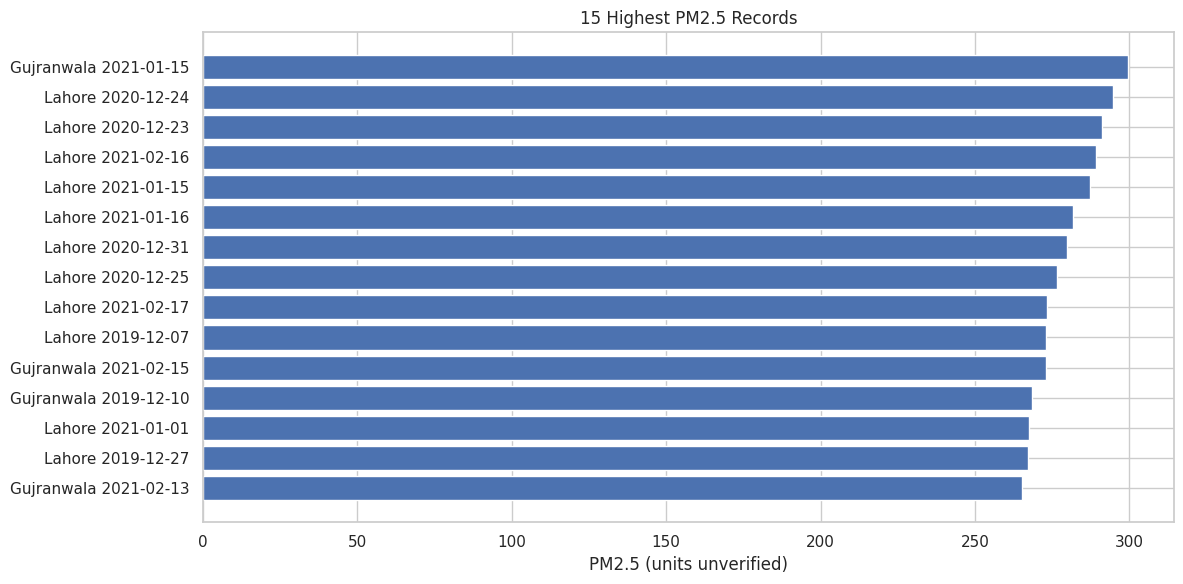

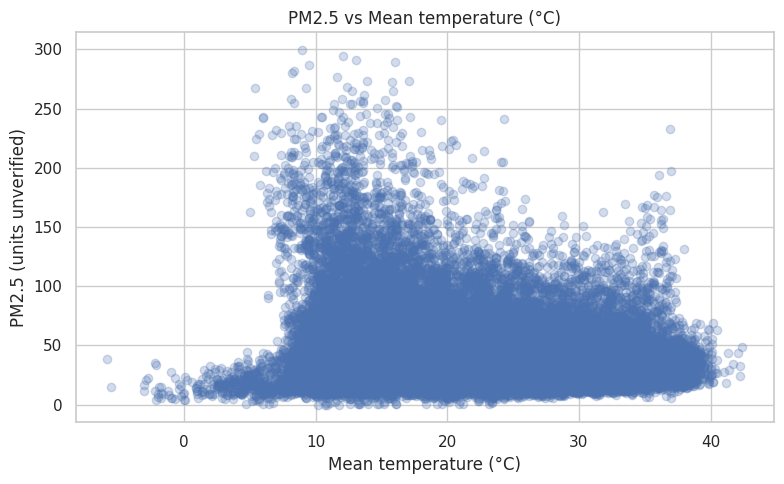

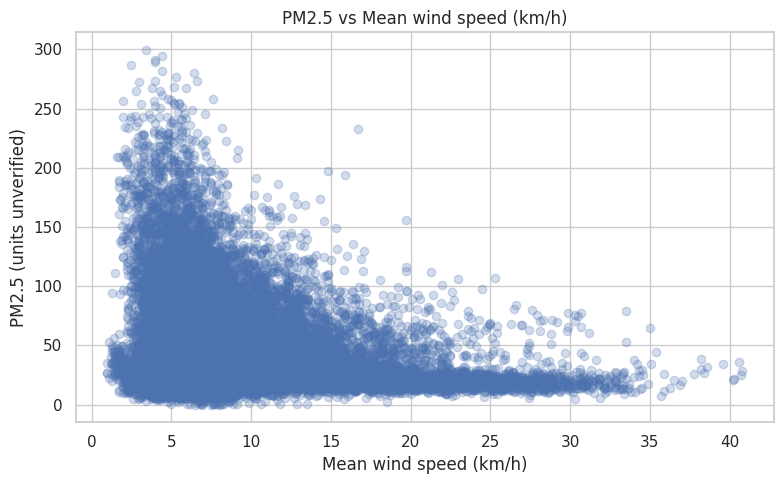

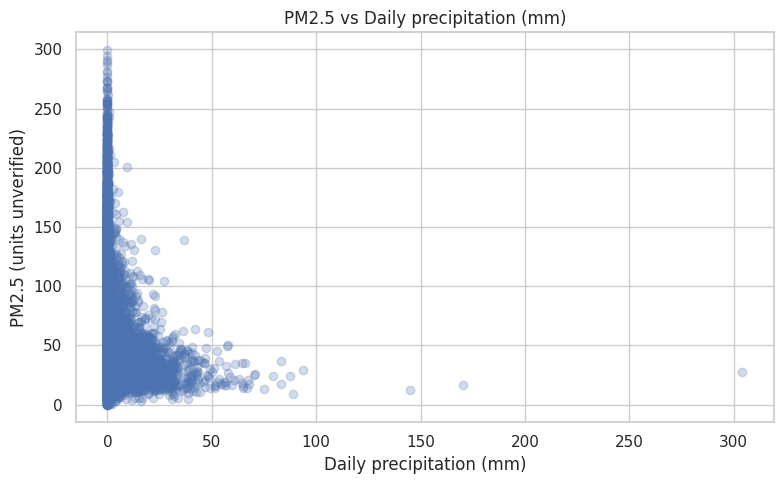


WEATHER CORRELATIONS (correlation does not prove causation)


,pm25,temperature_c,wind_speed_kmh,precipitation_mm
pm25,1.000,-0.327,-0.282,-0.097
temperature_c,-0.327,1.000,0.358,-0.008
wind_speed_kmh,-0.282,0.358,1.000,0.042
precipitation_mm,-0.097,-0.008,0.042,1.000



FINDINGS
1. Lahore has the highest average PM2.5 in this dataset (78.96, units unverified).
2. Quetta has the lowest average PM2.5 in this dataset (19.66, units unverified).
3. January has the highest monthly average across available records (81.17, units unverified).
4. August has the lowest monthly average across available records (33.21, units unverified).
5. These are descriptive patterns in the supplied dataset; source, units, and measurement methods must be verified before interpreting them as real-world pollution findings.

RECOMMENDATIONS
1. Verify the PM2.5 dataset publisher, collection method, and units.
2. Investigate unusual high values against the source before removing or changing them.
3. Use additional validated monitoring data to investigate city and seasonal patterns.
4. Treat weather correlations as associations, not proof that weather caused PM2.5 changes.
5. Compare with WHO guidelines only after confirming the pollutant units and matching averaging periods.
6. Do

# SmogWatch: PM2.5 Analysis Across Pakistani Cities

## Overview
This project explores 15 cities using 40,605 daily PM2.5 records
from 2019-01-01 through 2026-05-31.

## Data quality and provenance
- Rows analyzed: 40,605
- Cities: 15
- Missing PM2.5 values after cleaning: 0
- Duplicate city-date pairs after deduplication: 0
- PM2.5 source: **Not yet independently verified**
- PM2.5 units: **Not yet verified**
- Weather source: Open-Meteo Historical Weather API, if download succeeded.
- Weather records downloaded: 29,788

## Findings
1. Lahore has the highest average PM2.5 in this dataset (78.96, units unverified).
2. Quetta has the lowest average PM2.5 in this dataset (19.66, units unverified).
3. January has the highest monthly average across available records (81.17, units unverified).
4. August has the lowest monthly average across available records (33.21, units unverified).
5. These are descriptive patterns in the supplied dataset; source, units, and measurement methods must be verified before interpreting them as real-world pollution findings.

## Recommendations
1. Verify the PM2.5 dataset publisher, collection method, and units.
2. Investigate unusual high values against the source before removing or changing them.
3. Use additional validated monitoring data to investigate city and seasonal patterns.
4. Treat weather correlations as associations, not proof that weather caused PM2.5 changes.
5. Compare with WHO guidelines only after confirming the pollutant units and matching averaging periods.
6. Document data limitations and avoid presenting estimates as official measurements.

## Methods
Daily weather values were requested by city coordinates and merged with PM2.5 by city and date.
Charts and summary tables are generated from the available matched data.

## Limitations
The source and units of the supplied PM2.5 values have not yet been verified.
Weather data is an estimate for city coordinates and does not prove pollution causation.
Correlation does not establish causation. WHO comparisons are not included because units and
averaging compatibility have not been verified. The final year may be incomplete.
Review source provenance, API completeness, and missing weather rows before publication.



SMOGWATCH CELL FINISHED
Outputs folder: /content/SmogWatch/outputs
Processed data folder: /content/SmogWatch/data/processed
ZIP file: /content/SmogWatch/smogwatch_outputs.zip
Weather download errors: 4

Manual work still needed:
1. Verify PM2.5 source and units.
2. Review report and charts.
3. Only then decide whether WHO comparisons are valid.
4. Publish to GitHub and record the 2–3 minute demo.

To download the ZIP, run in another cell:
from google.colab import files
files.download('/content/SmogWatch/smogwatch_outputs.zip')


In [42]:

# ==============================================================
# SMOGWATCH - REMAINING PROJECT WORK IN ONE CELL
# Weather + merge + analysis + charts + findings + report + ZIP
# ==============================================================

!pip -q install requests plotly

import os, time, zipfile, warnings, requests
import numpy as np
import pandas as pd
import plotly.express as px
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")

# --------------------------------------------------------------
# 1. LOAD AND CLEAN EXISTING PM2.5 DATA
# --------------------------------------------------------------
if "df_clean" in globals():
    pm = df_clean.copy()
elif "df" in globals() and {"city", "date", "pm25"}.issubset(df.columns):
    pm = df.copy()
else:
    possible_paths = [
        "/content/SmogWatch/data/candidate_15_cities/pakistan_pm25_15cities_2019_2026.csv",
        "/content/SmogWatch/data/processed/smogwatch_pm25_cleaned.csv"
    ]
    existing_path = next((p for p in possible_paths if os.path.exists(p)), None)
    if existing_path is None:
        raise FileNotFoundError(
            "Could not find df_clean or the PM2.5 CSV. Run your earlier "
            "data-loading cell first."
        )
    pm = pd.read_csv(existing_path)

pm["date"] = pd.to_datetime(pm["date"], errors="coerce")
pm["pm25"] = pd.to_numeric(pm["pm25"], errors="coerce")
pm = pm.dropna(subset=["city", "date", "pm25"]).copy()
pm["city"] = pm["city"].astype(str).str.strip()
pm = pm[pm["pm25"] >= 0].copy()

# Keep one record per city/date if duplicates exist
pm = pm.sort_values("date").drop_duplicates(["city", "date"])

PROJECT = "/content/SmogWatch"
OUT = f"{PROJECT}/outputs"
PROCESSED = f"{PROJECT}/data/processed"
os.makedirs(OUT, exist_ok=True)
os.makedirs(PROCESSED, exist_ok=True)

print("PM2.5 DATA")
print("Rows:", len(pm))
print("Cities:", pm["city"].nunique())
print("Date range:", pm["date"].min().date(), "to", pm["date"].max().date())

# --------------------------------------------------------------
# 2. DOWNLOAD HISTORICAL WEATHER FROM OPEN-METEO
# --------------------------------------------------------------
coords = {
    "Bahawalpur": (29.3956, 71.6836),
    "Faisalabad": (31.4504, 73.1350),
    "Gujranwala": (32.1877, 74.1945),
    "Hyderabad": (25.3960, 68.3578),
    "Islamabad": (33.6844, 73.0479),
    "Karachi": (24.8607, 67.0011),
    "Lahore": (31.5204, 74.3587),
    "Larkana": (27.5580, 68.2120),
    "Multan": (30.1575, 71.5249),
    "Peshawar": (34.0151, 71.5249),
    "Quetta": (30.1798, 66.9750),
    "Rawalpindi": (33.5651, 73.0169),
    "Sargodha": (32.0836, 72.6711),
    "Sialkot": (32.4945, 74.5229),
    "Sukkur": (27.7052, 68.8574)
}

start = pm["date"].min().strftime("%Y-%m-%d")
end = pm["date"].max().strftime("%Y-%m-%d")
weather_parts = []
weather_errors = []

for city in sorted(pm["city"].unique()):
    if city not in coords:
        weather_errors.append(f"{city}: no coordinates configured")
        continue

    lat, lon = coords[city]
    params = {
        "latitude": lat,
        "longitude": lon,
        "start_date": start,
        "end_date": end,
        "daily": [
            "temperature_2m_mean",
            "wind_speed_10m_mean",
            "precipitation_sum"
        ],
        "timezone": "Asia/Karachi"
    }

    try:
        r = requests.get(
            "https://archive-api.open-meteo.com/v1/archive",
            params=params,
            timeout=90
        )
        r.raise_for_status()
        daily = r.json().get("daily", {})

        if not daily or "time" not in daily:
            raise ValueError("No daily weather returned")

        part = pd.DataFrame({
            "city": city,
            "date": pd.to_datetime(daily["time"]),
            "temperature_c": daily["temperature_2m_mean"],
            "wind_speed_kmh": daily["wind_speed_10m_mean"],
            "precipitation_mm": daily["precipitation_sum"]
        })
        weather_parts.append(part)
        print(f"Weather downloaded: {city} ({len(part)} days)")
        time.sleep(0.3)

    except Exception as e:
        weather_errors.append(f"{city}: {str(e)[:200]}")
        print(f"Weather download failed for {city}: {e}")

if weather_parts:
    weather = pd.concat(weather_parts, ignore_index=True)
    weather["date"] = pd.to_datetime(weather["date"])

    combined = pm.merge(
        weather, on=["city", "date"], how="left",
        validate="one_to_one"
    )
else:
    weather = pd.DataFrame()
    combined = pm.copy()
    for c in ["temperature_c", "wind_speed_kmh", "precipitation_mm"]:
        combined[c] = np.nan

combined["year"] = combined["date"].dt.year
combined["month"] = combined["date"].dt.month
combined["month_name"] = combined["date"].dt.strftime("%b")

combined.to_csv(f"{PROCESSED}/pm25_with_weather.csv", index=False)
weather.to_csv(f"{PROCESSED}/daily_weather.csv", index=False)

print("\nWeather rows:", len(weather))
print("PM2.5 rows matched:", len(combined))
print("Rows with missing temperature:", combined["temperature_c"].isna().sum())

# --------------------------------------------------------------
# 3. SUMMARY TABLES
# --------------------------------------------------------------
city_summary = combined.groupby("city")["pm25"].agg(
    count="count", mean="mean", median="median", minimum="min", maximum="max"
).round(2).sort_values("mean", ascending=False)

monthly_summary = combined.groupby("month")["pm25"].agg(
    mean="mean", median="median", count="count"
).round(2)

yearly_summary = combined.groupby("year")["pm25"].agg(
    mean="mean", median="median", count="count"
).round(2)

city_summary.to_csv(f"{OUT}/city_summary.csv")
monthly_summary.to_csv(f"{OUT}/monthly_summary.csv")
yearly_summary.to_csv(f"{OUT}/yearly_summary.csv")

print("\nAVERAGE PM2.5 BY CITY (dataset units unverified)")
display(city_summary)

print("\nAVERAGE PM2.5 BY MONTH")
display(monthly_summary)

print("\nAVERAGE PM2.5 BY YEAR")
display(yearly_summary)

# --------------------------------------------------------------
# 4. CREATE CHARTS
# --------------------------------------------------------------
chart_dir = f"{OUT}/charts"
os.makedirs(chart_dir, exist_ok=True)

def save_plot(filename):
    plt.tight_layout()
    plt.savefig(f"{chart_dir}/{filename}.png", dpi=160, bbox_inches="tight")
    plt.show()
    plt.close()

# Chart 1: City comparison
plt.figure(figsize=(12, 6))
city_summary["mean"].sort_values().plot(kind="barh")
plt.title("Average PM2.5 by City")
plt.xlabel("Average PM2.5 (units unverified)")
plt.ylabel("City")
save_plot("01_city_average")

# Chart 2: Monthly seasonal pattern
plt.figure(figsize=(10, 5))
monthly_summary["mean"].plot(marker="o")
plt.title("Average PM2.5 by Month")
plt.xlabel("Month number")
plt.ylabel("Average PM2.5 (units unverified)")
save_plot("02_monthly_pattern")

# Chart 3: Yearly averages
plt.figure(figsize=(10, 5))
yearly_summary["mean"].plot(marker="o")
plt.title("Yearly Average PM2.5")
plt.xlabel("Year")
plt.ylabel("Average PM2.5 (units unverified)")
save_plot("03_yearly_average")

# Chart 4: Monthly pattern by city
city_month = combined.pivot_table(
    index="city", columns="month", values="pm25", aggfunc="mean"
)
plt.figure(figsize=(13, 7))
plt.imshow(city_month, aspect="auto")
plt.colorbar(label="Average PM2.5 (units unverified)")
plt.xticks(range(len(city_month.columns)), city_month.columns)
plt.yticks(range(len(city_month.index)), city_month.index)
plt.title("Monthly PM2.5 Heatmap by City")
plt.xlabel("Month number")
plt.ylabel("City")
save_plot("04_city_month_heatmap")

# Chart 5: Distribution by city
plt.figure(figsize=(14, 6))
box_data = [
    combined.loc[combined["city"] == c, "pm25"].dropna().values
    for c in city_summary.index
]
plt.boxplot(box_data, tick_labels=city_summary.index, showfliers=False)
plt.xticks(rotation=70)
plt.title("PM2.5 Distribution by City")
plt.ylabel("PM2.5 (units unverified)")
save_plot("05_city_distribution")

# Chart 6: Daily data for the five highest-average cities
top_cities = city_summary.head(5).index.tolist()
top_daily = combined[combined["city"].isin(top_cities)].groupby(
    ["date", "city"], as_index=False
)["pm25"].mean()

plt.figure(figsize=(13, 6))
for city in top_cities:
    tmp = top_daily[top_daily["city"] == city]
    plt.plot(tmp["date"], tmp["pm25"].rolling(30, min_periods=7).mean(), label=city)
plt.title("30-Day Rolling PM2.5 Average: Five Highest-Average Cities")
plt.xlabel("Date")
plt.ylabel("Rolling average (units unverified)")
plt.legend()
save_plot("06_top_cities_trend")

# Chart 7: Monthly mean vs median
plt.figure(figsize=(10, 5))
plt.plot(monthly_summary.index, monthly_summary["mean"], marker="o", label="Mean")
plt.plot(monthly_summary.index, monthly_summary["median"], marker="o", label="Median")
plt.title("Monthly Mean vs Median PM2.5")
plt.xlabel("Month number")
plt.ylabel("PM2.5 (units unverified)")
plt.legend()
save_plot("07_mean_vs_median")

# Chart 8: Year-by-city heatmap
year_city = combined.pivot_table(
    index="city", columns="year", values="pm25", aggfunc="mean"
)
plt.figure(figsize=(13, 7))
plt.imshow(year_city, aspect="auto")
plt.colorbar(label="Average PM2.5 (units unverified)")
plt.xticks(range(len(year_city.columns)), year_city.columns)
plt.yticks(range(len(year_city.index)), year_city.index)
plt.title("Yearly PM2.5 Heatmap by City")
plt.xlabel("Year")
plt.ylabel("City")
save_plot("08_city_year_heatmap")

# Chart 9: Highest individual records
top_records = combined.nlargest(15, "pm25").copy()
plt.figure(figsize=(12, 6))
plt.barh(
    top_records["city"] + " " + top_records["date"].dt.strftime("%Y-%m-%d"),
    top_records["pm25"]
)
plt.title("15 Highest PM2.5 Records")
plt.xlabel("PM2.5 (units unverified)")
plt.gca().invert_yaxis()
save_plot("09_highest_records")

# Chart 10: Interactive Plotly chart
interactive = px.bar(
    city_summary.reset_index(),
    x="city", y="mean", color="mean",
    title="Interactive Average PM2.5 by City",
    labels={"city": "City", "mean": "Average PM2.5 (units unverified)"},
    hover_data={"mean": ":.2f"},
    color_continuous_scale="YlOrRd"
)
interactive.update_layout(xaxis_tickangle=-45, template="plotly_white")
interactive.write_html(f"{OUT}/interactive_city_chart.html")
interactive.show()

# Chart 11: Weather relationship charts, if weather is available
weather_cols = [
    "temperature_c", "wind_speed_kmh", "precipitation_mm"
]
weather_available = (
    combined[weather_cols].notna().any().any()
    and combined[weather_cols].notna().all(axis=1).sum() > 20
)

if weather_available:
    for col, label, filename in [
        ("temperature_c", "Mean temperature (°C)", "11_pm25_temperature"),
        ("wind_speed_kmh", "Mean wind speed (km/h)", "12_pm25_wind"),
        ("precipitation_mm", "Daily precipitation (mm)", "13_pm25_precipitation")
    ]:
        tmp = combined[["pm25", col]].dropna()
        plt.figure(figsize=(8, 5))
        plt.scatter(tmp[col], tmp["pm25"], alpha=0.25)
        plt.title(f"PM2.5 vs {label}")
        plt.xlabel(label)
        plt.ylabel("PM2.5 (units unverified)")
        save_plot(filename)

    weather_corr = combined[["pm25"] + weather_cols].corr().round(3)
    weather_corr.to_csv(f"{OUT}/weather_correlations.csv")
    print("\nWEATHER CORRELATIONS (correlation does not prove causation)")
    display(weather_corr)
else:
    weather_corr = pd.DataFrame()
    print("\nWeather analysis skipped: insufficient matched weather data.")

# --------------------------------------------------------------
# 5. FINDINGS AND RECOMMENDATIONS
# --------------------------------------------------------------
top_city = city_summary.index[0]
low_city = city_summary.index[-1]
month_names = {
    1:"January", 2:"February", 3:"March", 4:"April", 5:"May", 6:"June",
    7:"July", 8:"August", 9:"September", 10:"October", 11:"November", 12:"December"
}
high_month = int(monthly_summary["mean"].idxmax())
low_month = int(monthly_summary["mean"].idxmin())

findings = [
    f"{top_city} has the highest average PM2.5 in this dataset "
    f"({city_summary.loc[top_city, 'mean']:.2f}, units unverified).",
    f"{low_city} has the lowest average PM2.5 in this dataset "
    f"({city_summary.loc[low_city, 'mean']:.2f}, units unverified).",
    f"{month_names[high_month]} has the highest monthly average across available records "
    f"({monthly_summary.loc[high_month, 'mean']:.2f}, units unverified).",
    f"{month_names[low_month]} has the lowest monthly average across available records "
    f"({monthly_summary.loc[low_month, 'mean']:.2f}, units unverified).",
    "These are descriptive patterns in the supplied dataset; source, units, and measurement "
    "methods must be verified before interpreting them as real-world pollution findings."
]

recommendations = [
    "Verify the PM2.5 dataset publisher, collection method, and units.",
    "Investigate unusual high values against the source before removing or changing them.",
    "Use additional validated monitoring data to investigate city and seasonal patterns.",
    "Treat weather correlations as associations, not proof that weather caused PM2.5 changes.",
    "Compare with WHO guidelines only after confirming the pollutant units and matching averaging periods.",
    "Document data limitations and avoid presenting estimates as official measurements."
]

print("\nFINDINGS")
for i, item in enumerate(findings, 1):
    print(f"{i}. {item}")

print("\nRECOMMENDATIONS")
for i, item in enumerate(recommendations, 1):
    print(f"{i}. {item}")

with open(f"{OUT}/findings_and_recommendations.txt", "w", encoding="utf-8") as f:
    f.write("SMOGWATCH FINDINGS\n\n")
    f.write("\n".join(f"{i}. {x}" for i, x in enumerate(findings, 1)))
    f.write("\n\nRECOMMENDATIONS\n\n")
    f.write("\n".join(f"{i}. {x}" for i, x in enumerate(recommendations, 1)))

# --------------------------------------------------------------
# 6. CREATE PRELIMINARY PROJECT REPORT
# --------------------------------------------------------------
report = f"""# SmogWatch: PM2.5 Analysis Across Pakistani Cities

## Overview
This project explores {pm['city'].nunique()} cities using {len(pm):,} daily PM2.5 records
from {pm['date'].min().date()} through {pm['date'].max().date()}.

## Data quality and provenance
- Rows analyzed: {len(pm):,}
- Cities: {pm['city'].nunique()}
- Missing PM2.5 values after cleaning: {pm['pm25'].isna().sum()}
- Duplicate city-date pairs after deduplication: {pm.duplicated(['city','date']).sum()}
- PM2.5 source: **Not yet independently verified**
- PM2.5 units: **Not yet verified**
- Weather source: Open-Meteo Historical Weather API, if download succeeded.
- Weather records downloaded: {len(weather):,}

## Findings
""" + "\n".join(f"{i}. {x}" for i, x in enumerate(findings, 1)) + """

## Recommendations
""" + "\n".join(f"{i}. {x}" for i, x in enumerate(recommendations, 1)) + """

## Methods
Daily weather values were requested by city coordinates and merged with PM2.5 by city and date.
Charts and summary tables are generated from the available matched data.

## Limitations
The source and units of the supplied PM2.5 values have not yet been verified.
Weather data is an estimate for city coordinates and does not prove pollution causation.
Correlation does not establish causation. WHO comparisons are not included because units and
averaging compatibility have not been verified. The final year may be incomplete.
Review source provenance, API completeness, and missing weather rows before publication.
"""

with open(f"{OUT}/preliminary_report.md", "w", encoding="utf-8") as f:
    f.write(report)

display(Markdown(report))

# Save a record of weather download errors, if any
with open(f"{OUT}/weather_download_notes.txt", "w", encoding="utf-8") as f:
    f.write("Weather download notes\n\n")
    f.write("\n".join(weather_errors) if weather_errors else "No download errors recorded.")

# --------------------------------------------------------------
# 7. ZIP THE PROJECT OUTPUTS FOR DOWNLOAD
# --------------------------------------------------------------
zip_path = f"{PROJECT}/smogwatch_outputs.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for root, dirs, files in os.walk(OUT):
        for name in files:
            full = os.path.join(root, name)
            z.write(full, os.path.relpath(full, PROJECT))
    for name in ["pm25_with_weather.csv", "daily_weather.csv"]:
        full = f"{PROCESSED}/{name}"
        if os.path.exists(full):
            z.write(full, os.path.relpath(full, PROJECT))

print("\n" + "=" * 60)
print("SMOGWATCH CELL FINISHED")
print("Outputs folder:", OUT)
print("Processed data folder:", PROCESSED)
print("ZIP file:", zip_path)
print("Weather download errors:", len(weather_errors))
print("\nManual work still needed:")
print("1. Verify PM2.5 source and units.")
print("2. Review report and charts.")
print("3. Only then decide whether WHO comparisons are valid.")
print("4. Publish to GitHub and record the 2–3 minute demo.")
print("\nTo download the ZIP, run in another cell:")
print("from google.colab import files")
print("files.download('/content/SmogWatch/smogwatch_outputs.zip')")


PM2.5 DATA
Rows: 40605
Cities: 15
Date range: 2019-01-01 to 2026-05-31
Weather downloaded: Bahawalpur (2708 days)
Weather downloaded: Faisalabad (2708 days)
Weather downloaded: Gujranwala (2708 days)
Weather downloaded: Hyderabad (2708 days)
Weather downloaded: Islamabad (2708 days)
Weather downloaded: Karachi (2708 days)
Weather downloaded: Lahore (2708 days)
Weather downloaded: Larkana (2708 days)
Weather downloaded: Multan (2708 days)
Weather downloaded: Peshawar (2708 days)
Weather downloaded: Quetta (2708 days)
Weather download failed for Rawalpindi: 429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=33.5651&longitude=73.0169&start_date=2019-01-01&end_date=2026-05-31&daily=temperature_2m_mean&daily=wind_speed_10m_mean&daily=precipitation_sum&timezone=Asia%2FKarachi
Weather download failed for Sargodha: 429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=32.0836&longitude=72.6711&start_

,count,mean,median,minimum,maximum
city,,,,,
Lahore,2707,78.96,63.08,0.18,294.61
Faisalabad,2707,72.27,57.46,0.18,264.47
Gujranwala,2707,69.22,57.75,0.18,299.46
Sialkot,2707,65.94,55.91,0.15,230.52
Multan,2707,64.02,52.67,0.15,240.60
Sargodha,2707,59.72,50.75,0.17,228.73
Bahawalpur,2707,52.49,43.78,0.15,232.41
Larkana,2707,46.81,42.31,0.14,180.75
Rawalpindi,2707,45.49,41.57,0.12,171.14



AVERAGE PM2.5 BY MONTH


,mean,median,count
month,,,
1,81.17,70.68,3720
2,60.60,54.91,3390
3,45.42,40.58,3720
4,37.80,32.92,3600
5,40.59,35.24,3705
6,40.20,36.03,3150
7,37.18,34.47,3255
8,33.21,30.81,3255
9,37.85,36.16,3150



AVERAGE PM2.5 BY YEAR


,mean,median,count
year,,,
2019,72.15,65.84,5475
2020,45.97,38.64,5490
2021,54.62,46.41,5475
2022,45.43,40.61,5475
2023,42.72,37.97,5460
2024,44.74,35.11,5490
2025,50.74,42.09,5475
2026,52.25,40.58,2265


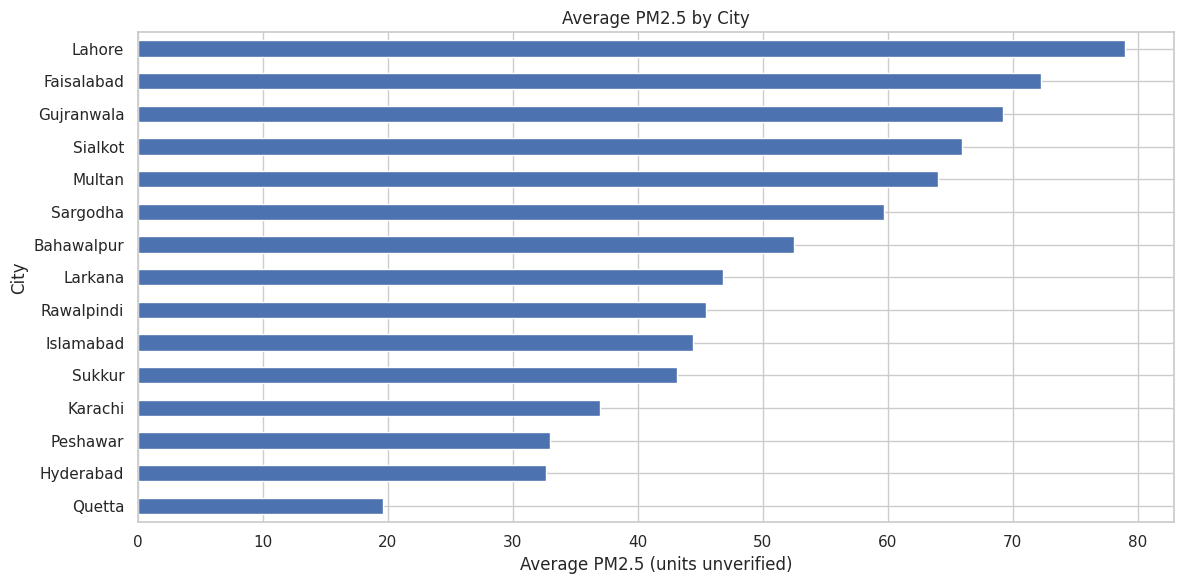

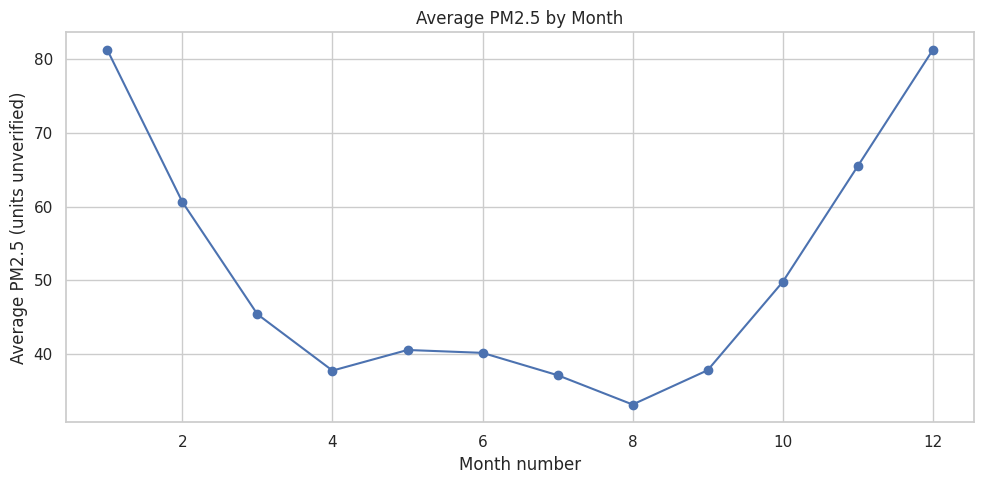

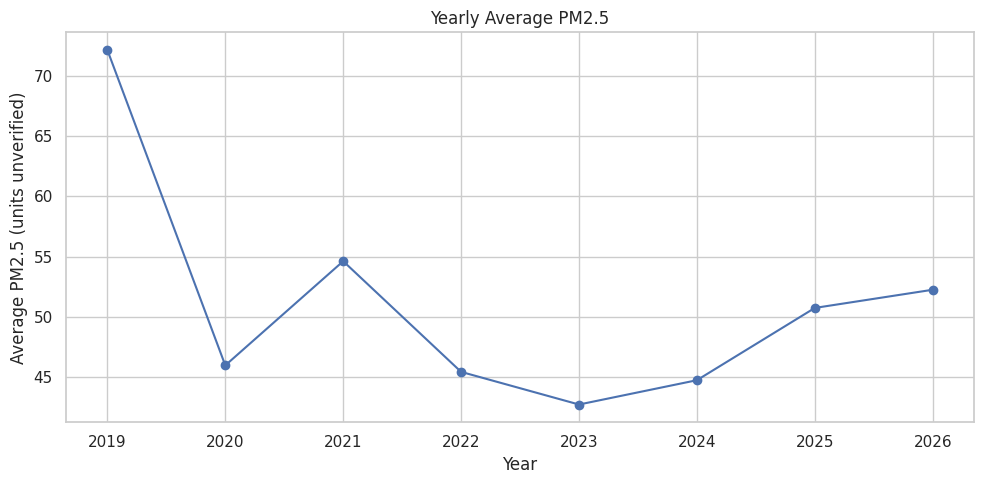

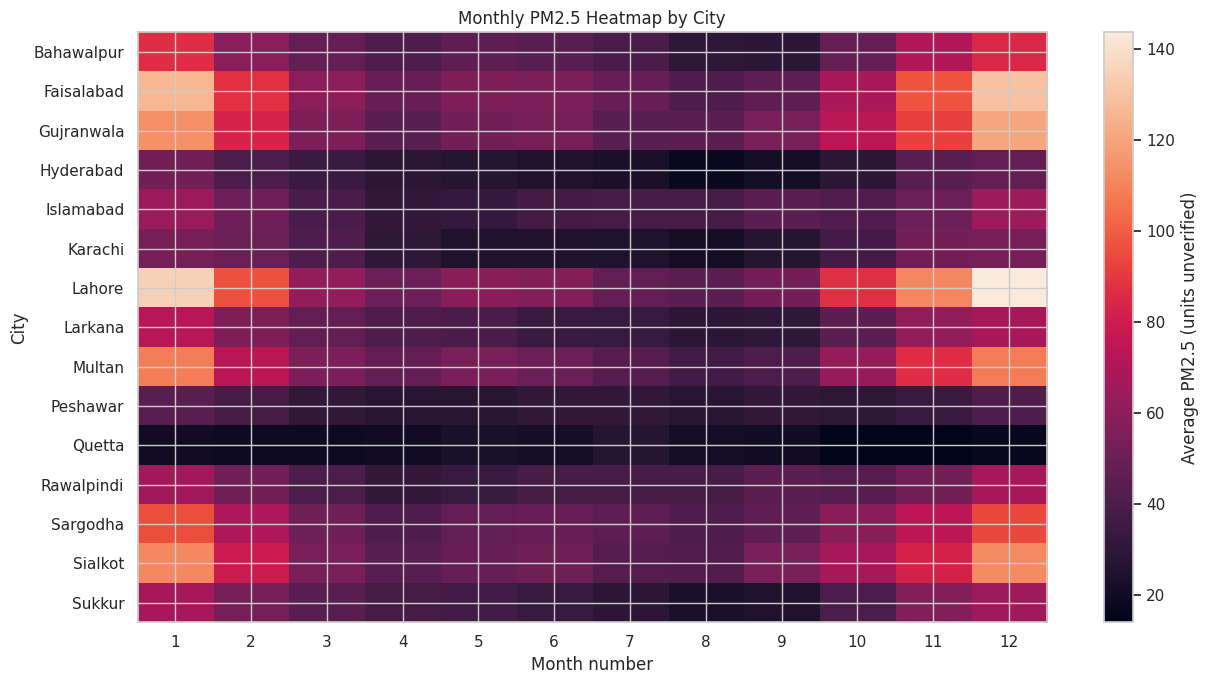

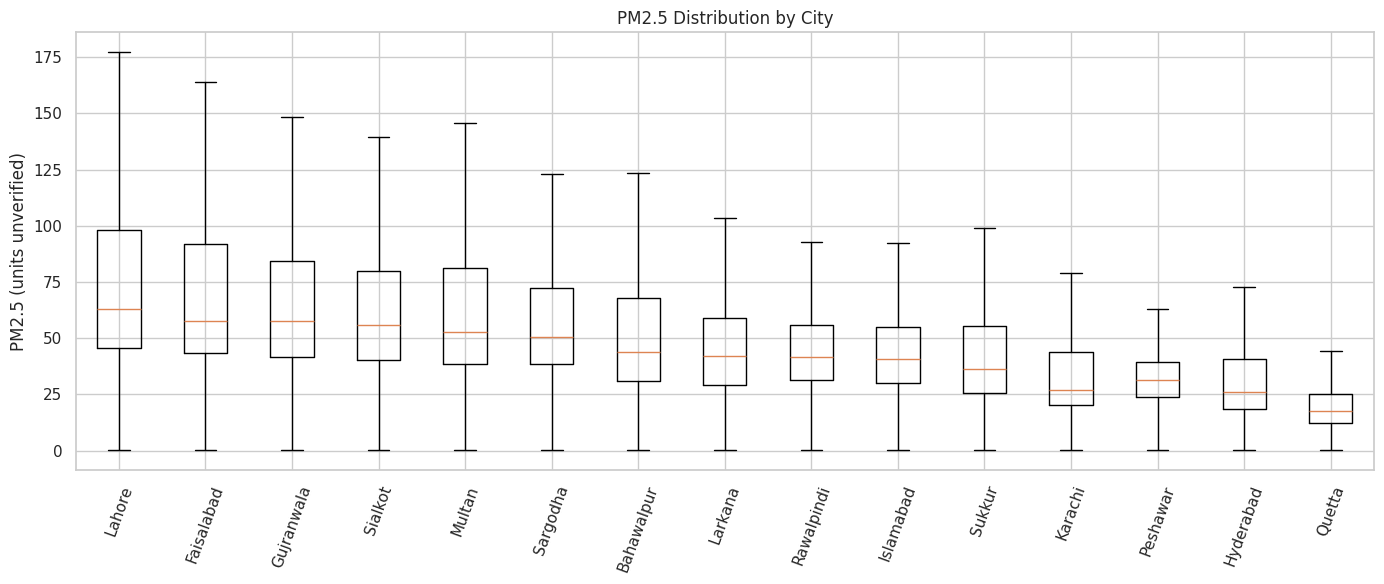

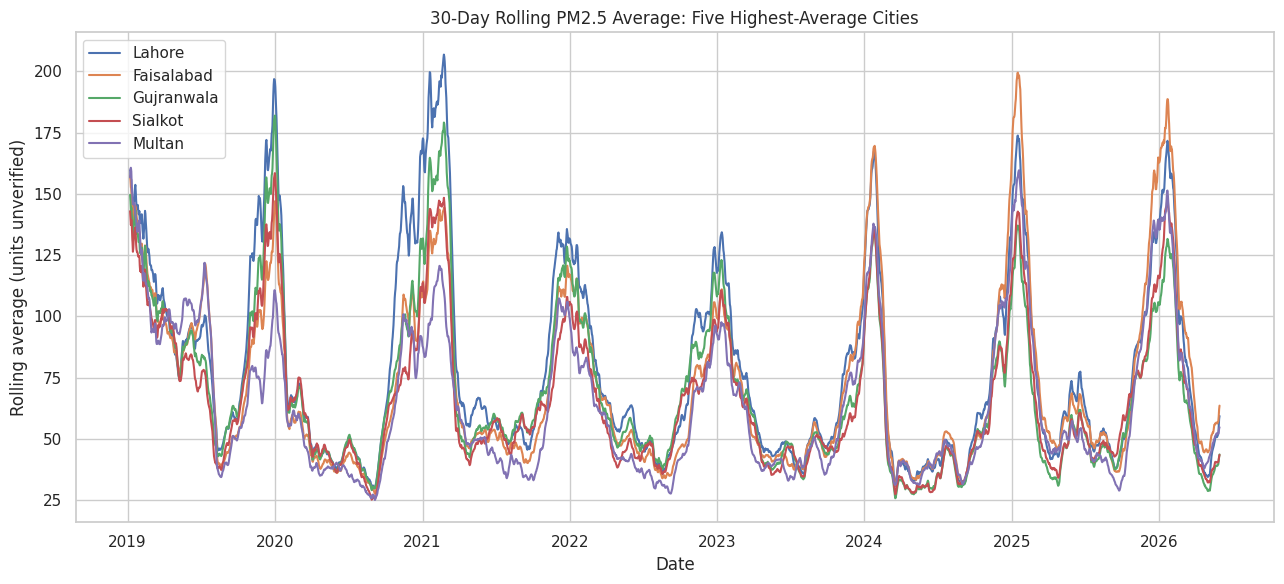

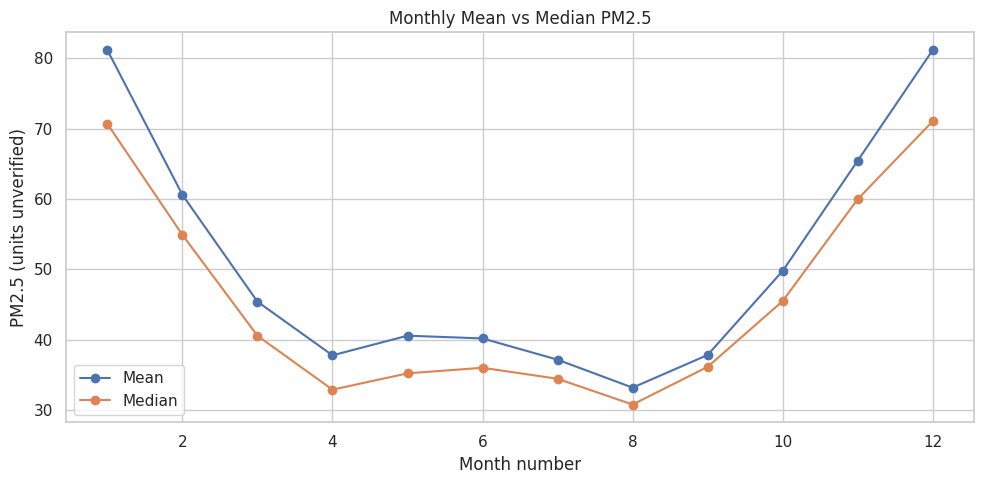

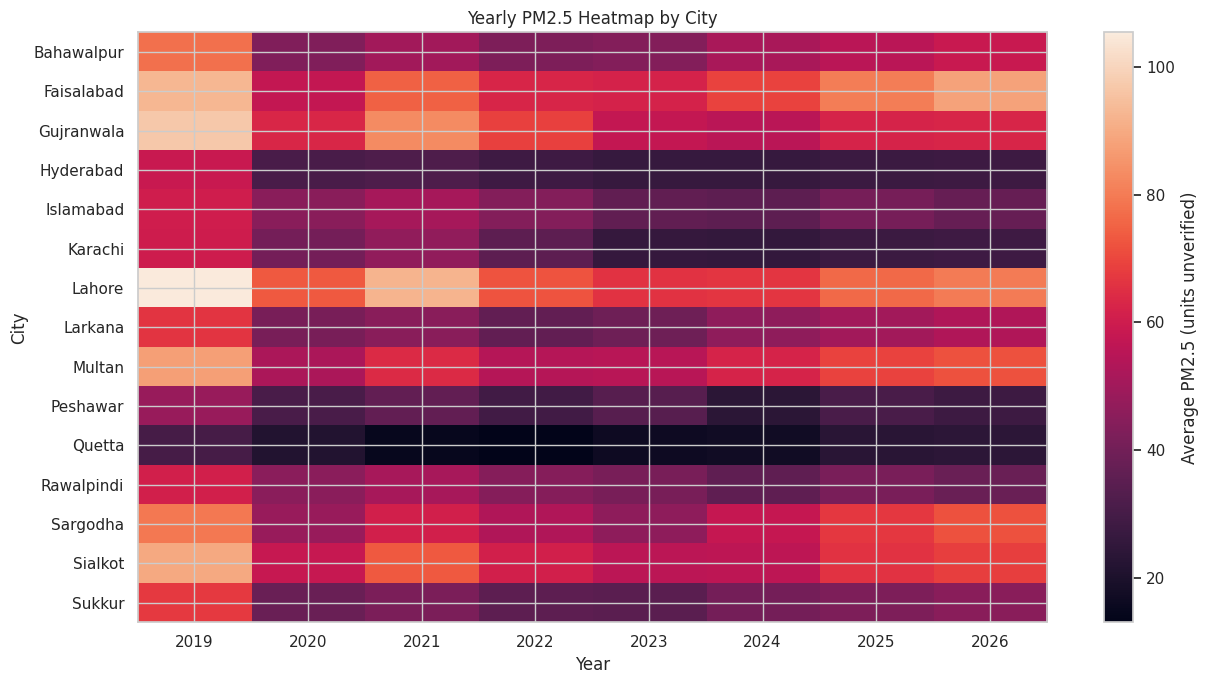

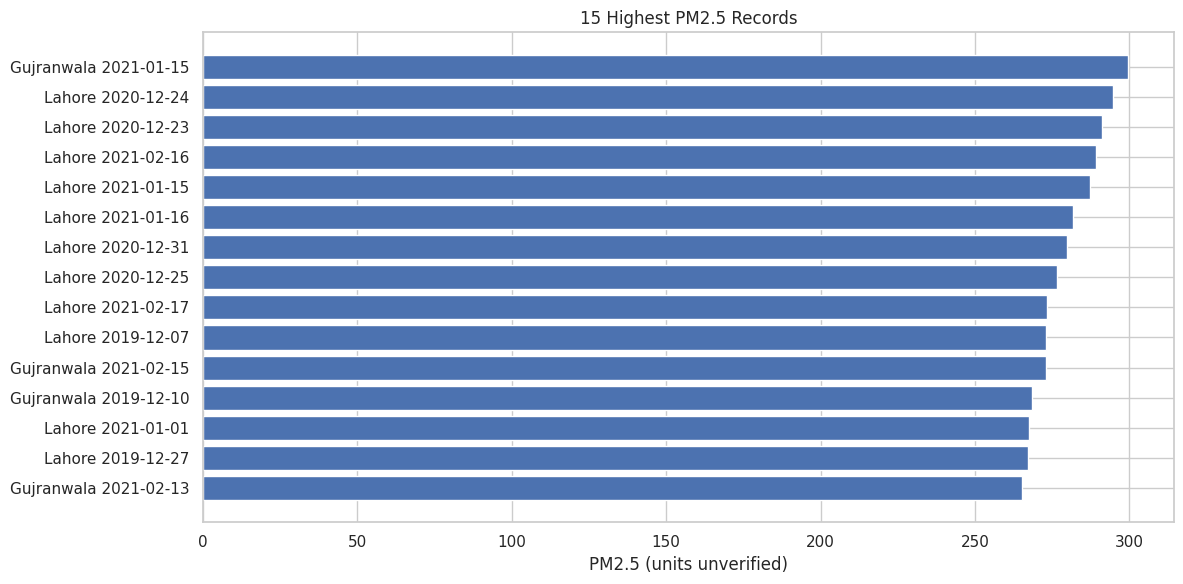

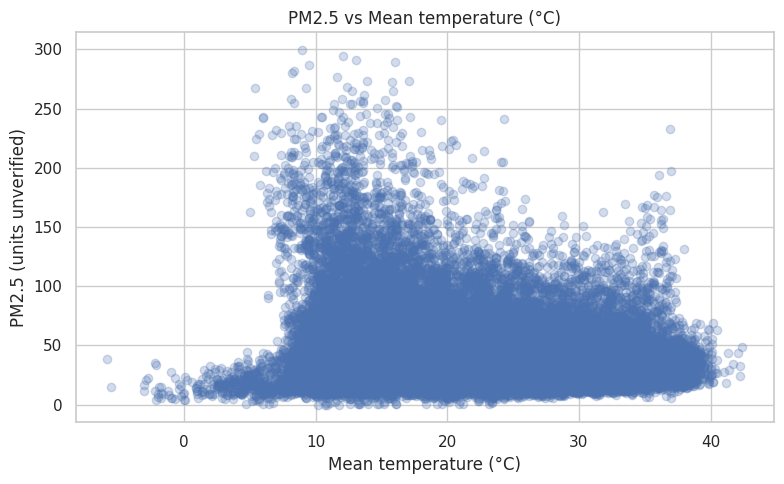

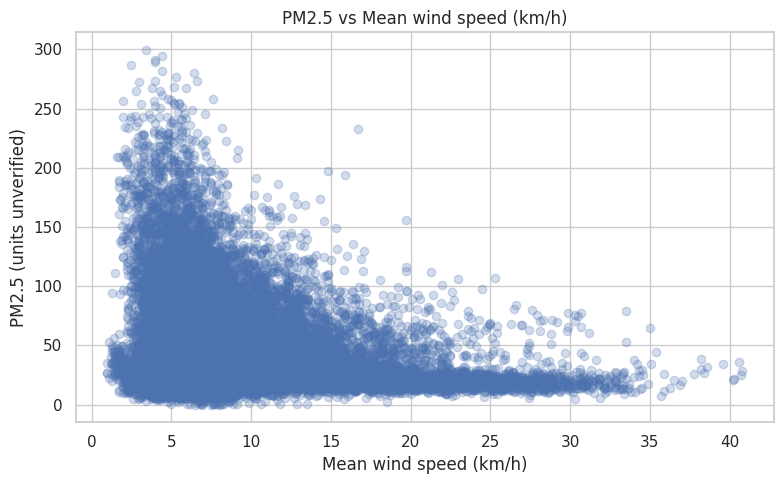

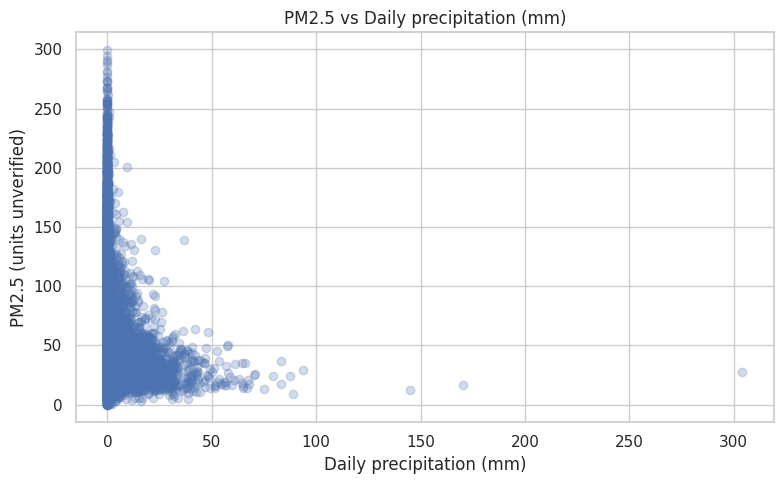


WEATHER CORRELATIONS (correlation does not prove causation)


,pm25,temperature_c,wind_speed_kmh,precipitation_mm
pm25,1.000,-0.327,-0.282,-0.097
temperature_c,-0.327,1.000,0.358,-0.008
wind_speed_kmh,-0.282,0.358,1.000,0.042
precipitation_mm,-0.097,-0.008,0.042,1.000



FINDINGS
1. Lahore has the highest average PM2.5 in this dataset (78.96, units unverified).
2. Quetta has the lowest average PM2.5 in this dataset (19.66, units unverified).
3. January has the highest monthly average across available records (81.17, units unverified).
4. August has the lowest monthly average across available records (33.21, units unverified).
5. These are descriptive patterns in the supplied dataset; source, units, and measurement methods must be verified before interpreting them as real-world pollution findings.

RECOMMENDATIONS
1. Verify the PM2.5 dataset publisher, collection method, and units.
2. Investigate unusual high values against the source before removing or changing them.
3. Use additional validated monitoring data to investigate city and seasonal patterns.
4. Treat weather correlations as associations, not proof that weather caused PM2.5 changes.
5. Compare with WHO guidelines only after confirming the pollutant units and matching averaging periods.
6. Do

# SmogWatch: PM2.5 Analysis Across Pakistani Cities

## Overview
This project explores 15 cities using 40,605 daily PM2.5 records
from 2019-01-01 through 2026-05-31.

## Data quality and provenance
- Rows analyzed: 40,605
- Cities: 15
- Missing PM2.5 values after cleaning: 0
- Duplicate city-date pairs after deduplication: 0
- PM2.5 source: **Not yet independently verified**
- PM2.5 units: **Not yet verified**
- Weather source: Open-Meteo Historical Weather API, if download succeeded.
- Weather records downloaded: 29,788

## Findings
1. Lahore has the highest average PM2.5 in this dataset (78.96, units unverified).
2. Quetta has the lowest average PM2.5 in this dataset (19.66, units unverified).
3. January has the highest monthly average across available records (81.17, units unverified).
4. August has the lowest monthly average across available records (33.21, units unverified).
5. These are descriptive patterns in the supplied dataset; source, units, and measurement methods must be verified before interpreting them as real-world pollution findings.

## Recommendations
1. Verify the PM2.5 dataset publisher, collection method, and units.
2. Investigate unusual high values against the source before removing or changing them.
3. Use additional validated monitoring data to investigate city and seasonal patterns.
4. Treat weather correlations as associations, not proof that weather caused PM2.5 changes.
5. Compare with WHO guidelines only after confirming the pollutant units and matching averaging periods.
6. Document data limitations and avoid presenting estimates as official measurements.

## Methods
Daily weather values were requested by city coordinates and merged with PM2.5 by city and date.
Charts and summary tables are generated from the available matched data.

## Limitations
The source and units of the supplied PM2.5 values have not yet been verified.
Weather data is an estimate for city coordinates and does not prove pollution causation.
Correlation does not establish causation. WHO comparisons are not included because units and
averaging compatibility have not been verified. The final year may be incomplete.
Review source provenance, API completeness, and missing weather rows before publication.



SMOGWATCH CELL FINISHED
Outputs folder: /content/SmogWatch/outputs
Processed data folder: /content/SmogWatch/data/processed
ZIP file: /content/SmogWatch/smogwatch_outputs.zip
Weather download errors: 4

Manual work still needed:
1. Verify PM2.5 source and units.
2. Review report and charts.
3. Only then decide whether WHO comparisons are valid.
4. Publish to GitHub and record the 2–3 minute demo.

To download the ZIP, run in another cell:
from google.colab import files
files.download('/content/SmogWatch/smogwatch_outputs.zip')


In [43]:

# ==============================================================
# SMOGWATCH - REMAINING PROJECT WORK IN ONE CELL
# Weather + merge + analysis + charts + findings + report + ZIP
# ==============================================================

!pip -q install requests plotly

import os, time, zipfile, warnings, requests
import numpy as np
import pandas as pd
import plotly.express as px
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")

# --------------------------------------------------------------
# 1. LOAD AND CLEAN EXISTING PM2.5 DATA
# --------------------------------------------------------------
if "df_clean" in globals():
    pm = df_clean.copy()
elif "df" in globals() and {"city", "date", "pm25"}.issubset(df.columns):
    pm = df.copy()
else:
    possible_paths = [
        "/content/SmogWatch/data/candidate_15_cities/pakistan_pm25_15cities_2019_2026.csv",
        "/content/SmogWatch/data/processed/smogwatch_pm25_cleaned.csv"
    ]
    existing_path = next((p for p in possible_paths if os.path.exists(p)), None)
    if existing_path is None:
        raise FileNotFoundError(
            "Could not find df_clean or the PM2.5 CSV. Run your earlier "
            "data-loading cell first."
        )
    pm = pd.read_csv(existing_path)

pm["date"] = pd.to_datetime(pm["date"], errors="coerce")
pm["pm25"] = pd.to_numeric(pm["pm25"], errors="coerce")
pm = pm.dropna(subset=["city", "date", "pm25"]).copy()
pm["city"] = pm["city"].astype(str).str.strip()
pm = pm[pm["pm25"] >= 0].copy()

# Keep one record per city/date if duplicates exist
pm = pm.sort_values("date").drop_duplicates(["city", "date"])

PROJECT = "/content/SmogWatch"
OUT = f"{PROJECT}/outputs"
PROCESSED = f"{PROJECT}/data/processed"
os.makedirs(OUT, exist_ok=True)
os.makedirs(PROCESSED, exist_ok=True)

print("PM2.5 DATA")
print("Rows:", len(pm))
print("Cities:", pm["city"].nunique())
print("Date range:", pm["date"].min().date(), "to", pm["date"].max().date())

# --------------------------------------------------------------
# 2. DOWNLOAD HISTORICAL WEATHER FROM OPEN-METEO
# --------------------------------------------------------------
coords = {
    "Bahawalpur": (29.3956, 71.6836),
    "Faisalabad": (31.4504, 73.1350),
    "Gujranwala": (32.1877, 74.1945),
    "Hyderabad": (25.3960, 68.3578),
    "Islamabad": (33.6844, 73.0479),
    "Karachi": (24.8607, 67.0011),
    "Lahore": (31.5204, 74.3587),
    "Larkana": (27.5580, 68.2120),
    "Multan": (30.1575, 71.5249),
    "Peshawar": (34.0151, 71.5249),
    "Quetta": (30.1798, 66.9750),
    "Rawalpindi": (33.5651, 73.0169),
    "Sargodha": (32.0836, 72.6711),
    "Sialkot": (32.4945, 74.5229),
    "Sukkur": (27.7052, 68.8574)
}

start = pm["date"].min().strftime("%Y-%m-%d")
end = pm["date"].max().strftime("%Y-%m-%d")
weather_parts = []
weather_errors = []

for city in sorted(pm["city"].unique()):
    if city not in coords:
        weather_errors.append(f"{city}: no coordinates configured")
        continue

    lat, lon = coords[city]
    params = {
        "latitude": lat,
        "longitude": lon,
        "start_date": start,
        "end_date": end,
        "daily": [
            "temperature_2m_mean",
            "wind_speed_10m_mean",
            "precipitation_sum"
        ],
        "timezone": "Asia/Karachi"
    }

    try:
        r = requests.get(
            "https://archive-api.open-meteo.com/v1/archive",
            params=params,
            timeout=90
        )
        r.raise_for_status()
        daily = r.json().get("daily", {})

        if not daily or "time" not in daily:
            raise ValueError("No daily weather returned")

        part = pd.DataFrame({
            "city": city,
            "date": pd.to_datetime(daily["time"]),
            "temperature_c": daily["temperature_2m_mean"],
            "wind_speed_kmh": daily["wind_speed_10m_mean"],
            "precipitation_mm": daily["precipitation_sum"]
        })
        weather_parts.append(part)
        print(f"Weather downloaded: {city} ({len(part)} days)")
        time.sleep(0.3)

    except Exception as e:
        weather_errors.append(f"{city}: {str(e)[:200]}")
        print(f"Weather download failed for {city}: {e}")

if weather_parts:
    weather = pd.concat(weather_parts, ignore_index=True)
    weather["date"] = pd.to_datetime(weather["date"])

    combined = pm.merge(
        weather, on=["city", "date"], how="left",
        validate="one_to_one"
    )
else:
    weather = pd.DataFrame()
    combined = pm.copy()
    for c in ["temperature_c", "wind_speed_kmh", "precipitation_mm"]:
        combined[c] = np.nan

combined["year"] = combined["date"].dt.year
combined["month"] = combined["date"].dt.month
combined["month_name"] = combined["date"].dt.strftime("%b")

combined.to_csv(f"{PROCESSED}/pm25_with_weather.csv", index=False)
weather.to_csv(f"{PROCESSED}/daily_weather.csv", index=False)

print("\nWeather rows:", len(weather))
print("PM2.5 rows matched:", len(combined))
print("Rows with missing temperature:", combined["temperature_c"].isna().sum())

# --------------------------------------------------------------
# 3. SUMMARY TABLES
# --------------------------------------------------------------
city_summary = combined.groupby("city")["pm25"].agg(
    count="count", mean="mean", median="median", minimum="min", maximum="max"
).round(2).sort_values("mean", ascending=False)

monthly_summary = combined.groupby("month")["pm25"].agg(
    mean="mean", median="median", count="count"
).round(2)

yearly_summary = combined.groupby("year")["pm25"].agg(
    mean="mean", median="median", count="count"
).round(2)

city_summary.to_csv(f"{OUT}/city_summary.csv")
monthly_summary.to_csv(f"{OUT}/monthly_summary.csv")
yearly_summary.to_csv(f"{OUT}/yearly_summary.csv")

print("\nAVERAGE PM2.5 BY CITY (dataset units unverified)")
display(city_summary)

print("\nAVERAGE PM2.5 BY MONTH")
display(monthly_summary)

print("\nAVERAGE PM2.5 BY YEAR")
display(yearly_summary)

# --------------------------------------------------------------
# 4. CREATE CHARTS
# --------------------------------------------------------------
chart_dir = f"{OUT}/charts"
os.makedirs(chart_dir, exist_ok=True)

def save_plot(filename):
    plt.tight_layout()
    plt.savefig(f"{chart_dir}/{filename}.png", dpi=160, bbox_inches="tight")
    plt.show()
    plt.close()

# Chart 1: City comparison
plt.figure(figsize=(12, 6))
city_summary["mean"].sort_values().plot(kind="barh")
plt.title("Average PM2.5 by City")
plt.xlabel("Average PM2.5 (units unverified)")
plt.ylabel("City")
save_plot("01_city_average")

# Chart 2: Monthly seasonal pattern
plt.figure(figsize=(10, 5))
monthly_summary["mean"].plot(marker="o")
plt.title("Average PM2.5 by Month")
plt.xlabel("Month number")
plt.ylabel("Average PM2.5 (units unverified)")
save_plot("02_monthly_pattern")

# Chart 3: Yearly averages
plt.figure(figsize=(10, 5))
yearly_summary["mean"].plot(marker="o")
plt.title("Yearly Average PM2.5")
plt.xlabel("Year")
plt.ylabel("Average PM2.5 (units unverified)")
save_plot("03_yearly_average")

# Chart 4: Monthly pattern by city
city_month = combined.pivot_table(
    index="city", columns="month", values="pm25", aggfunc="mean"
)
plt.figure(figsize=(13, 7))
plt.imshow(city_month, aspect="auto")
plt.colorbar(label="Average PM2.5 (units unverified)")
plt.xticks(range(len(city_month.columns)), city_month.columns)
plt.yticks(range(len(city_month.index)), city_month.index)
plt.title("Monthly PM2.5 Heatmap by City")
plt.xlabel("Month number")
plt.ylabel("City")
save_plot("04_city_month_heatmap")

# Chart 5: Distribution by city
plt.figure(figsize=(14, 6))
box_data = [
    combined.loc[combined["city"] == c, "pm25"].dropna().values
    for c in city_summary.index
]
plt.boxplot(box_data, tick_labels=city_summary.index, showfliers=False)
plt.xticks(rotation=70)
plt.title("PM2.5 Distribution by City")
plt.ylabel("PM2.5 (units unverified)")
save_plot("05_city_distribution")

# Chart 6: Daily data for the five highest-average cities
top_cities = city_summary.head(5).index.tolist()
top_daily = combined[combined["city"].isin(top_cities)].groupby(
    ["date", "city"], as_index=False
)["pm25"].mean()

plt.figure(figsize=(13, 6))
for city in top_cities:
    tmp = top_daily[top_daily["city"] == city]
    plt.plot(tmp["date"], tmp["pm25"].rolling(30, min_periods=7).mean(), label=city)
plt.title("30-Day Rolling PM2.5 Average: Five Highest-Average Cities")
plt.xlabel("Date")
plt.ylabel("Rolling average (units unverified)")
plt.legend()
save_plot("06_top_cities_trend")

# Chart 7: Monthly mean vs median
plt.figure(figsize=(10, 5))
plt.plot(monthly_summary.index, monthly_summary["mean"], marker="o", label="Mean")
plt.plot(monthly_summary.index, monthly_summary["median"], marker="o", label="Median")
plt.title("Monthly Mean vs Median PM2.5")
plt.xlabel("Month number")
plt.ylabel("PM2.5 (units unverified)")
plt.legend()
save_plot("07_mean_vs_median")

# Chart 8: Year-by-city heatmap
year_city = combined.pivot_table(
    index="city", columns="year", values="pm25", aggfunc="mean"
)
plt.figure(figsize=(13, 7))
plt.imshow(year_city, aspect="auto")
plt.colorbar(label="Average PM2.5 (units unverified)")
plt.xticks(range(len(year_city.columns)), year_city.columns)
plt.yticks(range(len(year_city.index)), year_city.index)
plt.title("Yearly PM2.5 Heatmap by City")
plt.xlabel("Year")
plt.ylabel("City")
save_plot("08_city_year_heatmap")

# Chart 9: Highest individual records
top_records = combined.nlargest(15, "pm25").copy()
plt.figure(figsize=(12, 6))
plt.barh(
    top_records["city"] + " " + top_records["date"].dt.strftime("%Y-%m-%d"),
    top_records["pm25"]
)
plt.title("15 Highest PM2.5 Records")
plt.xlabel("PM2.5 (units unverified)")
plt.gca().invert_yaxis()
save_plot("09_highest_records")

# Chart 10: Interactive Plotly chart
interactive = px.bar(
    city_summary.reset_index(),
    x="city", y="mean", color="mean",
    title="Interactive Average PM2.5 by City",
    labels={"city": "City", "mean": "Average PM2.5 (units unverified)"},
    hover_data={"mean": ":.2f"},
    color_continuous_scale="YlOrRd"
)
interactive.update_layout(xaxis_tickangle=-45, template="plotly_white")
interactive.write_html(f"{OUT}/interactive_city_chart.html")
interactive.show()

# Chart 11: Weather relationship charts, if weather is available
weather_cols = [
    "temperature_c", "wind_speed_kmh", "precipitation_mm"
]
weather_available = (
    combined[weather_cols].notna().any().any()
    and combined[weather_cols].notna().all(axis=1).sum() > 20
)

if weather_available:
    for col, label, filename in [
        ("temperature_c", "Mean temperature (°C)", "11_pm25_temperature"),
        ("wind_speed_kmh", "Mean wind speed (km/h)", "12_pm25_wind"),
        ("precipitation_mm", "Daily precipitation (mm)", "13_pm25_precipitation")
    ]:
        tmp = combined[["pm25", col]].dropna()
        plt.figure(figsize=(8, 5))
        plt.scatter(tmp[col], tmp["pm25"], alpha=0.25)
        plt.title(f"PM2.5 vs {label}")
        plt.xlabel(label)
        plt.ylabel("PM2.5 (units unverified)")
        save_plot(filename)

    weather_corr = combined[["pm25"] + weather_cols].corr().round(3)
    weather_corr.to_csv(f"{OUT}/weather_correlations.csv")
    print("\nWEATHER CORRELATIONS (correlation does not prove causation)")
    display(weather_corr)
else:
    weather_corr = pd.DataFrame()
    print("\nWeather analysis skipped: insufficient matched weather data.")

# --------------------------------------------------------------
# 5. FINDINGS AND RECOMMENDATIONS
# --------------------------------------------------------------
top_city = city_summary.index[0]
low_city = city_summary.index[-1]
month_names = {
    1:"January", 2:"February", 3:"March", 4:"April", 5:"May", 6:"June",
    7:"July", 8:"August", 9:"September", 10:"October", 11:"November", 12:"December"
}
high_month = int(monthly_summary["mean"].idxmax())
low_month = int(monthly_summary["mean"].idxmin())

findings = [
    f"{top_city} has the highest average PM2.5 in this dataset "
    f"({city_summary.loc[top_city, 'mean']:.2f}, units unverified).",
    f"{low_city} has the lowest average PM2.5 in this dataset "
    f"({city_summary.loc[low_city, 'mean']:.2f}, units unverified).",
    f"{month_names[high_month]} has the highest monthly average across available records "
    f"({monthly_summary.loc[high_month, 'mean']:.2f}, units unverified).",
    f"{month_names[low_month]} has the lowest monthly average across available records "
    f"({monthly_summary.loc[low_month, 'mean']:.2f}, units unverified).",
    "These are descriptive patterns in the supplied dataset; source, units, and measurement "
    "methods must be verified before interpreting them as real-world pollution findings."
]

recommendations = [
    "Verify the PM2.5 dataset publisher, collection method, and units.",
    "Investigate unusual high values against the source before removing or changing them.",
    "Use additional validated monitoring data to investigate city and seasonal patterns.",
    "Treat weather correlations as associations, not proof that weather caused PM2.5 changes.",
    "Compare with WHO guidelines only after confirming the pollutant units and matching averaging periods.",
    "Document data limitations and avoid presenting estimates as official measurements."
]

print("\nFINDINGS")
for i, item in enumerate(findings, 1):
    print(f"{i}. {item}")

print("\nRECOMMENDATIONS")
for i, item in enumerate(recommendations, 1):
    print(f"{i}. {item}")

with open(f"{OUT}/findings_and_recommendations.txt", "w", encoding="utf-8") as f:
    f.write("SMOGWATCH FINDINGS\n\n")
    f.write("\n".join(f"{i}. {x}" for i, x in enumerate(findings, 1)))
    f.write("\n\nRECOMMENDATIONS\n\n")
    f.write("\n".join(f"{i}. {x}" for i, x in enumerate(recommendations, 1)))

# --------------------------------------------------------------
# 6. CREATE PRELIMINARY PROJECT REPORT
# --------------------------------------------------------------
report = f"""# SmogWatch: PM2.5 Analysis Across Pakistani Cities

## Overview
This project explores {pm['city'].nunique()} cities using {len(pm):,} daily PM2.5 records
from {pm['date'].min().date()} through {pm['date'].max().date()}.

## Data quality and provenance
- Rows analyzed: {len(pm):,}
- Cities: {pm['city'].nunique()}
- Missing PM2.5 values after cleaning: {pm['pm25'].isna().sum()}
- Duplicate city-date pairs after deduplication: {pm.duplicated(['city','date']).sum()}
- PM2.5 source: **Not yet independently verified**
- PM2.5 units: **Not yet verified**
- Weather source: Open-Meteo Historical Weather API, if download succeeded.
- Weather records downloaded: {len(weather):,}

## Findings
""" + "\n".join(f"{i}. {x}" for i, x in enumerate(findings, 1)) + """

## Recommendations
""" + "\n".join(f"{i}. {x}" for i, x in enumerate(recommendations, 1)) + """

## Methods
Daily weather values were requested by city coordinates and merged with PM2.5 by city and date.
Charts and summary tables are generated from the available matched data.

## Limitations
The source and units of the supplied PM2.5 values have not yet been verified.
Weather data is an estimate for city coordinates and does not prove pollution causation.
Correlation does not establish causation. WHO comparisons are not included because units and
averaging compatibility have not been verified. The final year may be incomplete.
Review source provenance, API completeness, and missing weather rows before publication.
"""

with open(f"{OUT}/preliminary_report.md", "w", encoding="utf-8") as f:
    f.write(report)

display(Markdown(report))

# Save a record of weather download errors, if any
with open(f"{OUT}/weather_download_notes.txt", "w", encoding="utf-8") as f:
    f.write("Weather download notes\n\n")
    f.write("\n".join(weather_errors) if weather_errors else "No download errors recorded.")

# --------------------------------------------------------------
# 7. ZIP THE PROJECT OUTPUTS FOR DOWNLOAD
# --------------------------------------------------------------
zip_path = f"{PROJECT}/smogwatch_outputs.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for root, dirs, files in os.walk(OUT):
        for name in files:
            full = os.path.join(root, name)
            z.write(full, os.path.relpath(full, PROJECT))
    for name in ["pm25_with_weather.csv", "daily_weather.csv"]:
        full = f"{PROCESSED}/{name}"
        if os.path.exists(full):
            z.write(full, os.path.relpath(full, PROJECT))

print("\n" + "=" * 60)
print("SMOGWATCH CELL FINISHED")
print("Outputs folder:", OUT)
print("Processed data folder:", PROCESSED)
print("ZIP file:", zip_path)
print("Weather download errors:", len(weather_errors))
print("\nManual work still needed:")
print("1. Verify PM2.5 source and units.")
print("2. Review report and charts.")
print("3. Only then decide whether WHO comparisons are valid.")
print("4. Publish to GitHub and record the 2–3 minute demo.")
print("\nTo download the ZIP, run in another cell:")
print("from google.colab import files")
print("files.download('/content/SmogWatch/smogwatch_outputs.zip')")


In [44]:

from google.colab import files

files.download("/content/SmogWatch/smogwatch_outputs.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [45]:

import time
import requests
import pandas as pd
from pathlib import Path

# Project paths
PROJECT = Path("/content/SmogWatch")
PROCESSED = PROJECT / "data" / "processed"
PROCESSED.mkdir(parents=True, exist_ok=True)

# Four cities whose weather requests previously failed
CITY_COORDS = {
    "Rawalpindi": (33.5651, 73.0169),
    "Sargodha":   (32.0836, 72.6711),
    "Sialkot":    (32.4945, 74.5229),
    "Sukkur":     (27.7052, 68.8574)
}

weather_file = PROCESSED / "daily_weather.csv"
merged_file = PROCESSED / "pm25_with_weather.csv"

# Load the weather data already downloaded for the other cities
if weather_file.exists():
    weather_df = pd.read_csv(weather_file, parse_dates=["date"])
    print("Loaded existing weather data:", len(weather_df), "rows")
else:
    raise FileNotFoundError(
        f"Cannot find {weather_file}. "
        "Your previous weather download must be saved first."
    )

# Determine the date range from the existing PM2.5 data
if "df_clean" in globals():
    pm25_data = df_clean.copy()
elif merged_file.exists():
    pm25_data = pd.read_csv(merged_file, parse_dates=["date"])
else:
    raise NameError(
        "Cannot find df_clean or pm25_with_weather.csv. "
        "Please run the original data-loading cell first."
    )

pm25_data["date"] = pd.to_datetime(pm25_data["date"], errors="coerce")
start_date = pm25_data["date"].min().strftime("%Y-%m-%d")
end_date = pm25_data["date"].max().strftime("%Y-%m-%d")

session = requests.Session()
new_weather = []

for city, (lat, lon) in CITY_COORDS.items():
    # Skip cities that already have complete weather coverage
    existing = weather_df[weather_df["city"] == city].copy()

    if not existing.empty:
        existing["date"] = pd.to_datetime(existing["date"], errors="coerce")
        existing_dates = existing["date"].dt.strftime("%Y-%m-%d")
        covered = existing_dates.nunique()

        expected = (
            pd.date_range(start_date, end_date, freq="D").size
        )

        if covered >= expected:
            print(f"Skipping {city}: weather coverage already complete.")
            continue

    print(f"\nDownloading weather for {city}...")

    url = "https://archive-api.open-meteo.com/v1/archive"
    params = {
        "latitude": lat,
        "longitude": lon,
        "start_date": start_date,
        "end_date": end_date,
        "daily": (
            "temperature_2m_mean,"
            "precipitation_sum,"
            "wind_speed_10m_mean"
        ),
        "timezone": "Asia/Karachi"
    }

    success = False

    for attempt in range(1, 6):
        try:
            response = session.get(url, params=params, timeout=90)

            if response.status_code == 429 or response.status_code >= 500:
                wait = min(10 * attempt, 60)
                print(
                    f"Attempt {attempt}: HTTP {response.status_code}. "
                    f"Waiting {wait} seconds..."
                )
                time.sleep(wait)
                continue

            response.raise_for_status()
            result = response.json()
            daily = result.get("daily", {})

            if not daily.get("time"):
                raise ValueError("API returned no daily dates.")

            city_weather = pd.DataFrame({
                "date": pd.to_datetime(daily["time"]),
                "temperature_c": daily["temperature_2m_mean"],
                "precipitation_mm": daily["precipitation_sum"],
                "wind_speed_kmh": daily["wind_speed_10m_mean"]
            })

            city_weather["city"] = city
            new_weather.append(city_weather)

            print(f"Success: {len(city_weather)} daily records for {city}.")
            success = True
            break

        except Exception as e:
            wait = min(5 * attempt, 30)
            print(f"Attempt {attempt} failed: {e}")

            if attempt < 5:
                print(f"Retrying in {wait} seconds...")
                time.sleep(wait)

    if not success:
        print(f"WARNING: Could not download weather for {city}.")

    # Pause between cities to reduce rate-limit errors
    time.sleep(5)

# Combine newly downloaded records with existing records
if new_weather:
    new_weather_df = pd.concat(new_weather, ignore_index=True)

    weather_df["date"] = pd.to_datetime(
        weather_df["date"], errors="coerce"
    )
    weather_df = pd.concat(
        [weather_df, new_weather_df], ignore_index=True
    )

    # Prefer the newly retrieved record for duplicate city/date pairs
    weather_df = weather_df.drop_duplicates(
        subset=["city", "date"], keep="last"
    )

weather_df["date"] = pd.to_datetime(weather_df["date"], errors="coerce")
weather_df = weather_df.sort_values(["city", "date"])
weather_df.to_csv(weather_file, index=False)

# Merge weather onto the original PM2.5 observations
pm25_data["date"] = pd.to_datetime(pm25_data["date"], errors="coerce")

weather_columns = [
    "city", "date", "temperature_c",
    "precipitation_mm", "wind_speed_kmh"
]

available_columns = [
    col for col in weather_columns if col in weather_df.columns
]

merged = pm25_data.drop(
    columns=[
        "temperature_c", "precipitation_mm", "wind_speed_kmh"
    ],
    errors="ignore"
).merge(
    weather_df[available_columns],
    on=["city", "date"],
    how="left"
)

merged.to_csv(merged_file, index=False)

# Show final coverage
print("\n========== WEATHER RECOVERY REPORT ==========")
print("Weather records saved:", len(weather_df))
print("Merged PM2.5 records:", len(merged))

for city in CITY_COORDS:
    city_data = merged[merged["city"] == city]
    available = (
        city_data["temperature_c"].notna().sum()
        if "temperature_c" in city_data.columns else 0
    )
    print(f"{city}: {available}/{len(city_data)} days with temperature")

print(
    "\nMissing temperature values:",
    merged["temperature_c"].isna().sum()
)

print("\nUpdated files:")
print(weather_file)
print(merged_file)
print("\nDone. Check the coverage report above.")



Loaded existing weather data: 29788 rows

Success: 2708 daily records for Rawalpindi.

Success: 2708 daily records for Sargodha.

Success: 2708 daily records for Sialkot.

Success: 2708 daily records for Sukkur.

========== WEATHER RECOVERY REPORT ==========
Weather records saved: 40620
Merged PM2.5 records: 40605
Rawalpindi: 2707/2707 days with temperature
Sargodha: 2707/2707 days with temperature
Sialkot: 2707/2707 days with temperature
Sukkur: 2707/2707 days with temperature

Missing temperature values: 0

Updated files:
/content/SmogWatch/data/processed/daily_weather.csv
/content/SmogWatch/data/processed/pm25_with_weather.csv

Done. Check the coverage report above.


In [46]:

# SMOGWATCH — STEP 2: WEATHER CORRELATION ANALYSIS

import pandas as pd
from pathlib import Path

# 1. Load the updated dataset
file_path = Path(
    "/content/SmogWatch/data/processed/pm25_with_weather.csv"
)

df = pd.read_csv(file_path, parse_dates=["date"])

print("Dataset loaded successfully!")
print("Total records:", len(df))
print("Cities:", df["city"].nunique())
print("Date range:", df["date"].min().date(), "to", df["date"].max().date())

# 2. Select PM2.5 and weather variables
columns = [
    "pm25",
    "temperature_c",
    "wind_speed_kmh",
    "precipitation_mm"
]

missing_columns = [c for c in columns if c not in df.columns]

if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

# 3. Check missing values
print("\nMissing values:")
print(df[columns].isna().sum())

# 4. Calculate correlations using complete records
complete_data = df[columns].dropna()
correlations = complete_data.corr(method="pearson")

print("\nWEATHER CORRELATION MATRIX:")
display(correlations.round(3))

print("Complete records used:", len(complete_data))
print("Cities represented:", df.loc[complete_data.index, "city"].nunique())

# 5. Show each weather variable's relationship with PM2.5
print("\nPM2.5 CORRELATIONS:")

for variable in [
    "temperature_c",
    "wind_speed_kmh",
    "precipitation_mm"
]:
    value = correlations.loc["pm25", variable]

    if value > 0:
        direction = "positive"
    elif value < 0:
        direction = "negative"
    else:
        direction = "no linear correlation"

    print(f"PM2.5 vs {variable}: {value:.3f} ({direction})")

# 6. Save results
output_folder = Path("/content/SmogWatch/outputs")
output_folder.mkdir(parents=True, exist_ok=True)

output_file = output_folder / "weather_correlations.csv"
correlations.to_csv(output_file)

print("\nCorrelation results saved to:")
print(output_file)
print("\nSTEP 2 COMPLETED!")



Dataset loaded successfully!
Total records: 40605
Cities: 15
Date range: 2019-01-01 to 2026-05-31

Missing values:
pm25                0
temperature_c       0
wind_speed_kmh      0
precipitation_mm    0
dtype: int64

WEATHER CORRELATION MATRIX:


,pm25,temperature_c,wind_speed_kmh,precipitation_mm
pm25,1.000,-0.368,-0.299,-0.107
temperature_c,-0.368,1.000,0.345,-0.008
wind_speed_kmh,-0.299,0.345,1.000,0.059
precipitation_mm,-0.107,-0.008,0.059,1.000


Complete records used: 40605
Cities represented: 15

PM2.5 CORRELATIONS:
PM2.5 vs temperature_c: -0.368 (negative)
PM2.5 vs wind_speed_kmh: -0.299 (negative)
PM2.5 vs precipitation_mm: -0.107 (negative)

Correlation results saved to:
/content/SmogWatch/outputs/weather_correlations.csv

STEP 2 COMPLETED!


In [47]:

# SMOGWATCH — STEP 3: GENERATE FINAL REPORT

import pandas as pd
from pathlib import Path
from datetime import datetime

PROJECT = Path("/content/SmogWatch")
DATA_FILE = PROJECT / "data/processed/pm25_with_weather.csv"
OUTPUTS = PROJECT / "outputs"
OUTPUTS.mkdir(parents=True, exist_ok=True)

# Load updated data
df = pd.read_csv(DATA_FILE, parse_dates=["date"])
df["pm25"] = pd.to_numeric(df["pm25"], errors="coerce")
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month

# Summaries calculated from actual data
city = df.groupby("city")["pm25"].agg(["mean", "median", "max", "count"])
city = city.sort_values("mean", ascending=False)

monthly = df.groupby("month")["pm25"].mean().dropna()
yearly = df.groupby("year")["pm25"].mean().dropna()

corr = df[
    ["pm25", "temperature_c", "wind_speed_kmh", "precipitation_mm"]
].corr()

highest_city = city.index[0]
lowest_city = city.index[-1]
highest_month = int(monthly.idxmax())
lowest_month = int(monthly.idxmin())

month_names = {
    1:"January", 2:"February", 3:"March", 4:"April",
    5:"May", 6:"June", 7:"July", 8:"August",
    9:"September", 10:"October", 11:"November", 12:"December"
}

# Format city rankings
city_table = city.round(2).to_string()

# Format monthly trends
monthly_text = "\n".join(
    f"- {month_names[int(m)]}: {value:.2f} µg/m³"
    for m, value in monthly.items()
)

# Format yearly trends and mark incomplete 2026
yearly_lines = []
for y, value in yearly.items():
    note = " (partial year: through May)" if int(y) == 2026 else ""
    yearly_lines.append(f"- {int(y)}: {value:.2f} µg/m³{note}")
yearly_text = "\n".join(yearly_lines)

# Format weather correlations
weather_variables = {
    "temperature_c": "Temperature",
    "wind_speed_kmh": "Wind speed",
    "precipitation_mm": "Precipitation"
}
weather_text = "\n".join(
    f"- PM2.5 vs {label}: r = {corr.loc['pm25', col]:.3f}"
    for col, label in weather_variables.items()
)

report = f"""# SmogWatch: Daily PM2.5 Patterns in 15 Pakistani Cities

**Report generated:** {datetime.now().strftime("%Y-%m-%d")}

## 1. Project overview

SmogWatch analyses daily PM2.5 estimates for 15 Pakistani cities from
January 2019 through May 2026. It examines differences between cities,
monthly and yearly patterns, and associations between PM2.5 and weather.

## 2. Data source and methodology

The dataset description identifies the PM2.5 source as the Copernicus
Atmosphere Monitoring Service (CAMS), operated by ECMWF, accessed and
processed through Google Earth Engine. The dataset reports PM2.5 in
micrograms per cubic metre (µg/m³).

These values are model-derived estimates averaged over an approximately
20 km radius around each city's coordinates. They are not direct
ground-monitor measurements and should not be treated as regulatory-grade
observations.

Daily weather variables were retrieved separately from the Open-Meteo
historical archive API. Weather variables include mean temperature,
precipitation, and mean wind speed.

## 3. Data quality

- Records analysed: {len(df):,}
- Cities: {df["city"].nunique()}
- Period: {df["date"].min().date()} to {df["date"].max().date()}
- Missing PM2.5 values: {df["pm25"].isna().sum():,}
- Missing temperature values: {df["temperature_c"].isna().sum():,}
- Missing wind speed values: {df["wind_speed_kmh"].isna().sum():,}
- Missing precipitation values: {df["precipitation_mm"].isna().sum():,}

The current merged dataset has no missing values in the four analysis
variables. This describes completeness, not necessarily measurement accuracy.

## 4. City comparison

### Average PM2.5 by city

{city_table}

**Finding:** {highest_city} has the highest average PM2.5 in this dataset,
while {lowest_city} has the lowest. These are comparisons of model-derived
estimates, not official ground-monitor rankings.

## 5. Monthly patterns

{monthly_text}

**Finding:** {month_names[highest_month]} has the highest monthly average,
while {month_names[lowest_month]} has the lowest in this dataset.
Seasonal patterns may vary by city and year.

## 6. Yearly patterns

{yearly_text}

**Important:** 2026 covers only January through May, so its average should
not be compared directly with full-year averages as if coverage were equal.

## 7. Weather correlation analysis

{weather_text}

Negative correlations indicate that higher weather-variable values tend
to coincide with lower PM2.5 values in the combined data. Correlation does
not establish causation. These overall correlations may also reflect
seasonality, differences between cities, and other unmeasured factors.

## 8. Recommendations

1. Use validated ground-monitor data when making public-health or
   regulatory decisions.
2. Investigate unusually high estimated PM2.5 values rather than deleting
   them automatically.
3. Examine city-specific and seasonal patterns before drawing conclusions.
4. Treat weather correlations as associations, not proof of cause and effect.
5. Compare with WHO guidelines only with clear disclosure that the dataset
   contains model estimates and that averaging periods are compatible.
6. Document data sources, missing-value handling, and dataset limitations.

## 9. Limitations

- PM2.5 values are model-derived estimates, not direct station readings.
- City values represent an approximate spatial buffer, not every location
  within a city.
- Weather data come from a separate source and may have different spatial
  characteristics from the PM2.5 estimates.
- Overall correlations can hide differences between cities and seasons.
- This analysis alone cannot establish health effects or regulatory compliance.

## 10. Conclusion

SmogWatch provides a reproducible exploratory analysis of daily PM2.5
estimates across 15 Pakistani cities. It identifies city-level differences,
monthly and yearly patterns, and associations with weather. The findings
are useful for exploration and hypothesis generation, while conclusions
about actual exposure and regulatory compliance require validated monitoring
data and careful interpretation.
"""

report_path = OUTPUTS / "final_report.md"
report_path.write_text(report, encoding="utf-8")

print("STEP 3 COMPLETED!")
print("Report saved to:", report_path)
print("\nPreview:")
print(report[:6000])


STEP 3 COMPLETED!
Report saved to: /content/SmogWatch/outputs/final_report.md

Preview:
# SmogWatch: Daily PM2.5 Patterns in 15 Pakistani Cities

**Report generated:** 2026-10-21

## 1. Project overview

SmogWatch analyses daily PM2.5 estimates for 15 Pakistani cities from
January 2019 through May 2026. It examines differences between cities,
monthly and yearly patterns, and associations between PM2.5 and weather.

## 2. Data source and methodology

The dataset description identifies the PM2.5 source as the Copernicus
Atmosphere Monitoring Service (CAMS), operated by ECMWF, accessed and
processed through Google Earth Engine. The dataset reports PM2.5 in
micrograms per cubic metre (µg/m³).

These values are model-derived estimates averaged over an approximately
20 km radius around each city's coordinates. They are not direct
ground-monitor measurements and should not be treated as regulatory-grade
observations.

Daily weather variables were retrieved separately from the Open-Meteo
histo

In [48]:

# SMOGWATCH — STEP 4: CHART CHECK + WHO GUIDELINE CONTEXT

import pandas as pd
from pathlib import Path
from IPython.display import display

PROJECT = Path("/content/SmogWatch")
DATA_FILE = PROJECT / "data/processed/pm25_with_weather.csv"
CHART_DIR = PROJECT / "outputs/charts"
OUTPUT_DIR = PROJECT / "outputs"

# 1. Check existing charts without rerunning them
charts = list(CHART_DIR.glob("*.png")) if CHART_DIR.exists() else []

print("EXISTING STATIC CHARTS:", len(charts))
for chart in sorted(charts):
    print("-", chart.name)

interactive_chart = OUTPUT_DIR / "interactive_city_chart.html"
print(
    "\nInteractive Plotly chart:",
    "Available" if interactive_chart.exists() else "Not found at expected path"
)

if len(charts) < 10:
    print("\nNote: Fewer than 10 PNG charts were found. We will check this before publishing.")

# 2. Load updated data
df = pd.read_csv(DATA_FILE, parse_dates=["date"])
df["pm25"] = pd.to_numeric(df["pm25"], errors="coerce")
df = df.dropna(subset=["city", "date", "pm25"]).copy()
df["year"] = df["date"].dt.year

# 3. Annual means by city and year
annual = (
    df.groupby(["city", "year"])["pm25"]
      .mean()
      .reset_index(name="annual_mean_pm25")
)

# 4. Summarize full years only: 2019–2025
# 2026 is partial, so exclude it from annual-mean comparison.
full_years = annual[annual["year"].between(2019, 2025)].copy()

annual_summary = (
    full_years.groupby("city")["annual_mean_pm25"]
    .agg(["mean", "max", "count"])
    .reset_index()
    .rename(columns={
        "mean": "average_of_annual_means_2019_2025",
        "max": "highest_annual_mean_2019_2025",
        "count": "full_years_available"
    })
    .sort_values("average_of_annual_means_2019_2025", ascending=False)
)

# 5. Indicative daily comparison with WHO 24-hour guideline
# Only compare daily estimates; do not label this official compliance.
daily = df.groupby(["city", "date"])["pm25"].mean().reset_index()

daily_summary = (
    daily.groupby("city")
    .agg(
        daily_observations=("pm25", "count"),
        daily_mean_pm25=("pm25", "mean"),
        days_above_15=("pm25", lambda s: (s > 15).sum())
    )
    .reset_index()
)

daily_summary["percent_days_above_15"] = (
    100 * daily_summary["days_above_15"] /
    daily_summary["daily_observations"]
)

# 6. Save results
annual_file = OUTPUT_DIR / "annual_city_means_2019_2025.csv"
daily_file = OUTPUT_DIR / "indicative_who_daily_comparison.csv"

annual_summary.to_csv(annual_file, index=False)
daily_summary.to_csv(daily_file, index=False)

print("\nANNUAL MEAN SUMMARY (FULL YEARS 2019–2025)")
display(annual_summary.round(2))

print("\nINDICATIVE DAILY COMPARISON WITH WHO 15 µg/m³ GUIDELINE")
display(daily_summary.round(2))

print("\nWHO guideline context:")
print("- Annual mean: 5 µg/m³")
print("- 24-hour mean: 15 µg/m³")
print(
    "Caution: these are model-derived estimates, not direct ground-monitor "
    "measurements. The comparison is indicative and does not establish "
    "regulatory compliance."
)

print("\nSaved:")
print(annual_file)
print(daily_file)
print("\nSTEP 4 CHECK COMPLETED!")



EXISTING STATIC CHARTS: 12
- 01_city_average.png
- 02_monthly_pattern.png
- 03_yearly_average.png
- 04_city_month_heatmap.png
- 05_city_distribution.png
- 06_top_cities_trend.png
- 07_mean_vs_median.png
- 08_city_year_heatmap.png
- 09_highest_records.png
- 11_pm25_temperature.png
- 12_pm25_wind.png
- 13_pm25_precipitation.png

Interactive Plotly chart: Available

ANNUAL MEAN SUMMARY (FULL YEARS 2019–2025)


,city,average_of_annual_means_2019_2025,highest_annual_mean_2019_2025,full_years_available
6,Lahore,78.91,105.44,7
1,Faisalabad,71.33,93.11,7
2,Gujranwala,69.60,97.00,7
13,Sialkot,65.80,89.65,7
8,Multan,63.54,87.66,7
12,Sargodha,58.99,79.10,7
0,Bahawalpur,52.12,77.69,7
7,Larkana,46.42,66.19,7
11,Rawalpindi,45.93,61.35,7
4,Islamabad,44.81,60.60,7



INDICATIVE DAILY COMPARISON WITH WHO 15 µg/m³ GUIDELINE


,city,daily_observations,daily_mean_pm25,days_above_15,percent_days_above_15
0,Bahawalpur,2707,52.49,2654,98.04
1,Faisalabad,2707,72.27,2701,99.78
2,Gujranwala,2707,69.22,2696,99.59
3,Hyderabad,2707,32.64,2419,89.36
4,Islamabad,2707,44.40,2679,98.97
5,Karachi,2707,37.01,2539,93.79
6,Lahore,2707,78.96,2700,99.74
7,Larkana,2707,46.81,2651,97.93
8,Multan,2707,64.02,2698,99.67
9,Peshawar,2707,33.00,2558,94.50



WHO guideline context:
- Annual mean: 5 µg/m³
- 24-hour mean: 15 µg/m³
Caution: these are model-derived estimates, not direct ground-monitor measurements. The comparison is indicative and does not establish regulatory compliance.

Saved:
/content/SmogWatch/outputs/annual_city_means_2019_2025.csv
/content/SmogWatch/outputs/indicative_who_daily_comparison.csv

STEP 4 CHECK COMPLETED!


In [50]:

from pathlib import Path
import zipfile
import os

PROJECT = Path("/content/SmogWatch")
OUTPUTS = PROJECT / "outputs"
ZIP_PATH = PROJECT / "smogwatch_final.zip"

# Ensure important deliverables exist before packaging
required_files = [
    PROJECT / "data/processed/pm25_cleaned.csv",
    PROJECT / "data/processed/daily_weather.csv",
    PROJECT / "data/processed/pm25_with_weather.csv",
    OUTPUTS / "weather_correlations.csv",
    OUTPUTS / "annual_city_means_2019_2025.csv",
    OUTPUTS / "indicative_who_daily_comparison.csv",
    OUTPUTS / "final_report.md",
]

missing = [str(p) for p in required_files if not p.exists()]

if missing:
    print("Some expected files are missing:")
    for path in missing:
        print("-", path)
    raise FileNotFoundError(
        "Please check the missing paths before creating the final ZIP."
    )

# Package project deliverables; skip the ZIP itself and temporary files.
included = []
with zipfile.ZipFile(
    ZIP_PATH, "w", compression=zipfile.ZIP_DEFLATED
) as archive:
    for folder in [PROJECT / "data", OUTPUTS]:
        for path in folder.rglob("*"):
            if not path.is_file():
                continue
            if path == ZIP_PATH or "__pycache__" in path.parts:
                continue
            if path.suffix in [".pyc", ".tmp"]:
                continue

            archive.write(path, arcname=str(path.relative_to(PROJECT)))
            included.append(path)

print("STEP 5 COMPLETED!")
print("ZIP:", ZIP_PATH)
print("Files packaged:", len(included))
print("ZIP size (MB):", round(ZIP_PATH.stat().st_size / (1024 * 1024), 2))

print("\nImportant deliverables:")
for path in required_files:
    print("✓", path.relative_to(PROJECT))

# Download the ZIP to your computer
from google.colab import files
files.download(str(ZIP_PATH))


Some expected files are missing:
- /content/SmogWatch/data/processed/pm25_cleaned.csv


FileNotFoundError: Please check the missing paths before creating the final ZIP.

In [51]:

from pathlib import Path
import pandas as pd
import zipfile
from google.colab import files

PROJECT = Path("/content/SmogWatch")
PROCESSED = PROJECT / "data/processed"
OUTPUTS = PROJECT / "outputs"
ZIP_PATH = PROJECT / "smogwatch_final.zip"

PROCESSED.mkdir(parents=True, exist_ok=True)
OUTPUTS.mkdir(parents=True, exist_ok=True)

# 1. Recreate the cleaned PM2.5 file from the merged dataset
merged_file = PROCESSED / "pm25_with_weather.csv"
clean_file = PROCESSED / "pm25_cleaned.csv"

if not clean_file.exists() and merged_file.exists():
    df = pd.read_csv(merged_file)
    columns = ["city", "date", "pm25"]

    if all(col in df.columns for col in columns):
        df[columns].to_csv(clean_file, index=False)
        print("Recreated:", clean_file)
    else:
        print("Merged file is missing expected PM2.5 columns.")

# 2. List the expected deliverables
expected = [
    PROCESSED / "pm25_cleaned.csv",
    PROCESSED / "daily_weather.csv",
    PROCESSED / "pm25_with_weather.csv",
    OUTPUTS / "weather_correlations.csv",
    OUTPUTS / "annual_city_means_2019_2025.csv",
    OUTPUTS / "indicative_who_daily_comparison.csv",
    OUTPUTS / "final_report.md",
]

print("\nFile availability:")
for path in expected:
    print(("FOUND  " if path.exists() else "MISSING"), path.name)

# 3. Package all available data and output files
# Missing optional files will not stop packaging.
with zipfile.ZipFile(
    ZIP_PATH, "w", compression=zipfile.ZIP_DEFLATED
) as archive:
    for folder in [PROJECT / "data", OUTPUTS]:
        if not folder.exists():
            continue

        for path in folder.rglob("*"):
            if not path.is_file():
                continue
            if path == ZIP_PATH:
                continue
            if path.suffix in [".pyc", ".tmp"]:
                continue

            archive.write(path, arcname=str(path.relative_to(PROJECT)))

# 4. Verify ZIP
with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    contents = archive.namelist()

print("\nSTEP 5 PACKAGING COMPLETED")
print("ZIP file:", ZIP_PATH)
print("Files included:", len(contents))
print("ZIP size (MB):", round(ZIP_PATH.stat().st_size / (1024 * 1024), 2))

# 5. Download
files.download(str(ZIP_PATH))


Recreated: /content/SmogWatch/data/processed/pm25_cleaned.csv

File availability:
FOUND   pm25_cleaned.csv
FOUND   daily_weather.csv
FOUND   pm25_with_weather.csv
FOUND   weather_correlations.csv
FOUND   annual_city_means_2019_2025.csv
FOUND   indicative_who_daily_comparison.csv
FOUND   final_report.md

STEP 5 PACKAGING COMPLETED
ZIP file: /content/SmogWatch/smogwatch_final.zip
Files included: 30
ZIP size (MB): 4.82


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [52]:

from pathlib import Path
import zipfile

project = Path("/content/SmogWatch")
readme_path = project / "README.md"
zip_path = project / "smogwatch_final.zip"

readme_text = r"""# SmogWatch: Air Quality Analysis in Pakistan

## Project Overview
SmogWatch explores daily PM2.5 estimates across 15 Pakistani cities
from January 2019 to May 2026, alongside historical weather data.

## Objectives
- Compare pollution estimates across cities.
- Explore monthly and yearly trends.
- Analyze relationships between PM2.5 and weather variables.
- Visualize findings using charts and an interactive visualization.

## Tools
Python, Pandas, Matplotlib, Seaborn, Plotly, Google Colab.

## Data Sources
Air quality: CAMS/ECMWF estimates processed through Google Earth Engine.
Weather: Open-Meteo historical archive.

The processed dataset contains 40,605 records across 15 cities.
Fifteen source rows with missing PM2.5 values were excluded.

## Key Findings
- Lahore mean PM2.5 estimate: approximately 78.96 µg/m³.
- Quetta mean PM2.5 estimate: approximately 19.66 µg/m³.
- PM2.5 vs temperature Pearson correlation: -0.368.
- PM2.5 vs wind speed Pearson correlation: -0.299.
- PM2.5 vs precipitation Pearson correlation: -0.107.

Correlations do not establish causation.

## Important Limitations
PM2.5 values are model-derived estimates, not direct ground-monitor
measurements. WHO comparisons are indicative and should not be used
alone to establish regulatory compliance or individual health risk.
The 2026 data covers January through May only.

## Outputs
City summaries, seasonal and yearly trends, heatmaps, distribution
charts, weather correlations, WHO guideline context, an interactive
chart, and a final Markdown report.

## Future Improvements
Add ground-monitor data, build a Power BI dashboard, and explore
pollution forecasting.

## Author
Muhammad Shayan
"""

readme_path.write_text(readme_text, encoding="utf-8")
print("Created:", readme_path)

# Update the ZIP with the README and all current project files
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as archive:
    for folder in [project / "data", project / "outputs"]:
        if folder.exists():
            for file in folder.rglob("*"):
                if file.is_file() and file.suffix not in [".pyc", ".tmp"]:
                    archive.write(file, file.relative_to(project))
    archive.write(readme_path, "README.md")

print("Updated ZIP:", zip_path)
print("README size:", readme_path.stat().st_size, "bytes")


Created: /content/SmogWatch/README.md
Updated ZIP: /content/SmogWatch/smogwatch_final.zip
README size: 1685 bytes


In [53]:

from google.colab import files
files.download("/content/SmogWatch/smogwatch_final.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>